# Baseline CNN — Meme MRI, standart 5-fold protokolü

**Modeller:** ResNet34, DenseNet121, EfficientNet-B0, MobileNetV2, InceptionV3
**Bu grubun reçetesi:** Yalnızca sınıflandırma başı eğitilir (backbone donuk). Augmentation ve regularization yok. Adam, lr 1e-3.

Bu notebook, dört grup notebook'undan biridir (`1_baseline_cnn`, `2_baseline_vit`, `3_optimized_cnn`, `4_optimized_vit`). Dördünün kodu birebir aynıdır; tek fark ilk hücredeki `GROUP` satırıdır. Bu sayede şunlar bütün gruplarda aynı kalır:
- **Veri bölünmesi:** Her fold'da 16.826 train / 3.594 validation / 3.604 test (`holdout5` modu). Fold ataması `folds_holdout5.csv` dosyasına bir kez yazılır ve bütün notebook'lar aynı dosyayı kullanır.
- **Eğitim koşulları:** 10 epoch, etkin batch 32, 224×224 giriş, en iyi epoch en düşük validation loss'a göre seçilir, seed 42.
- **Çıktılar:** Her model ve her fold için train/validation/test confusion matrix'i, ROC eğrisi ve metrik grafiği, accuracy ve loss eğrileri, metrik tablosu.

**Nasıl çalıştırılır:** Colab'da GPU seçip bütün hücreleri sırayla çalıştır. Oturum kesilirse yeniden çalıştırman yeterli; biten fold'lar atlanır. Süre yetmezse ilk hücrede `MODELS = ["ViT-L-16"]` gibi tek bir model verebilirsin.
Dört notebook bittikten sonra `5_tum_sonuclar.ipynb` ile bütün sonuçları tek bir Excel dosyasında birleştir.


In [1]:
# ======================= 1. AYARLAR =======================
from pathlib import Path

# Bu notebook'un deney grubu. DEĞİŞTİRME: her grubun kendi notebook'u var.
GROUP = "baseline_cnn"

# None = grubun tüm modelleri. Colab süresi yetmezse tek tek ver: ["ViT-L-16"]
MODELS = None

# True yapılırsa MODELS'te verilen modellerin BU GRUPTAKİ eski sonuçları silinir ve sadece onlar yeniden eğitilir.
# Örnek: MODELS = ["InceptionV3"]; RERUN = True   → iş bitince ikisini de eski haline (None / False) getir.
RERUN = False

# Swin-T eğitilir ve kaydedilir; makaleye girip girmeyeceği ayrı karar
INCLUDE_SWIN = True

# ---------------- 5 katlı çapraz doğrulama (TÜM gruplarda aynı fold'lar) ----------------
# Kaggle train (16.826) + validation (3.594) = 20.420 görüntü havuzu oluşturulur, test (3.604) hiç karışmaz.
#   "kfold"    : Stratified 5-fold. Her fold: ~16.336 train / ~4.084 validation. Her görüntü tam 1 kez validation olur.
#   "holdout5" : 5 tekrarlı stratified hold-out. Her fold: TAM 16.826 train / 3.594 validation (Kaggle sayılarıyla birebir),
#                ama validation kümeleri fold'lar arasında örtüşebilir (klasik k-fold değildir; makalede böyle yazılmalı).
CV_MODE = "holdout5"   # hocanın istediği: her fold Kaggle sayılarıyla birebir aynı
N_FOLDS = 5
FOLD_SEED = 42        # fold ataması bir kez üretilir, folds.csv'ye yazılır; tüm gruplar ve modeller aynı dosyayı kullanır
TRAIN_SEED = 42       # her fold'da model eğitimi için aynı seed

# Veri kaynağı: "kaggle" (önerilen; train/validation/test klasörleriyle iner) veya "rar"
DATA_SOURCE = "kaggle"
KAGGLE_ID = "abenjelloun/breast-mri-tumor-classification-dataset"
RAR_SOURCE = "/content/drive/MyDrive/data_set_zip/breast_mri_dataset.rar"   # rar'da validation klasörü de olmalı

EXPECTED_COUNTS = {"train": 16826, "val": 3594, "test": 3604}
STRICT_COUNTS = True                  # sayılar tutmazsa dur

# Sonuçlar Drive'a yazılır (Colab kapanınca kaybolmasın, kaldığı yerden devam edebilsin)
OUTPUT_ROOT = Path("/content/drive/MyDrive/breast_mri_standard_results")

SHOW_PLOTS = True                     # grafikleri hücre altında da göster

# ---------------- Tüm gruplarda ORTAK protokol ----------------
COMMON = dict(
    img_size=224,
    epochs=10,                 # her run sabit 10 epoch, early stopping yok
    batch_size=32,             # fiziksel batch
    accum_steps=1,             # bellek yetmezse batch_size=16, accum_steps=2 (etkin batch yine 32)
    num_workers=2,
    amp=True,                  # mixed precision (hız için, tüm gruplarda açık)
    select_by="val_loss",      # en iyi epoch: en düşük validation loss (tüm gruplarda aynı)
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

# ---------------- Grup reçeteleri ----------------
# Baseline: yalnızca sınıflandırma başı eğitilir, augmentation/regularization yok.
# Optimize: CNN ve ViT için AYNI reçete; tek fark hangi katmanların açıldığı (FT_SCOPE).
RECIPES = {
    "baseline": dict(optimizer="adam", lr=1e-3, weight_decay=0.0, scheduler=None,
                     augment=False, label_smoothing=0.0, head_dropout=0.0, grad_clip=None),
    "optimized": dict(optimizer="adamw", lr=1e-4, weight_decay=1e-4, scheduler="cosine", eta_min=1e-6,
                      augment=True, label_smoothing=0.1, head_dropout=0.3, grad_clip=1.0),
}
FT_SCOPE = {
    ("baseline", "cnn"): "head",
    ("baseline", "vit"): "head",
    ("optimized", "cnn"): "full",      # tüm katmanlar
    ("optimized", "vit"): "partial",   # ViT: son 4 encoder bloğu + son LayerNorm + head; Swin-T: son stage + norm + head
}
VIT_LAST_BLOCKS = 4

AUGMENT = dict(rotation=15, hflip_p=0.5, vflip_p=0.5, translate=0.05, scale=(0.95, 1.05),
               brightness=0.15, contrast=0.15, erasing_p=0.15)

CNN_MODELS = ["ResNet34", "DenseNet121", "EfficientNet-B0", "MobileNetV2", "InceptionV3"]
VIT_MODELS = ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32"] + (["Swin-T"] if INCLUDE_SWIN else [])


In [2]:
# ======================= 2. KURULUM + VERİ + SIZINTI KONTROLÜ =======================
import os, gc, json, time, random, shutil, subprocess, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

# ---------- Veriyi getir ----------
if DATA_SOURCE == "kaggle":
    import kagglehub   # gerekirse: kagglehub.login()
    RAW_ROOT = Path(kagglehub.dataset_download(KAGGLE_ID))
else:
    shutil.copy2(RAR_SOURCE, "/content/dataset.rar")
    subprocess.run(["unrar", "x", "-o+", "/content/dataset.rar", "/content/dataset_raw/"], check=True)
    RAW_ROOT = Path("/content/dataset_raw")

SPLIT_ALIASES = {"train": {"train", "training"},
                 "val": {"val", "valid", "validation"},
                 "test": {"test", "testing"}}

def find_split_dirs(root):
    """train/val/test klasörlerini (içinde Benign/Malignant olan) otomatik bulur."""
    for d in sorted([root] + [p for p in root.rglob("*") if p.is_dir()]):
        children = {c.name.lower(): c for c in d.iterdir() if c.is_dir()}
        found = {}
        for split, aliases in SPLIT_ALIASES.items():
            for a in aliases:
                if a in children:
                    cls = {c.name.lower() for c in children[a].iterdir() if c.is_dir()}
                    if {"benign", "malignant"} <= cls:
                        found[split] = children[a]
        if len(found) == 3:
            return found
    raise RuntimeError(f"{root} altında train/validation/test (Benign/Malignant) yapısı bulunamadı.")

SPLIT_DIRS = find_split_dirs(RAW_ROOT)
print({k: str(v) for k, v in SPLIT_DIRS.items()})

def make_tf(augment):
    c, a = COMMON, AUGMENT
    if not augment:
        return transforms.Compose([transforms.Resize((c["img_size"], c["img_size"])),
                                   transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"])])
    return transforms.Compose([
        transforms.Resize((c["img_size"], c["img_size"])),
        transforms.RandomRotation(a["rotation"]),
        transforms.RandomHorizontalFlip(a["hflip_p"]),
        transforms.RandomVerticalFlip(a["vflip_p"]),
        transforms.RandomAffine(0, translate=(a["translate"], a["translate"]), scale=a["scale"]),
        transforms.ColorJitter(brightness=a["brightness"], contrast=a["contrast"]),
        transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"]),
        transforms.RandomErasing(p=a["erasing_p"], scale=(0.02, 0.08), ratio=(0.3, 3.3)),
    ])

EVAL_TF = make_tf(False)
DS = {s: datasets.ImageFolder(SPLIT_DIRS[s], transform=EVAL_TF) for s in ["train", "val", "test"]}

# ---------- Kontroller ----------
for s, d in DS.items():
    assert [c.lower() for c in d.classes] == ["benign", "malignant"], d.classes
CLASS_NAMES = DS["train"].classes            # Malignant = 1 = pozitif sınıf
counts = pd.DataFrame({s: pd.Series(d.targets).value_counts().sort_index().values for s, d in DS.items()},
                      index=CLASS_NAMES)
counts.loc["Toplam"] = counts.sum()
display(counts)
mismatch = {s: (len(DS[s]), n) for s, n in EXPECTED_COUNTS.items() if len(DS[s]) != n}
if mismatch:
    msg = f"Görüntü sayıları beklenenle tutmuyor (gerçek, beklenen): {mismatch}"
    if STRICT_COUNTS: raise ValueError(msg)
    print("UYARI:", msg)
counts.to_csv(OUTPUT_ROOT / "split_counts.csv")

# ---------- Train+Val havuzu ve 5 fold (bir kez üretilir, sonra hep aynısı kullanılır) ----------
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

class ListDataset(torch.utils.data.Dataset):
    def __init__(self, samples, transform):
        self.samples, self.transform = samples, transform
        self.targets = [y for _, y in samples]
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        path, y = self.samples[i]
        return self.transform(datasets.folder.default_loader(path)), y

POOL = DS["train"].samples + DS["val"].samples          # 20.420 görüntü
POOL_SRC = ["train"] * len(DS["train"]) + ["val"] * len(DS["val"])
pool_y = np.array([y for _, y in POOL])
rel = [str(Path(p).relative_to(RAW_ROOT)) for p, _ in POOL]

FOLDS_FILE = OUTPUT_ROOT / f"folds_{CV_MODE}.csv"
if FOLDS_FILE.exists():
    fdf = pd.read_csv(FOLDS_FILE)
    assert fdf["file"].tolist() == rel, "folds dosyasındaki görüntü listesi mevcut veriyle aynı değil!"
    print("Mevcut fold ataması yüklendi:", FOLDS_FILE.name)
else:
    if CV_MODE == "kfold":
        splitter = StratifiedKFold(N_FOLDS, shuffle=True, random_state=FOLD_SEED)
    elif CV_MODE == "holdout5":
        splitter = StratifiedShuffleSplit(N_FOLDS, test_size=EXPECTED_COUNTS["val"], random_state=FOLD_SEED)
    else:
        raise ValueError(CV_MODE)
    fdf = pd.DataFrame({"file": rel, "label": pool_y, "kaggle_split": POOL_SRC})
    for k, (_, va) in enumerate(splitter.split(np.zeros(len(pool_y)), pool_y), 1):
        col = np.array(["train"] * len(pool_y), dtype=object); col[va] = "val"; fdf[f"fold{k}"] = col
    fdf.to_csv(FOLDS_FILE, index=False)
    print("Yeni fold ataması üretildi ve kaydedildi:", FOLDS_FILE)

FOLD_IDX = {k: (np.where(fdf[f"fold{k}"] == "train")[0], np.where(fdf[f"fold{k}"] == "val")[0])
            for k in range(1, N_FOLDS + 1)}
fold_table = pd.DataFrame([{"Fold": k, "Train": len(tr), "Train Benign": int((pool_y[tr] == 0).sum()),
                            "Train Malignant": int((pool_y[tr] == 1).sum()), "Validation": len(va),
                            "Val Benign": int((pool_y[va] == 0).sum()), "Val Malignant": int((pool_y[va] == 1).sum()),
                            "Test": len(DS["test"])} for k, (tr, va) in FOLD_IDX.items()])
fold_table.to_csv(OUTPUT_ROOT / f"fold_counts_{CV_MODE}.csv", index=False)
display(fold_table)   # makaledeki veri seti tablosu bu tablodan alınmalı

# ---------- Sızıntı kontrolü: split'ler arası aynı / çok benzer görüntü ----------
def leakage_check(max_hamming=2):
    """(1) train+val havuzu ile test arasında, (2) havuzun kendi içinde (fold'lar arası sızıntı)
    birebir aynı (md5) ve çok benzer (pHash) görüntüleri sayar."""
    try:
        import imagehash
    except ImportError:
        subprocess.run(["pip", "install", "-q", "imagehash"], check=True); import imagehash
    from PIL import Image
    groups = {"trainval": [p for p, _ in POOL], "test": [p for p, _ in DS["test"].samples]}
    md5 = {g: [hashlib.md5(open(p, "rb").read()).hexdigest() for p in ps] for g, ps in groups.items()}
    ph = {g: np.array([int(str(imagehash.phash(Image.open(p).convert("L"))), 16) for p in ps], dtype=np.uint64)
          for g, ps in groups.items()}
    POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    def near_count(A, B, same=False):
        Ab = A.view(np.uint8).reshape(-1, 8); hits = 0
        for i, h in enumerate(B):
            d = POP[Ab ^ np.array([h], dtype=np.uint64).view(np.uint8)].sum(1)
            if same: d[i] = 255
            hits += int((d <= max_hamming).any())
        return hits
    tv, te = set(md5["trainval"]), md5["test"]
    rows = [
        {"Karşılaştırma": "test ↔ train+val", "Tür": "birebir aynı (md5)", "Etkilenen test görüntüsü": sum(h in tv for h in te)},
        {"Karşılaştırma": "test ↔ train+val", "Tür": f"çok benzer (pHash ≤ {max_hamming})", "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["test"])},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": "birebir aynı (md5)",
         "Etkilenen test görüntüsü": int(pd.Series(md5["trainval"]).duplicated(keep=False).sum())},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": f"çok benzer (pHash ≤ {max_hamming})",
         "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["trainval"], same=True)},
    ]
    df = pd.DataFrame(rows).rename(columns={"Etkilenen test görüntüsü": "Eşleşmesi olan görüntü sayısı"})
    df.to_csv(OUTPUT_ROOT / "leakage_check.csv", index=False)
    return df

if not (OUTPUT_ROOT / "leakage_check.csv").exists():
    print("Sızıntı kontrolü yapılıyor (bir kez, birkaç dakika sürer)...")
    display(leakage_check())
else:
    display(pd.read_csv(OUTPUT_ROOT / "leakage_check.csv"))


Mounted at /content/drive
Device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition


100%|██████████| 411M/411M [00:03<00:00, 136MB/s]

Extracting files...


{'train': '/root/.cache/kagglehub/datasets/abenjelloun/breast-mri-tumor-classification-dataset/versions/1/breast_mri_dataset/train', 'val': '/root/.cache/kagglehub/datasets/abenjelloun/breast-mri-tumor-classification-dataset/versions/1/breast_mri_dataset/val', 'test': '/root/.cache/kagglehub/datasets/abenjelloun/breast-mri-tumor-classification-dataset/versions/1/breast_mri_dataset/test'}


,train,val,test
Benign,8413,1797,1802
Malignant,8413,1797,1802
Toplam,16826,3594,3604


Yeni fold ataması üretildi ve kaydedildi: /content/drive/MyDrive/breast_mri_standard_results/folds_holdout5.csv


,Fold,Train,Train Benign,Train Malignant,Validation,Val Benign,Val Malignant,Test
0,1,16826,8413,8413,3594,1797,1797,3604
1,2,16826,8413,8413,3594,1797,1797,3604
2,3,16826,8413,8413,3594,1797,1797,3604
3,4,16826,8413,8413,3594,1797,1797,3604
4,5,16826,8413,8413,3594,1797,1797,3604


Sızıntı kontrolü yapılıyor (bir kez, birkaç dakika sürer)...


,Karşılaştırma,Tür,Eşleşmesi olan görüntü sayısı
0,test ↔ train+val,birebir aynı (md5),0
1,test ↔ train+val,çok benzer (pHash ≤ 2),2820
2,train+val kendi içinde,birebir aynı (md5),0
3,train+val kendi içinde,çok benzer (pHash ≤ 2),15827


In [3]:
# ======================= 3. MODEL, EĞİTİM, DEĞERLENDİRME =======================
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def worker_init(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

FAMILY = {**{m: "cnn" for m in CNN_MODELS}, **{m: "vit" for m in ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32", "Swin-T"]}}
HEAD_MODULE = {"ResNet34": "fc", "InceptionV3": "fc", "DenseNet121": "classifier", "EfficientNet-B0": "classifier",
               "MobileNetV2": "classifier", "ViT-B-16": "heads", "ViT-B-32": "heads", "ViT-L-16": "heads",
               "ViT-L-32": "heads", "Swin-T": "head"}

def new_head(in_features, p):
    return nn.Sequential(nn.Dropout(p), nn.Linear(in_features, 2))

def build_model(name, head_dropout):
    W = "IMAGENET1K_V1"
    if name == "ResNet34":
        m = models.resnet34(weights=W); m.fc = new_head(m.fc.in_features, head_dropout)
    elif name == "DenseNet121":
        m = models.densenet121(weights=W); m.classifier = new_head(m.classifier.in_features, head_dropout)
    elif name == "EfficientNet-B0":
        m = models.efficientnet_b0(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "MobileNetV2":
        m = models.mobilenet_v2(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "InceptionV3":
        m = models.inception_v3(weights=W); m.aux_logits = False; m.AuxLogits = None
        m.dropout = nn.Identity()   # InceptionV3'ün kendi Dropout(0.5)'i kaldırılır; head dropout diğer modellerle aynı (RECIPES)
        m.fc = new_head(m.fc.in_features, head_dropout)
    elif name.startswith("ViT"):
        m = getattr(models, name.lower().replace("-", "_"))(weights=W)
        m.heads.head = new_head(m.heads.head.in_features, head_dropout)
    elif name == "Swin-T":
        m = models.swin_t(weights=W); m.head = new_head(m.head.in_features, head_dropout)
    else:
        raise ValueError(name)
    return m

def configure_trainable(m, name, scope):
    """scope: head | partial | full"""
    for p in m.parameters():
        p.requires_grad = (scope == "full")
    if scope == "full":
        return
    prefixes = [HEAD_MODULE[name] + "."]
    if scope == "partial":
        if name.startswith("ViT"):
            n = len(m.encoder.layers)
            prefixes += [f"encoder.layers.encoder_layer_{i}." for i in range(n - VIT_LAST_BLOCKS, n)] + ["encoder.ln."]
        elif name == "Swin-T":
            prefixes += ["features.7.", "norm."]
        else:
            raise ValueError("partial yalnızca ViT/Swin için tanımlı")
    for pn, p in m.named_parameters():
        if pn.startswith(tuple(prefixes)):
            p.requires_grad = True

def set_train_mode(m):
    """Eğitilebilir parametresi olmayan (dondurulmuş) modüller eval modunda kalır:
    BatchNorm istatistikleri güncellenmez, donmuş bloklarda dropout/stochastic depth çalışmaz."""
    m.train()
    for mod in m.modules():
        ps = list(mod.parameters(recurse=True))
        if ps and not any(p.requires_grad for p in ps):
            mod.eval()

def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16,
                          enabled=COMMON["amp"] and device.type == "cuda")

EVAL_LOSS = nn.CrossEntropyLoss()   # değerlendirme kaybı tüm gruplarda düz CE (label smoothing yok) -> karşılaştırılabilir

def train_one_epoch(m, loader, opt, loss_fn, scaler, grad_clip):
    set_train_mode(m); opt.zero_grad(set_to_none=True)
    params = [p for p in m.parameters() if p.requires_grad]
    acc_steps = COMMON["accum_steps"]; tot_loss = correct = n = 0
    for step, (x, y) in enumerate(loader, 1):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x); loss = loss_fn(out, y)
        scaler.scale(loss / acc_steps).backward()
        if step % acc_steps == 0 or step == len(loader):
            if grad_clip:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, grad_clip)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        tot_loss += EVAL_LOSS(out.float(), y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
    return tot_loss / n, correct / n

@torch.inference_mode()
def predict(m, loader):
    m.eval(); ys, probs, losses = [], [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x)
        out = out.float()
        losses.append(EVAL_LOSS(out, y).item() * y.size(0))
        ys.append(y.cpu().numpy()); probs.append(out.softmax(1)[:, 1].cpu().numpy())
    y = np.concatenate(ys); prob = np.concatenate(probs)
    return y, prob, sum(losses) / len(y)

def metrics(y, prob, loss=None):
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sd = lambda a, b: a / b if b else 0.0
    prec, rec = sd(tp, tp + fp), sd(tp, tp + fn)
    return {"N": int(len(y)), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Accuracy": sd(tp + tn, len(y)), "Precision": prec, "Recall (Sensitivity)": rec,
            "Specificity": sd(tn, tn + fp), "F1-Score": sd(2 * prec * rec, prec + rec),
            "ROC-AUC": roc_auc_score(y, prob), "Loss": loss}

def save_fig(path):
    plt.tight_layout(); plt.savefig(path, dpi=300)
    plt.show() if SHOW_PLOTS else None
    plt.close()

def plot_curves(hist, title, out_dir):
    ep = hist["Epoch"]
    for key in ["Accuracy", "Loss"]:
        plt.figure(figsize=(7, 4.5))
        plt.plot(ep, hist[f"Train {key}"], "o-", label="Train")
        plt.plot(ep, hist[f"Validation {key}"], "s-", label="Validation")
        plt.xlabel("Epoch"); plt.ylabel(key); plt.title(f"{title} – {key}"); plt.grid(alpha=.3); plt.legend()
        save_fig(out_dir / f"{key.lower()}_curve.png")

def plot_split(y, prob, mtr, title, split, out_dir):
    cm = np.array([[mtr["TN"], mtr["FP"]], [mtr["FN"], mtr["TP"]]])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Tahmin"); plt.ylabel("Gerçek"); plt.title(f"{title} – {split} (N={mtr['N']})")
    save_fig(out_dir / f"cm_{split.lower()}.png")
    fpr, tpr, _ = roc_curve(y, prob)
    plt.figure(figsize=(5.5, 4.5)); plt.plot(fpr, tpr, label=f"AUC = {mtr['ROC-AUC']:.4f}"); plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title(f"{title} – {split} ROC")
    plt.legend(); plt.grid(alpha=.3); save_fig(out_dir / f"roc_{split.lower()}.png")

def plot_metric_bars(mtr, title, split, out_dir):
    keys = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC"]
    vals = [mtr[k] for k in keys]
    plt.figure(figsize=(8, 4.5)); bars = plt.bar(["Accuracy", "Precision", "Recall", "Specificity", "F1", "AUC"], vals)
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
    plt.ylim(0, 1.05); plt.ylabel("Değer"); plt.title(f"{title} – {split} Metrics"); plt.grid(axis="y", alpha=.3)
    save_fig(out_dir / f"metrics_{split.lower()}.png")

def run_one(name, fold, kind):
    seed = TRAIN_SEED
    family = FAMILY[name]; R = RECIPES[kind]; scope = FT_SCOPE[(kind, family)]
    out_dir = OUTPUT_ROOT / CV_MODE / GROUP / name / f"Fold_{fold}"
    done = out_dir / "result.json"
    if done.exists():
        print(f"[atlandı] {name} Fold {fold} zaten tamam"); return json.loads(done.read_text())
    out_dir.mkdir(parents=True, exist_ok=True); seed_all(seed)

    g = torch.Generator(); g.manual_seed(seed)
    pin = device.type == "cuda"; nw = COMMON["num_workers"]; bs = COMMON["batch_size"]
    tr_idx, va_idx = FOLD_IDX[fold]
    sub = lambda idx, tf: ListDataset([POOL[i] for i in idx], tf)
    tr_loader = DataLoader(sub(tr_idx, make_tf(R["augment"])), bs, shuffle=True, generator=g,
                           worker_init_fn=worker_init, num_workers=nw, pin_memory=pin)
    eval_loaders = {"Train": DataLoader(sub(tr_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Validation": DataLoader(sub(va_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Test": DataLoader(DS["test"], bs, shuffle=False, num_workers=nw, pin_memory=pin)}

    m = build_model(name, R["head_dropout"]); configure_trainable(m, name, scope); m.to(device)
    params = [p for p in m.parameters() if p.requires_grad]
    n_tr, n_all = sum(p.numel() for p in params), sum(p.numel() for p in m.parameters())
    opt = (torch.optim.AdamW if R["optimizer"] == "adamw" else torch.optim.Adam)(params, lr=R["lr"], weight_decay=R["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=COMMON["epochs"], eta_min=R["eta_min"]) if R["scheduler"] == "cosine" else None
    loss_fn = nn.CrossEntropyLoss(label_smoothing=R["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=COMMON["amp"] and device.type == "cuda")

    hist = {k: [] for k in ["Epoch", "LR", "Train Loss", "Train Accuracy", "Validation Loss", "Validation Accuracy"]}
    best = (float("inf"), -1.0, None, 0); t0 = time.time()
    for ep in range(1, COMMON["epochs"] + 1):
        lr_now = opt.param_groups[0]["lr"]
        tl, ta = train_one_epoch(m, tr_loader, opt, loss_fn, scaler, R["grad_clip"])
        yv, pv, vl = predict(m, eval_loaders["Validation"]); va = ((pv >= .5).astype(int) == yv).mean()
        if sched: sched.step()
        for k, v in zip(hist, [ep, lr_now, tl, ta, vl, va]): hist[k].append(v)
        key = (vl, -va) if COMMON["select_by"] == "val_loss" else (-va, vl)
        if key < (best[0], best[1]):
            best = (key[0], key[1], {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}, ep)
        print(f"{name} | Fold {fold} | Epoch {ep:02d}/{COMMON['epochs']} | "
              f"Train loss {tl:.4f} acc {ta:.4f} | Val loss {vl:.4f} acc {va:.4f}")
    train_time = time.time() - t0
    m.load_state_dict(best[2]); best_epoch = best[3]
    pd.DataFrame(hist).to_csv(out_dir / "history.csv", index=False)
    title = f"{name} – Fold {fold}"
    plot_curves(hist, title, out_dir)

    res = {"CV": CV_MODE, "Group": GROUP, "Model": name, "Fold": fold, "Seed": seed, "Best Epoch": best_epoch,
           "Trainable Params": n_tr, "Total Params": n_all, "Train Time (s)": round(train_time, 1), "Splits": {}}
    for split, loader in eval_loaders.items():
        y, prob, loss = predict(m, loader); mtr = metrics(y, prob, loss)
        res["Splits"][split] = mtr
        plot_split(y, prob, mtr, title, split, out_dir)
        plot_metric_bars(mtr, title, split, out_dir)
        if split == "Test":   # örnek bazlı tahminler (McNemar vb. istatistiksel test için)
            pd.DataFrame({"file": [p for p, _ in DS["test"].samples], "y": y, "prob_malignant": prob,
                          "pred": (prob >= .5).astype(int)}).to_csv(out_dir / "test_predictions.csv", index=False)
    fold_df = pd.DataFrame(res["Splits"]).T
    fold_df.to_csv(out_dir / "metrics.csv")
    print(f"{name} – Fold {fold} sonuçları (best epoch = {best_epoch}):")
    display(fold_df)
    done.write_text(json.dumps(res, indent=2))
    print(f"✓ {name} Fold {fold}: best epoch {best_epoch} | Test acc {res['Splits']['Test']['Accuracy']:.4f}")
    del m, opt, best; gc.collect(); torch.cuda.empty_cache()
    return res

METRIC_COLS = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC", "Loss"]

def results_to_frames(results):
    rows = [{"CV": r["CV"], "Group": r["Group"], "Model": r["Model"], "Fold": r["Fold"], "Best Epoch": r["Best Epoch"],
             "Split": s, **mtr} for r in results for s, mtr in r["Splits"].items()]
    per_run = pd.DataFrame(rows)
    g = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS]
    summary = g.mean().add_suffix(" mean").join(g.std(ddof=1).add_suffix(" std")).reset_index()
    article = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS[:-1]].agg(
        lambda s: f"{100*s.mean():.2f} ± {100*s.std(ddof=1):.2f}").reset_index()
    return per_run, summary, article


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 230MB/s]


ResNet34 | Fold 1 | Epoch 01/10 | Train loss 0.5644 acc 0.7006 | Val loss 0.5149 acc 0.7501
ResNet34 | Fold 1 | Epoch 02/10 | Train loss 0.4918 acc 0.7625 | Val loss 0.4822 acc 0.7685
ResNet34 | Fold 1 | Epoch 03/10 | Train loss 0.4627 acc 0.7847 | Val loss 0.4922 acc 0.7596
ResNet34 | Fold 1 | Epoch 04/10 | Train loss 0.4482 acc 0.7903 | Val loss 0.4481 acc 0.7944
ResNet34 | Fold 1 | Epoch 05/10 | Train loss 0.4316 acc 0.8043 | Val loss 0.4378 acc 0.7999
ResNet34 | Fold 1 | Epoch 06/10 | Train loss 0.4218 acc 0.8103 | Val loss 0.4342 acc 0.7966
ResNet34 | Fold 1 | Epoch 07/10 | Train loss 0.4171 acc 0.8103 | Val loss 0.4365 acc 0.7952
ResNet34 | Fold 1 | Epoch 08/10 | Train loss 0.4065 acc 0.8169 | Val loss 0.4196 acc 0.8091
ResNet34 | Fold 1 | Epoch 09/10 | Train loss 0.4030 acc 0.8160 | Val loss 0.4119 acc 0.8116
ResNet34 | Fold 1 | Epoch 10/10 | Train loss 0.3984 acc 0.8216 | Val loss 0.4089 acc 0.8102


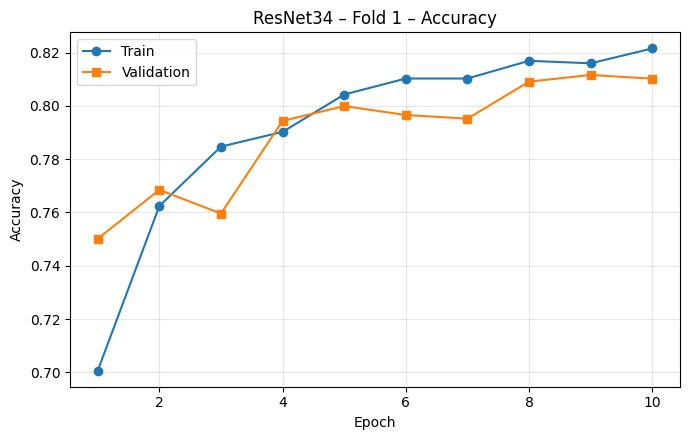

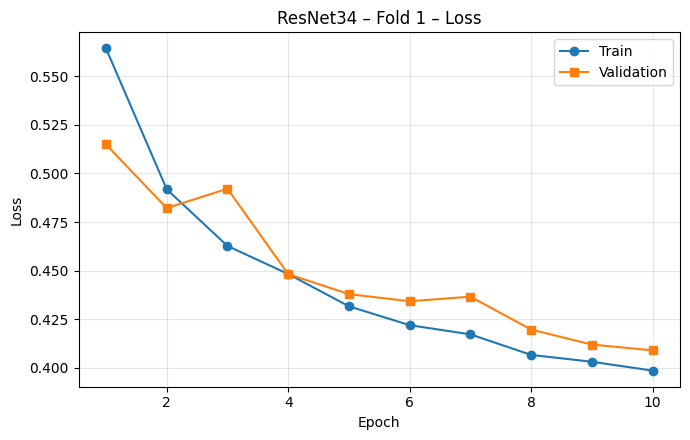

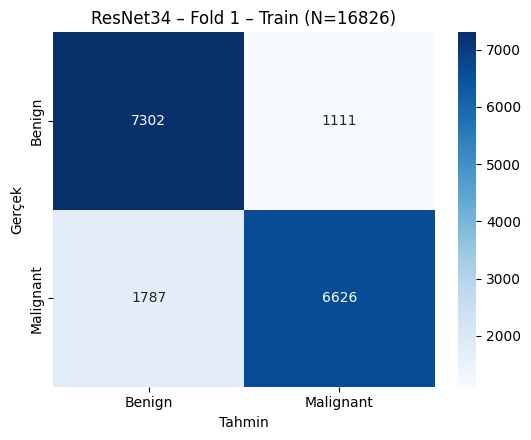

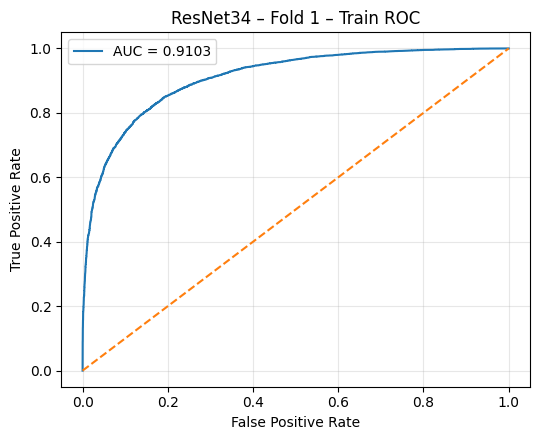

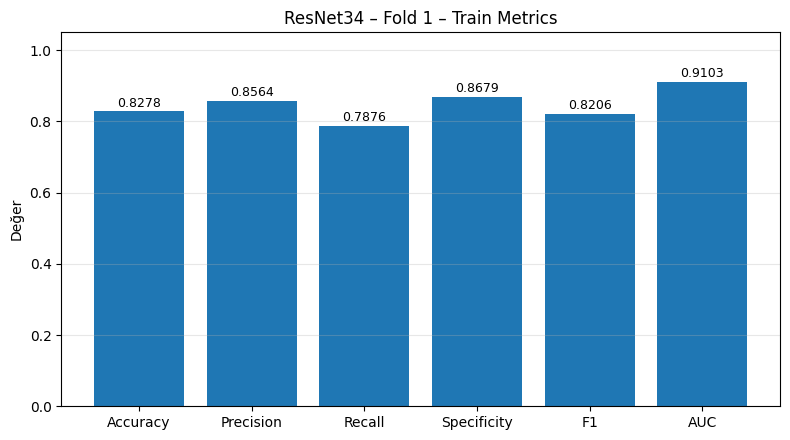

...

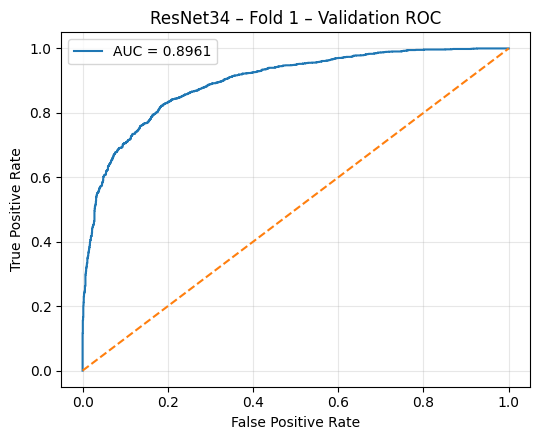

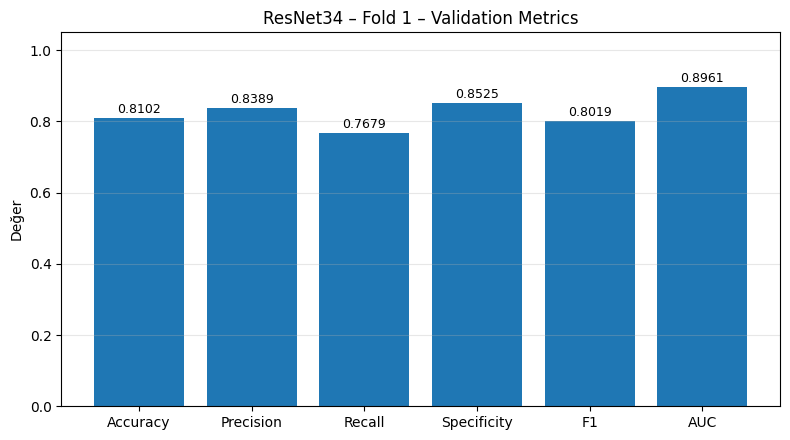

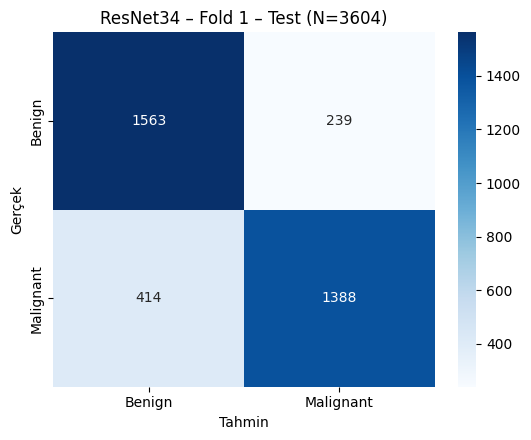

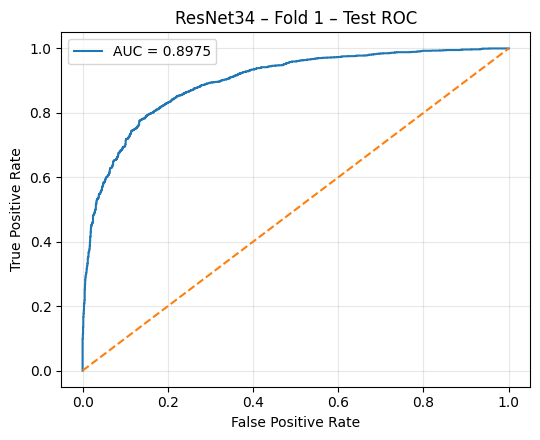

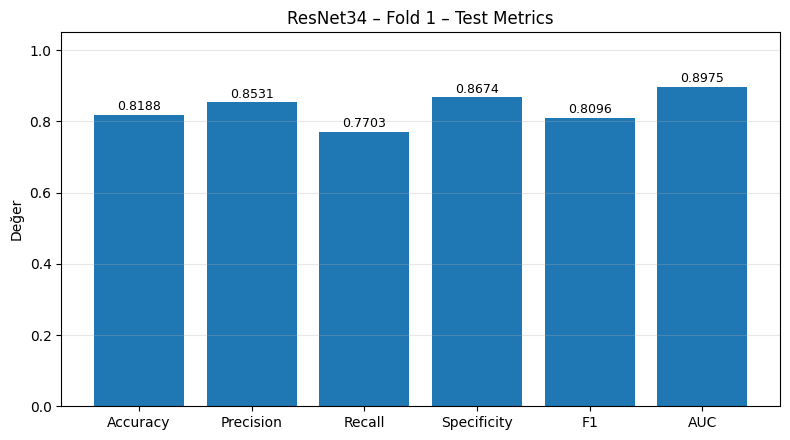

ResNet34 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7302.0,1111.0,1787.0,6626.0,0.827767,0.856404,0.787591,0.867942,0.820557,0.910320,0.387254
Validation,3594.0,1532.0,265.0,417.0,1380.0,0.810239,0.838906,0.767947,0.852532,0.801859,0.896133,0.408864
Test,3604.0,1563.0,239.0,414.0,1388.0,0.818812,0.853104,0.770255,0.867370,0.809565,0.897510,0.409503


✓ ResNet34 Fold 1: best epoch 10 | Test acc 0.8188
ResNet34 | Fold 2 | Epoch 01/10 | Train loss 0.5656 acc 0.6970 | Val loss 0.5070 acc 0.7507
ResNet34 | Fold 2 | Epoch 02/10 | Train loss 0.4958 acc 0.7591 | Val loss 0.4681 acc 0.7813
ResNet34 | Fold 2 | Epoch 03/10 | Train loss 0.4648 acc 0.7840 | Val loss 0.4824 acc 0.7654
ResNet34 | Fold 2 | Epoch 04/10 | Train loss 0.4483 acc 0.7906 | Val loss 0.4378 acc 0.7963
ResNet34 | Fold 2 | Epoch 05/10 | Train loss 0.4368 acc 0.7973 | Val loss 0.4302 acc 0.7977
ResNet34 | Fold 2 | Epoch 06/10 | Train loss 0.4234 acc 0.8080 | Val loss 0.4211 acc 0.8055
ResNet34 | Fold 2 | Epoch 07/10 | Train loss 0.4170 acc 0.8087 | Val loss 0.4205 acc 0.7999
ResNet34 | Fold 2 | Epoch 08/10 | Train loss 0.4098 acc 0.8154 | Val loss 0.4055 acc 0.8133
ResNet34 | Fold 2 | Epoch 09/10 | Train loss 0.4061 acc 0.8164 | Val loss 0.4017 acc 0.8150
ResNet34 | Fold 2 | Epoch 10/10 | Train loss 0.4031 acc 0.8169 | Val loss 0.3989 acc 0.8169


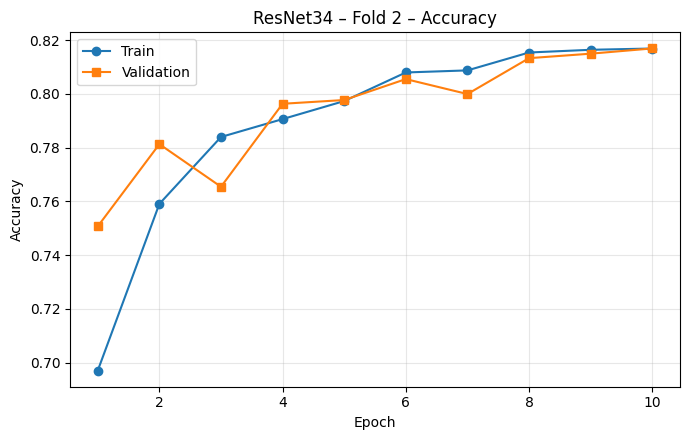

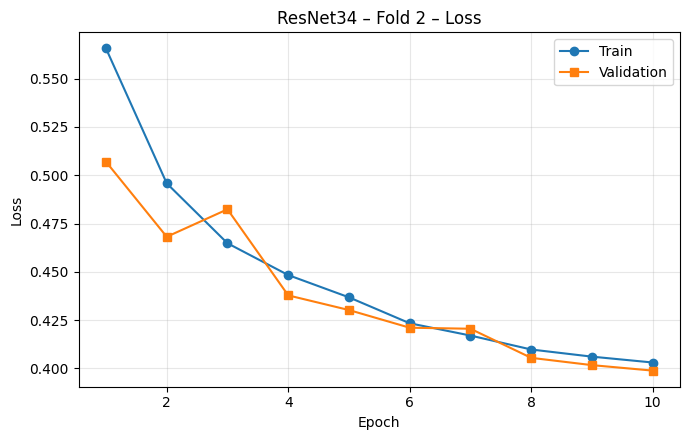

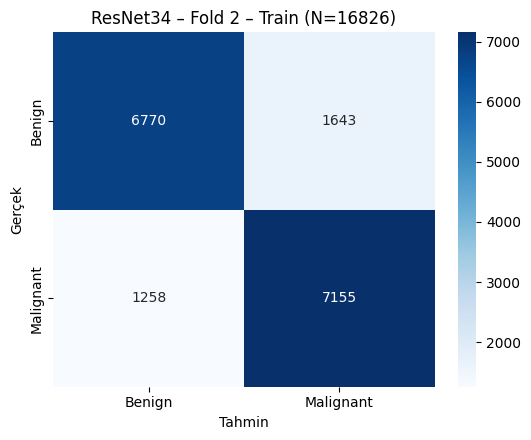

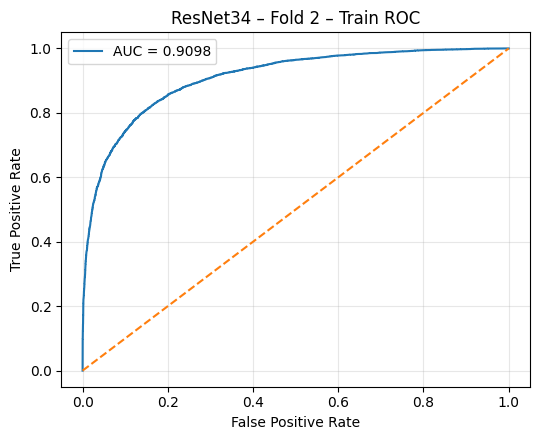

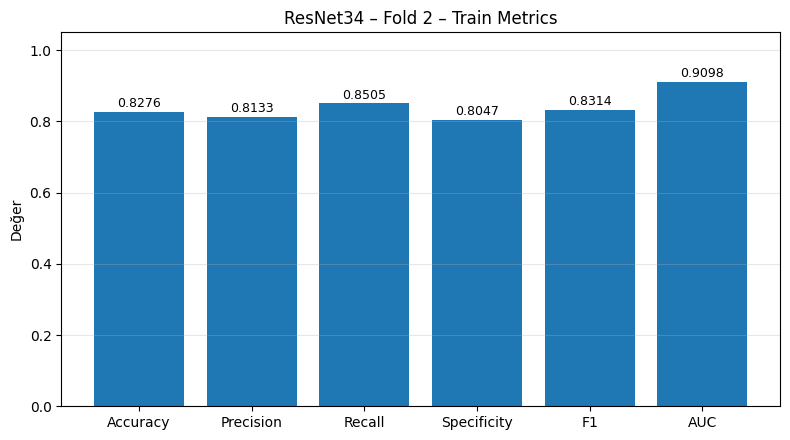

...

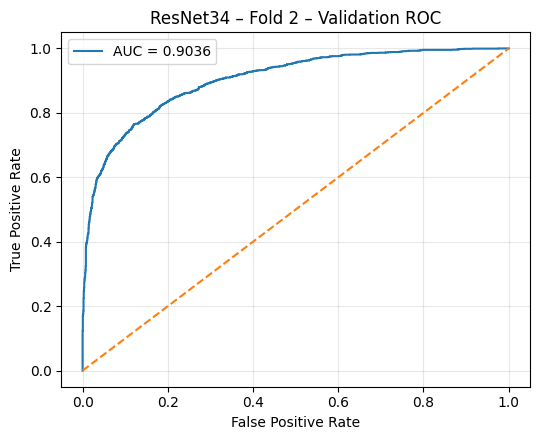

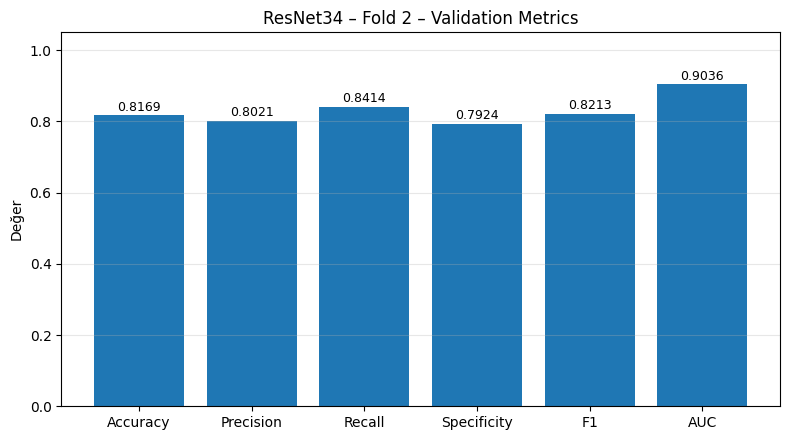

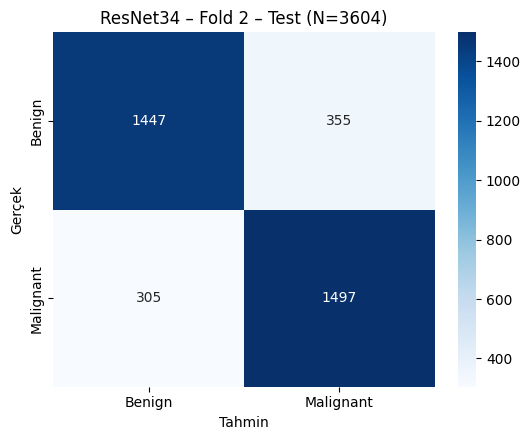

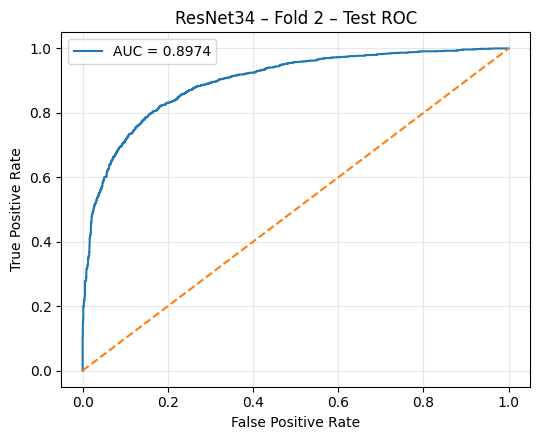

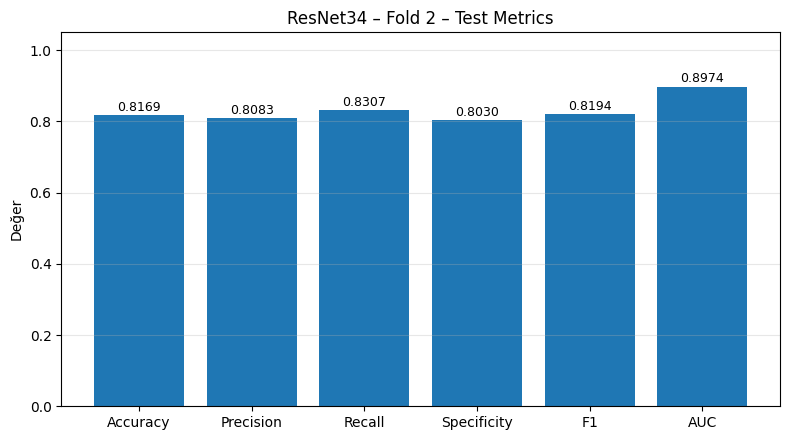

ResNet34 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6770.0,1643.0,1258.0,7155.0,0.827588,0.813253,0.850470,0.804707,0.831445,0.909832,0.391702
Validation,3594.0,1424.0,373.0,285.0,1512.0,0.816917,0.802122,0.841402,0.792432,0.821293,0.903613,0.398868
Test,3604.0,1447.0,355.0,305.0,1497.0,0.816870,0.808315,0.830744,0.802997,0.819376,0.897443,0.409225


✓ ResNet34 Fold 2: best epoch 10 | Test acc 0.8169
ResNet34 | Fold 3 | Epoch 01/10 | Train loss 0.5647 acc 0.7023 | Val loss 0.5185 acc 0.7465
ResNet34 | Fold 3 | Epoch 02/10 | Train loss 0.4907 acc 0.7646 | Val loss 0.4780 acc 0.7724
ResNet34 | Fold 3 | Epoch 03/10 | Train loss 0.4623 acc 0.7864 | Val loss 0.4601 acc 0.7858
ResNet34 | Fold 3 | Epoch 04/10 | Train loss 0.4466 acc 0.7935 | Val loss 0.4482 acc 0.7877
ResNet34 | Fold 3 | Epoch 05/10 | Train loss 0.4324 acc 0.8013 | Val loss 0.4364 acc 0.8030
ResNet34 | Fold 3 | Epoch 06/10 | Train loss 0.4223 acc 0.8046 | Val loss 0.4419 acc 0.7952
ResNet34 | Fold 3 | Epoch 07/10 | Train loss 0.4156 acc 0.8104 | Val loss 0.4259 acc 0.8133
ResNet34 | Fold 3 | Epoch 08/10 | Train loss 0.4060 acc 0.8192 | Val loss 0.4132 acc 0.8141
ResNet34 | Fold 3 | Epoch 09/10 | Train loss 0.4014 acc 0.8194 | Val loss 0.4117 acc 0.8152
ResNet34 | Fold 3 | Epoch 10/10 | Train loss 0.3996 acc 0.8212 | Val loss 0.4113 acc 0.8172


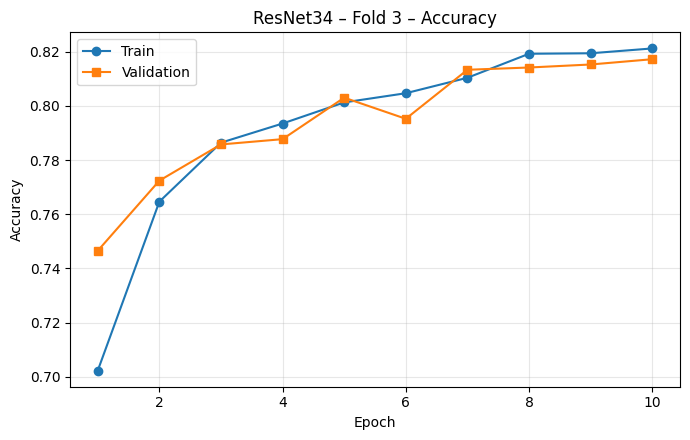

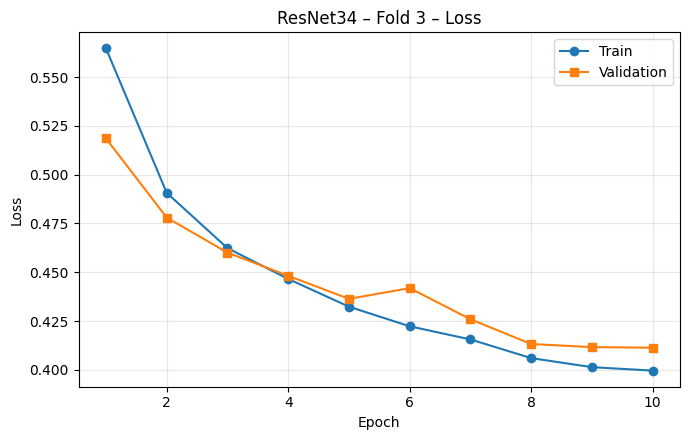

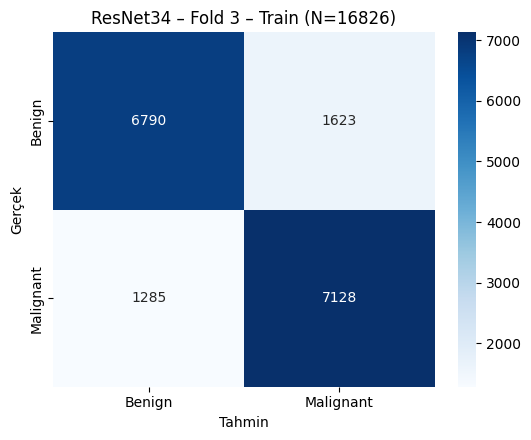

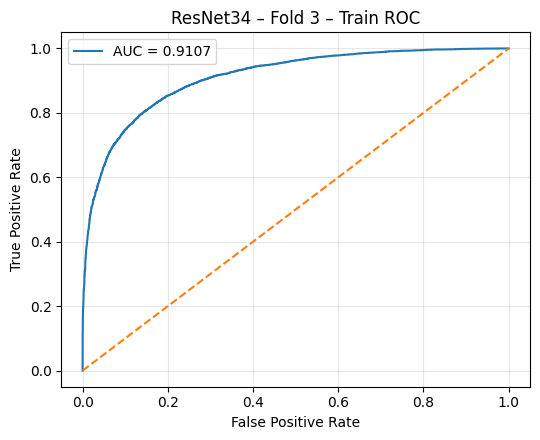

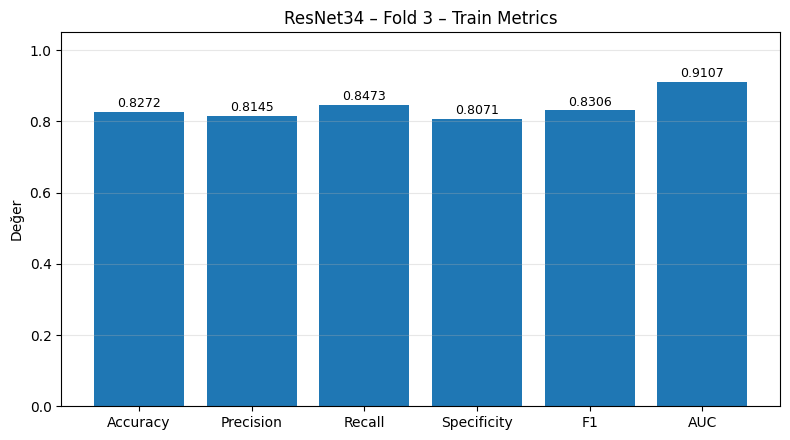

...

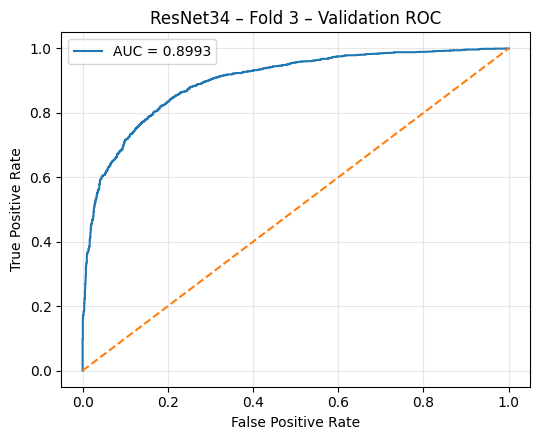

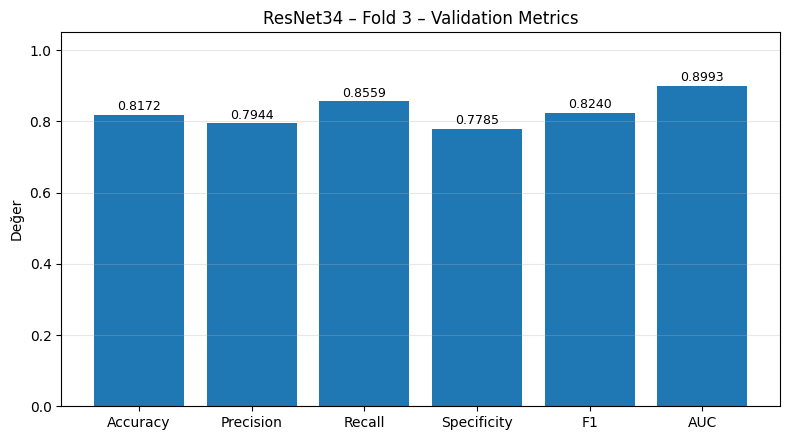

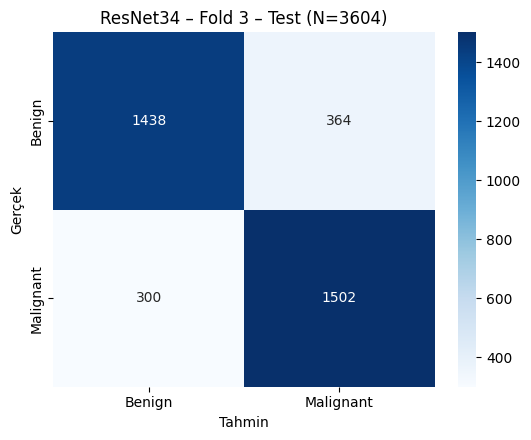

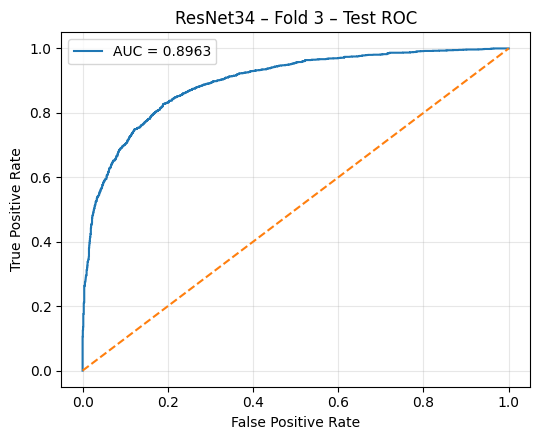

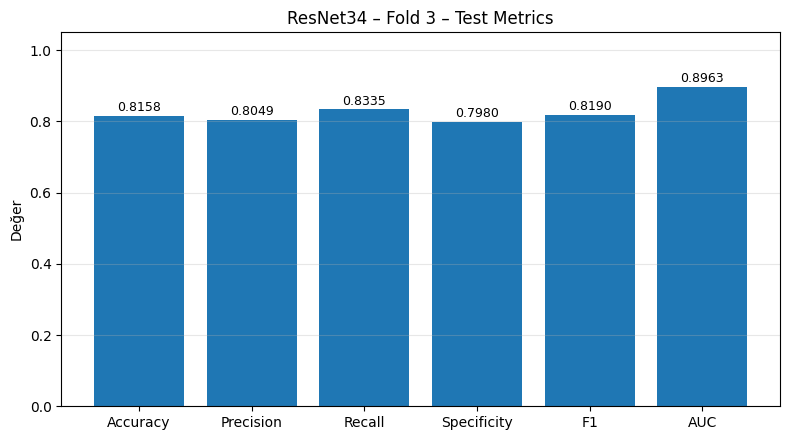

ResNet34 – Fold 3 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6790.0,1623.0,1285.0,7128.0,0.827172,0.814535,0.847260,0.807084,0.830576,0.910715,0.389006
Validation,3594.0,1399.0,398.0,259.0,1538.0,0.817195,0.794421,0.855871,0.778520,0.824002,0.899341,0.411317
Test,3604.0,1438.0,364.0,300.0,1502.0,0.815760,0.804930,0.833518,0.798002,0.818975,0.896346,0.411159


✓ ResNet34 Fold 3: best epoch 10 | Test acc 0.8158
ResNet34 | Fold 4 | Epoch 01/10 | Train loss 0.5622 acc 0.7018 | Val loss 0.5204 acc 0.7415
ResNet34 | Fold 4 | Epoch 02/10 | Train loss 0.4895 acc 0.7644 | Val loss 0.4977 acc 0.7568
ResNet34 | Fold 4 | Epoch 03/10 | Train loss 0.4613 acc 0.7841 | Val loss 0.4682 acc 0.7760
ResNet34 | Fold 4 | Epoch 04/10 | Train loss 0.4434 acc 0.7960 | Val loss 0.4511 acc 0.7913
ResNet34 | Fold 4 | Epoch 05/10 | Train loss 0.4297 acc 0.8046 | Val loss 0.4395 acc 0.7966
ResNet34 | Fold 4 | Epoch 06/10 | Train loss 0.4191 acc 0.8117 | Val loss 0.4334 acc 0.7988
ResNet34 | Fold 4 | Epoch 07/10 | Train loss 0.4123 acc 0.8124 | Val loss 0.4489 acc 0.7805
ResNet34 | Fold 4 | Epoch 08/10 | Train loss 0.4062 acc 0.8159 | Val loss 0.4283 acc 0.8038
ResNet34 | Fold 4 | Epoch 09/10 | Train loss 0.3988 acc 0.8208 | Val loss 0.4167 acc 0.8088
ResNet34 | Fold 4 | Epoch 10/10 | Train loss 0.3966 acc 0.8205 | Val loss 0.4157 acc 0.8136


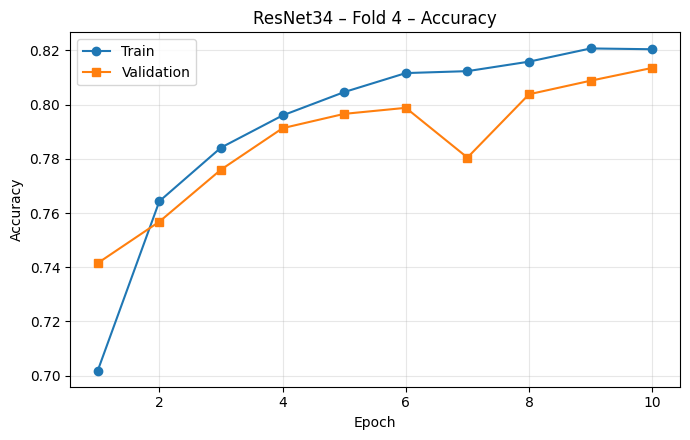

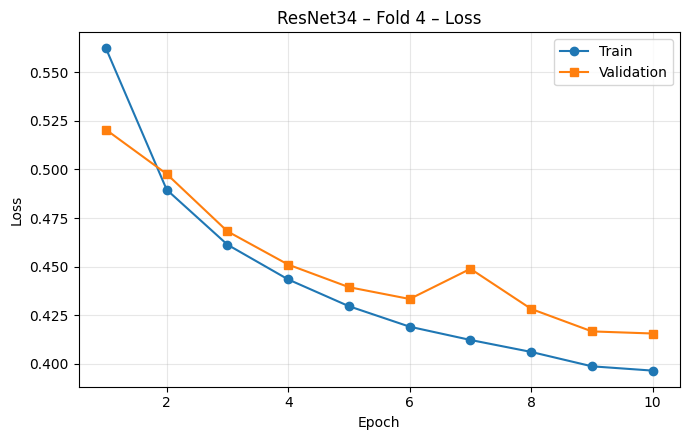

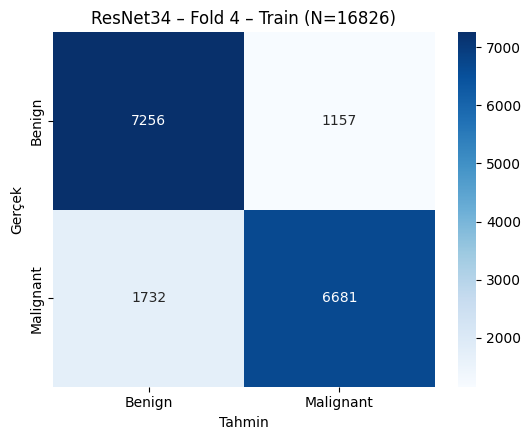

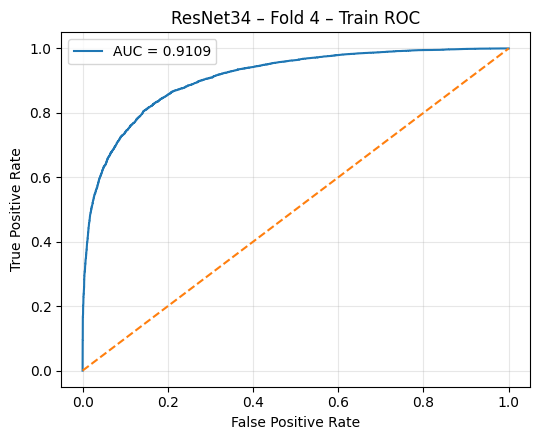

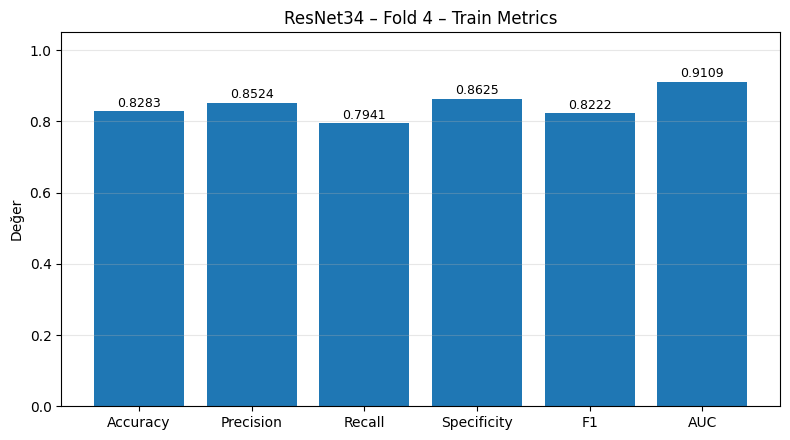

...

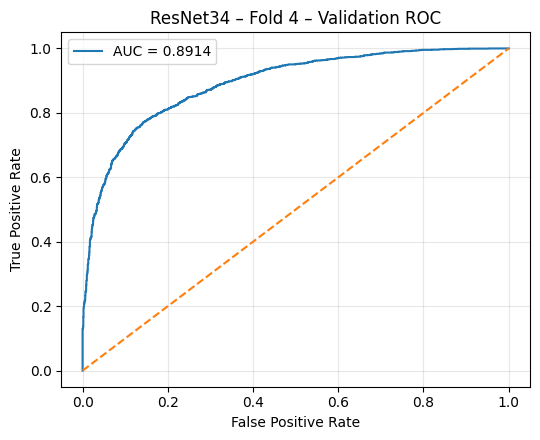

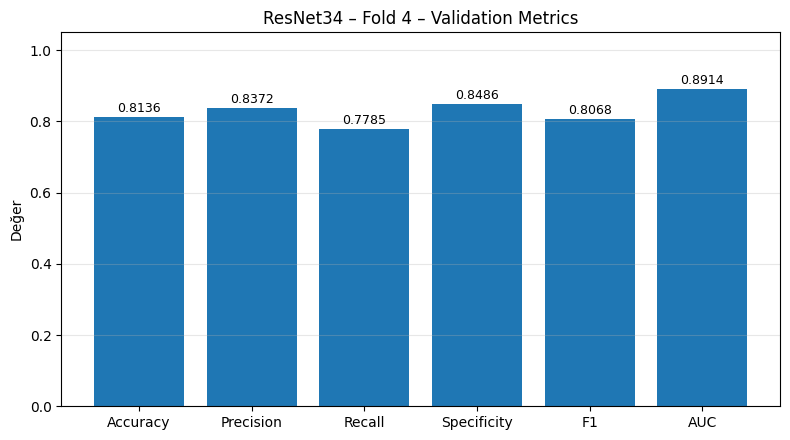

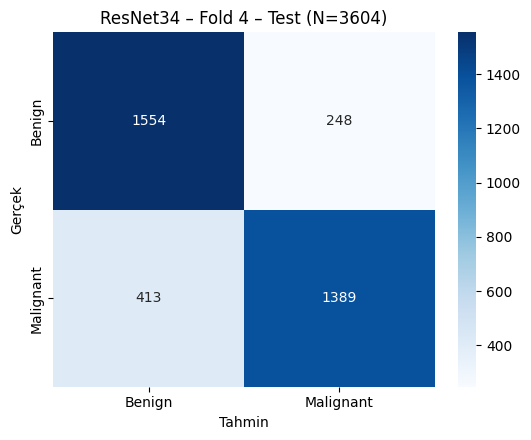

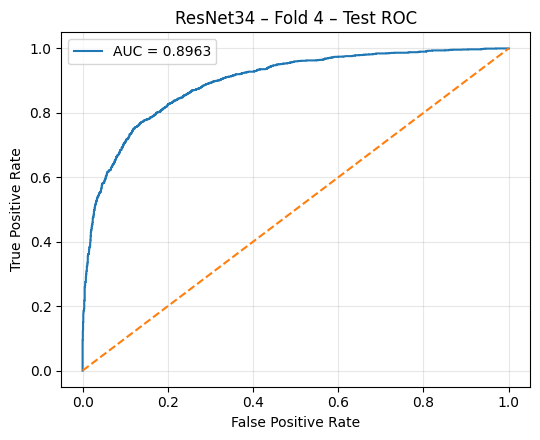

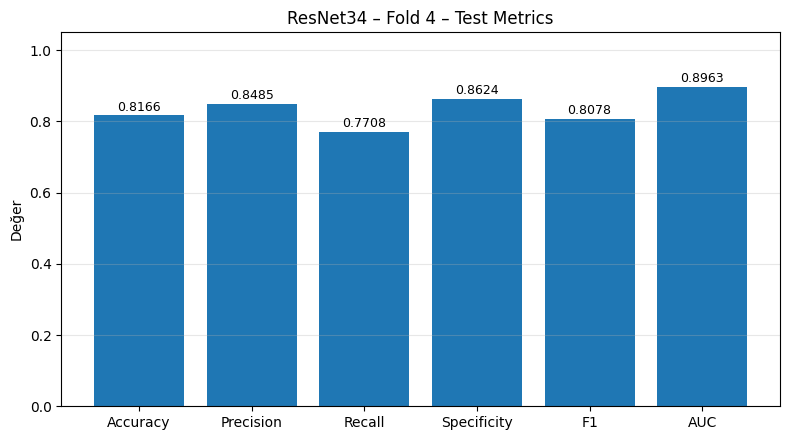

ResNet34 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7256.0,1157.0,1732.0,6681.0,0.828301,0.852386,0.794128,0.862475,0.822226,0.910924,0.384185
Validation,3594.0,1525.0,272.0,398.0,1399.0,0.813578,0.837223,0.778520,0.848637,0.806805,0.891356,0.415653
Test,3604.0,1554.0,248.0,413.0,1389.0,0.816593,0.848503,0.770810,0.862375,0.807793,0.896274,0.409934


✓ ResNet34 Fold 4: best epoch 10 | Test acc 0.8166
ResNet34 | Fold 5 | Epoch 01/10 | Train loss 0.5667 acc 0.6958 | Val loss 0.4908 acc 0.7682
ResNet34 | Fold 5 | Epoch 02/10 | Train loss 0.4953 acc 0.7635 | Val loss 0.4520 acc 0.7894
ResNet34 | Fold 5 | Epoch 03/10 | Train loss 0.4674 acc 0.7814 | Val loss 0.4369 acc 0.8002
ResNet34 | Fold 5 | Epoch 04/10 | Train loss 0.4518 acc 0.7915 | Val loss 0.4226 acc 0.8069
ResNet34 | Fold 5 | Epoch 05/10 | Train loss 0.4357 acc 0.8032 | Val loss 0.4123 acc 0.8116
ResNet34 | Fold 5 | Epoch 06/10 | Train loss 0.4252 acc 0.8095 | Val loss 0.4086 acc 0.8136
ResNet34 | Fold 5 | Epoch 07/10 | Train loss 0.4227 acc 0.8063 | Val loss 0.4352 acc 0.7938
ResNet34 | Fold 5 | Epoch 08/10 | Train loss 0.4102 acc 0.8150 | Val loss 0.3943 acc 0.8183
ResNet34 | Fold 5 | Epoch 09/10 | Train loss 0.4079 acc 0.8156 | Val loss 0.3915 acc 0.8255
ResNet34 | Fold 5 | Epoch 10/10 | Train loss 0.4023 acc 0.8180 | Val loss 0.3893 acc 0.8205


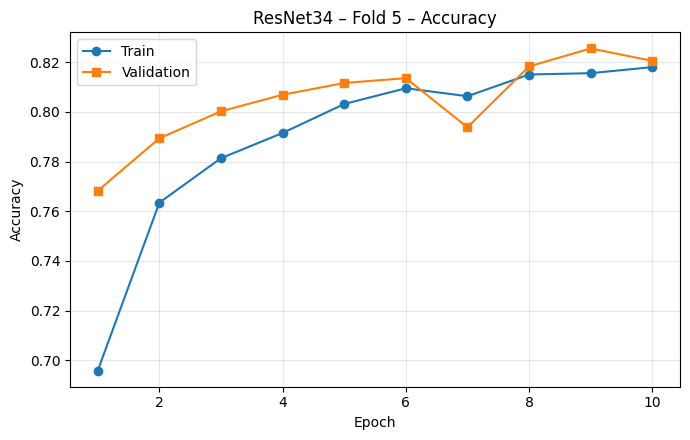

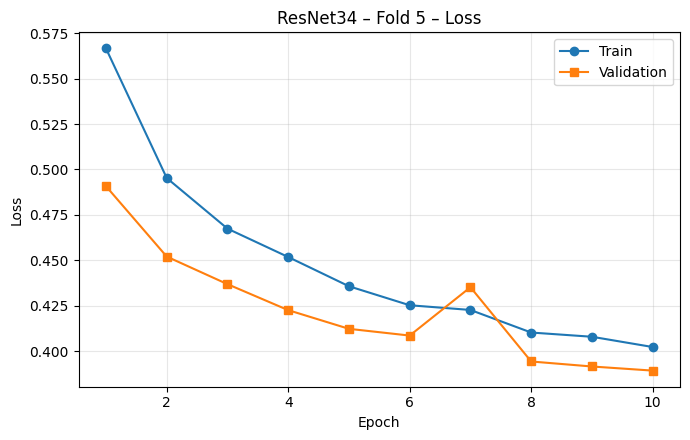

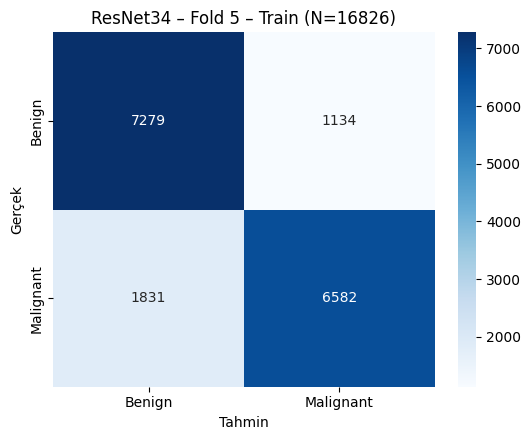

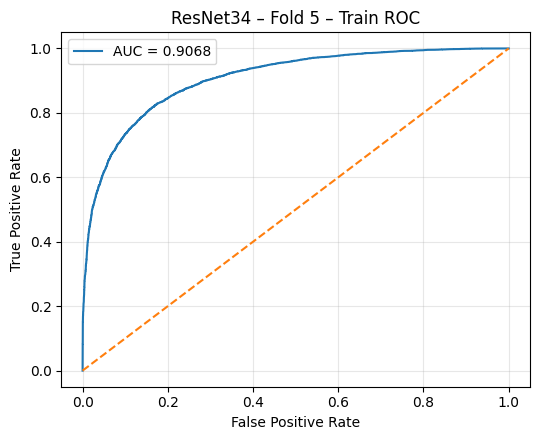

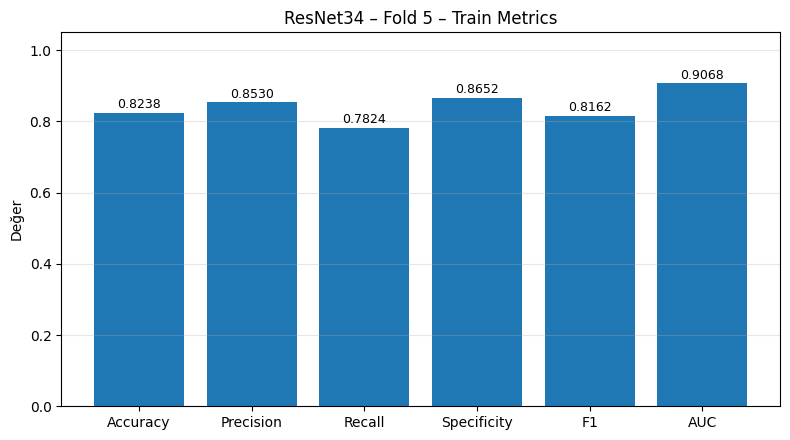

...

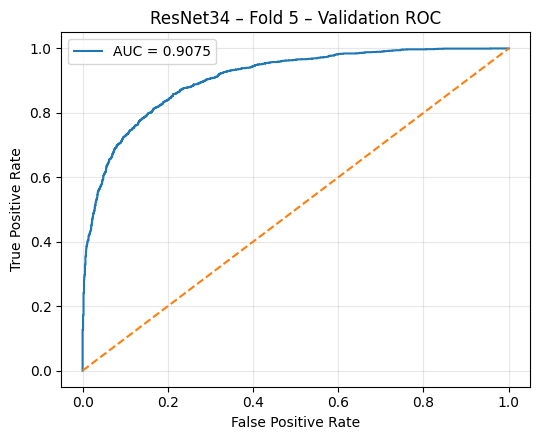

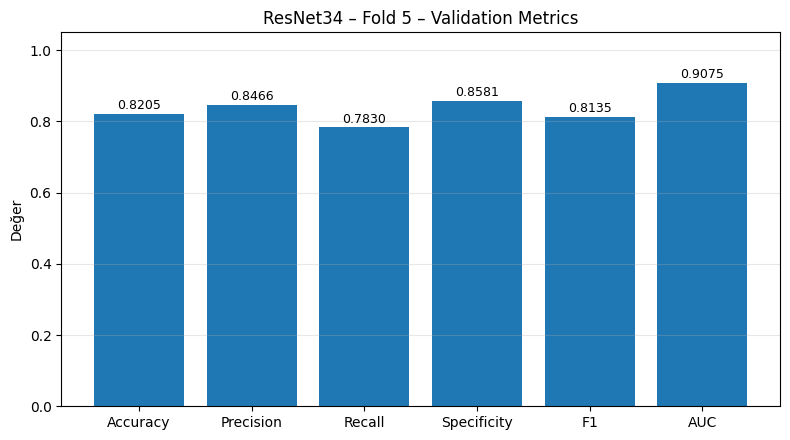

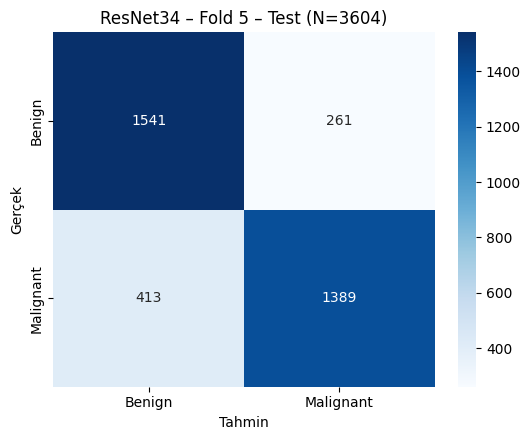

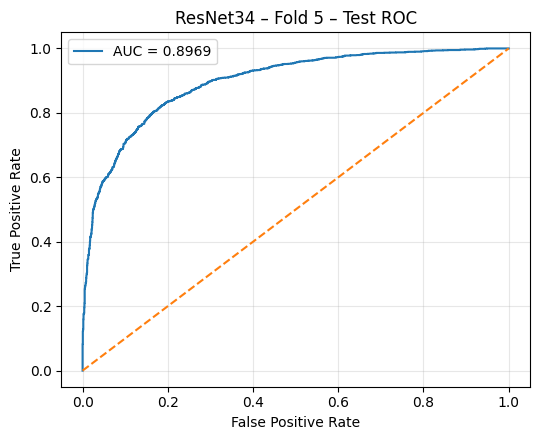

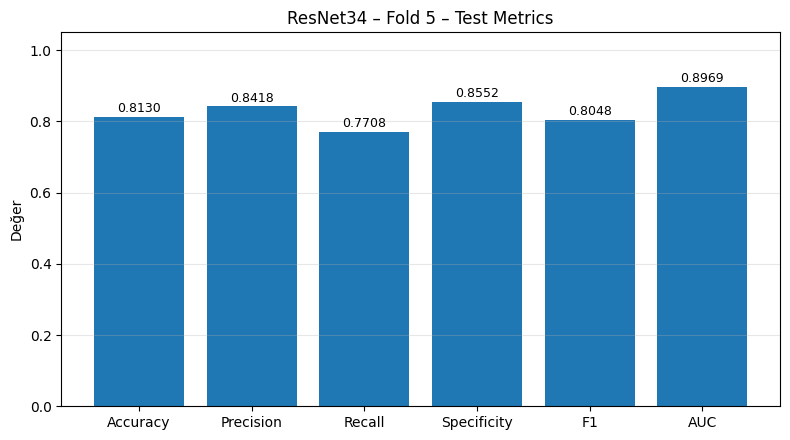

ResNet34 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7279.0,1134.0,1831.0,6582.0,0.823785,0.853033,0.782361,0.865209,0.816170,0.906834,0.392986
Validation,3594.0,1542.0,255.0,390.0,1407.0,0.820534,0.846570,0.782972,0.858097,0.813530,0.907536,0.389261
Test,3604.0,1541.0,261.0,413.0,1389.0,0.812986,0.841818,0.770810,0.855161,0.804751,0.896913,0.410458


✓ ResNet34 Fold 5: best epoch 10 | Test acc 0.8130
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 194MB/s]


DenseNet121 | Fold 1 | Epoch 01/10 | Train loss 0.5519 acc 0.7173 | Val loss 0.4799 acc 0.7727
DenseNet121 | Fold 1 | Epoch 02/10 | Train loss 0.4639 acc 0.7799 | Val loss 0.4441 acc 0.7949
DenseNet121 | Fold 1 | Epoch 03/10 | Train loss 0.4320 acc 0.8024 | Val loss 0.4173 acc 0.8136
DenseNet121 | Fold 1 | Epoch 04/10 | Train loss 0.4138 acc 0.8057 | Val loss 0.3987 acc 0.8267
DenseNet121 | Fold 1 | Epoch 05/10 | Train loss 0.3990 acc 0.8178 | Val loss 0.3913 acc 0.8264
DenseNet121 | Fold 1 | Epoch 06/10 | Train loss 0.3892 acc 0.8266 | Val loss 0.3772 acc 0.8350
DenseNet121 | Fold 1 | Epoch 07/10 | Train loss 0.3854 acc 0.8260 | Val loss 0.3711 acc 0.8386
DenseNet121 | Fold 1 | Epoch 08/10 | Train loss 0.3776 acc 0.8303 | Val loss 0.3724 acc 0.8378
DenseNet121 | Fold 1 | Epoch 09/10 | Train loss 0.3707 acc 0.8341 | Val loss 0.3650 acc 0.8425
DenseNet121 | Fold 1 | Epoch 10/10 | Train loss 0.3710 acc 0.8337 | Val loss 0.3685 acc 0.8372


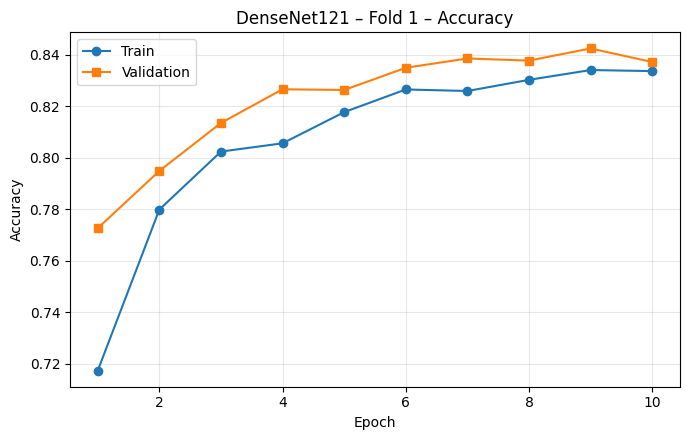

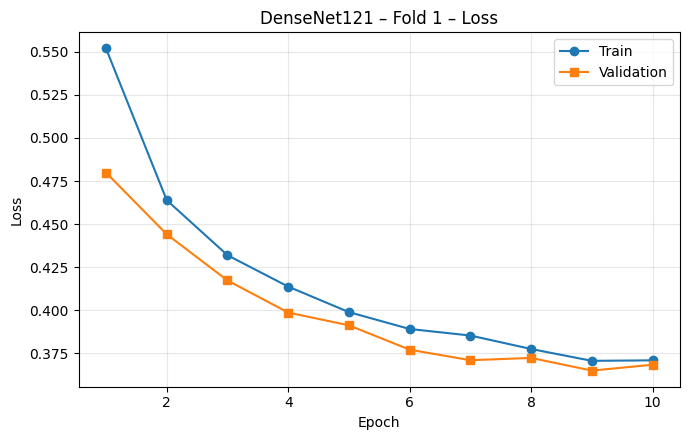

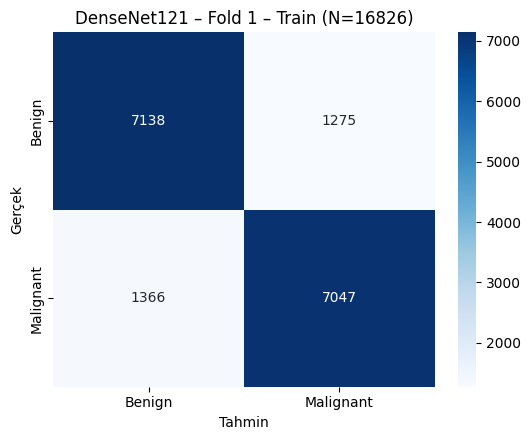

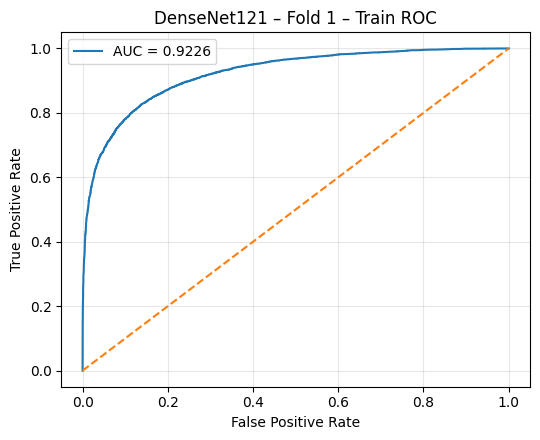

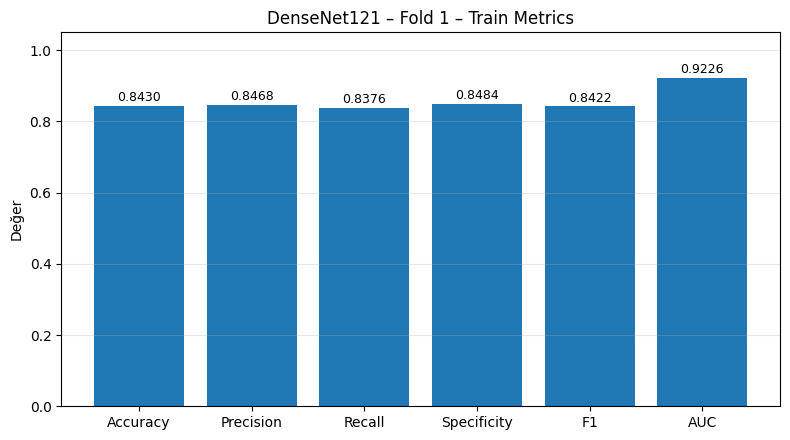

...

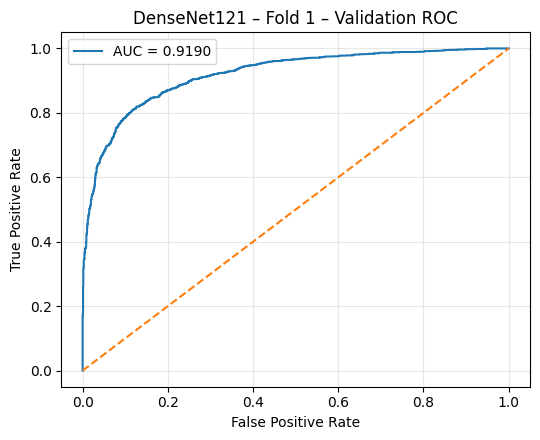

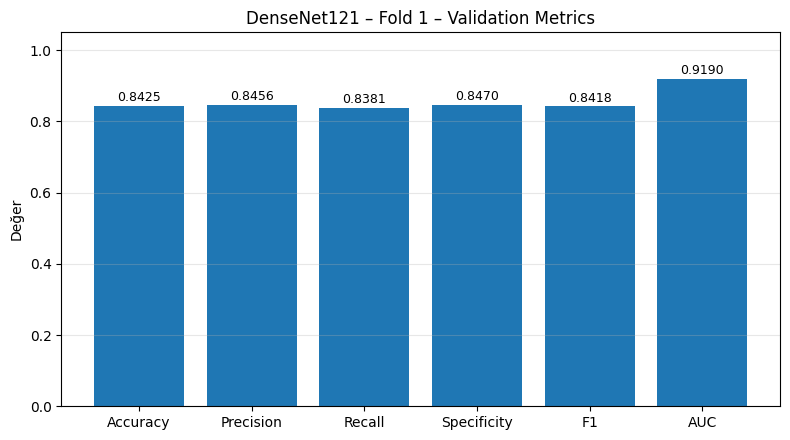

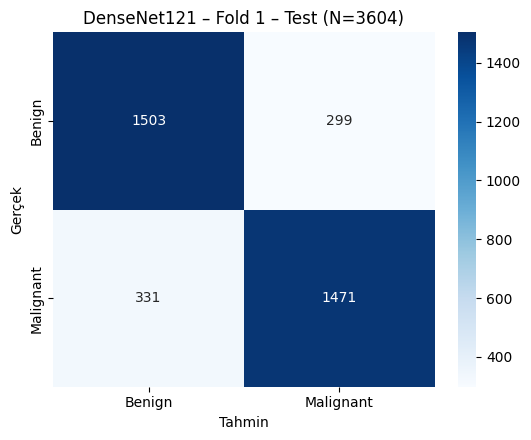

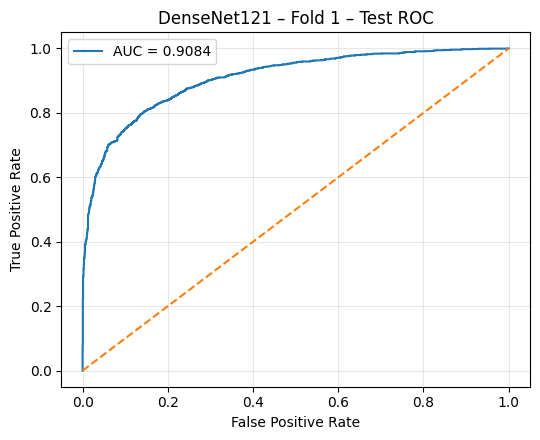

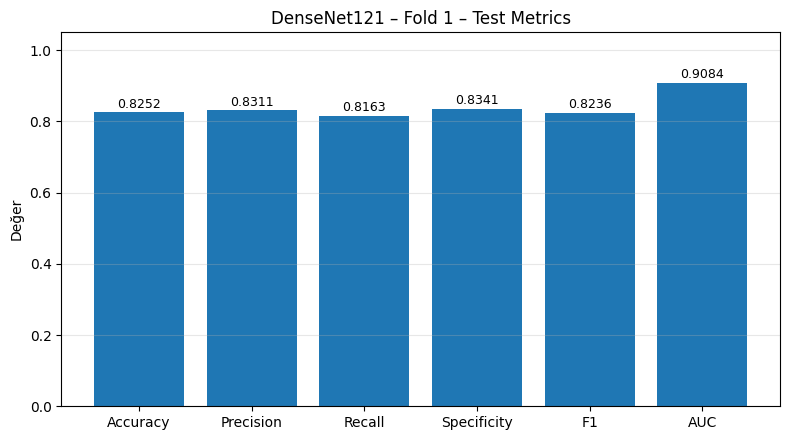

DenseNet121 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7138.0,1275.0,1366.0,7047.0,0.843041,0.846792,0.837632,0.848449,0.842187,0.922603,0.358373
Validation,3594.0,1522.0,275.0,291.0,1506.0,0.842515,0.845592,0.838063,0.846967,0.841811,0.918954,0.365030
Test,3604.0,1503.0,299.0,331.0,1471.0,0.825194,0.831073,0.816315,0.834073,0.823628,0.908389,0.382995


✓ DenseNet121 Fold 1: best epoch 9 | Test acc 0.8252
DenseNet121 | Fold 2 | Epoch 01/10 | Train loss 0.5529 acc 0.7115 | Val loss 0.4778 acc 0.7796
DenseNet121 | Fold 2 | Epoch 02/10 | Train loss 0.4638 acc 0.7833 | Val loss 0.4425 acc 0.7974
DenseNet121 | Fold 2 | Epoch 03/10 | Train loss 0.4325 acc 0.7998 | Val loss 0.4176 acc 0.8133
DenseNet121 | Fold 2 | Epoch 04/10 | Train loss 0.4140 acc 0.8116 | Val loss 0.4084 acc 0.8216
DenseNet121 | Fold 2 | Epoch 05/10 | Train loss 0.3986 acc 0.8187 | Val loss 0.4001 acc 0.8216
DenseNet121 | Fold 2 | Epoch 06/10 | Train loss 0.3879 acc 0.8244 | Val loss 0.3993 acc 0.8127
DenseNet121 | Fold 2 | Epoch 07/10 | Train loss 0.3832 acc 0.8251 | Val loss 0.3833 acc 0.8253
DenseNet121 | Fold 2 | Epoch 08/10 | Train loss 0.3749 acc 0.8326 | Val loss 0.3737 acc 0.8358
DenseNet121 | Fold 2 | Epoch 09/10 | Train loss 0.3712 acc 0.8341 | Val loss 0.3736 acc 0.8311
DenseNet121 | Fold 2 | Epoch 10/10 | Train loss 0.3654 acc 0.8389 | Val loss 0.3805 acc 0.83

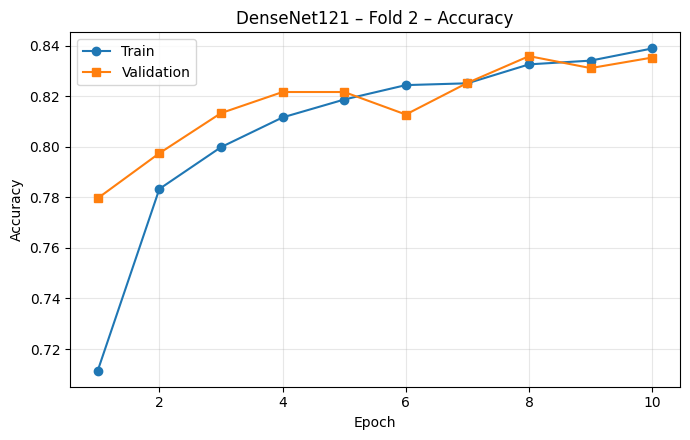

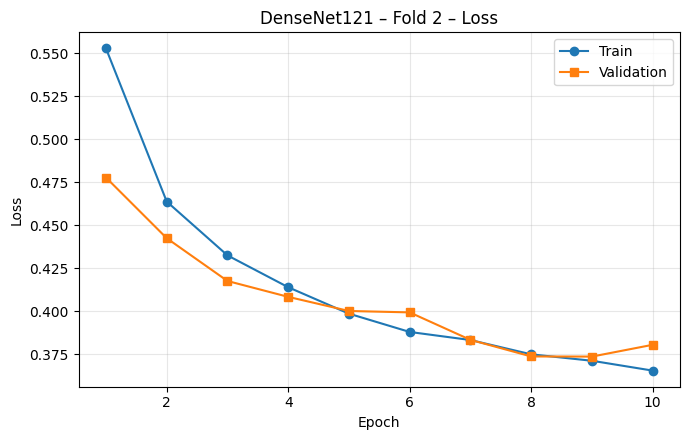

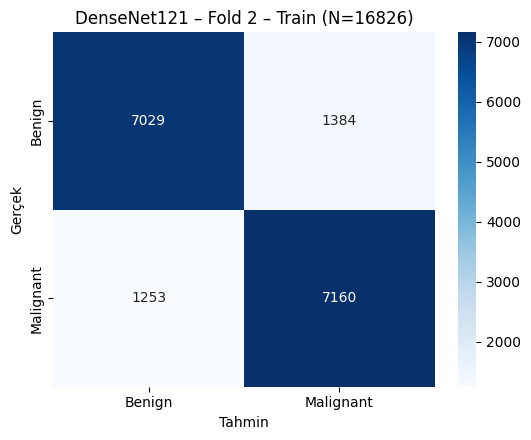

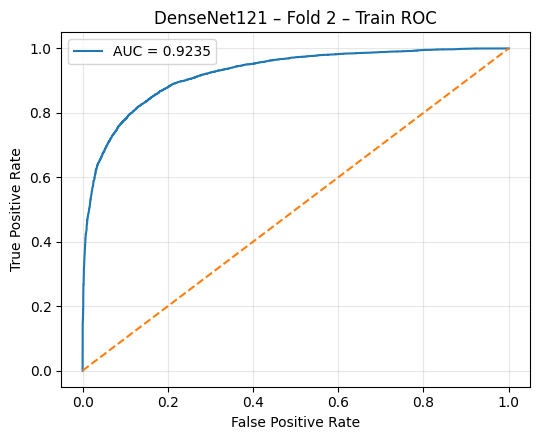

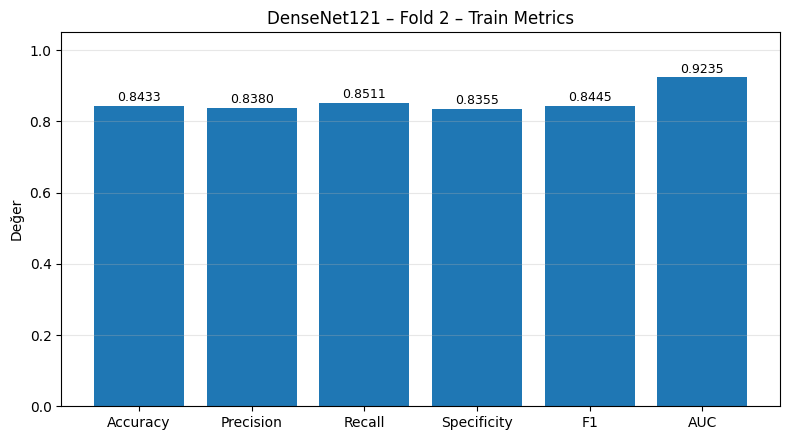

...

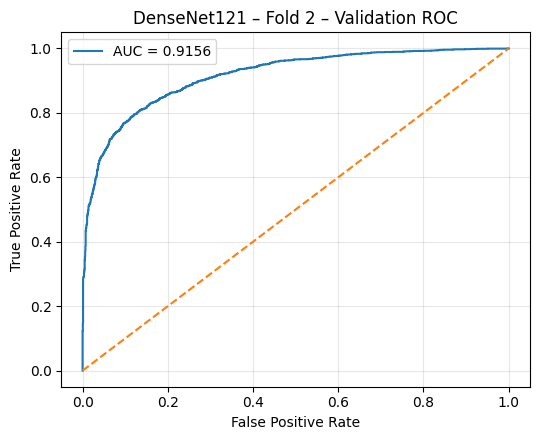

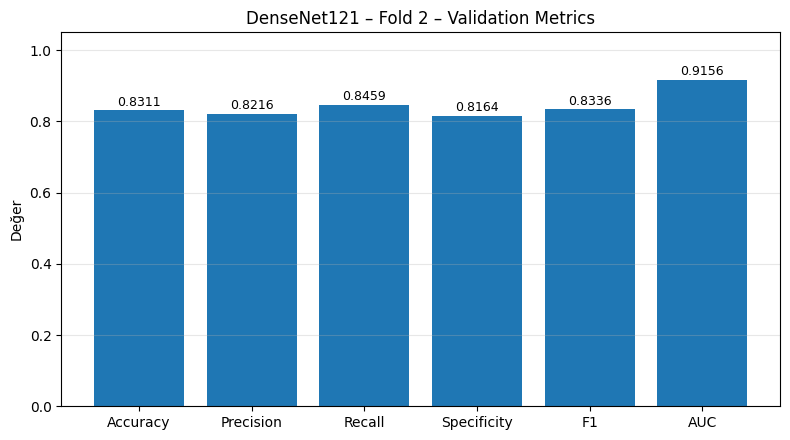

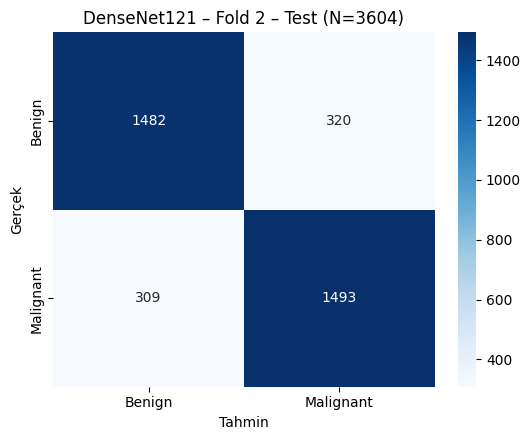

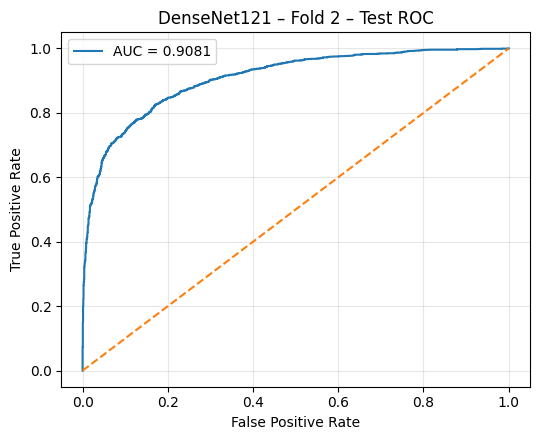

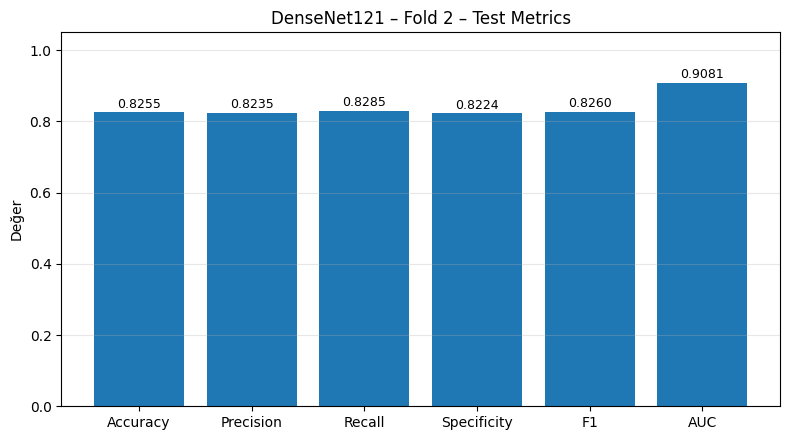

DenseNet121 – Fold 2 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7029.0,1384.0,1253.0,7160.0,0.843278,0.838015,0.851064,0.835493,0.844489,0.923532,0.358132
Validation,3594.0,1467.0,330.0,277.0,1520.0,0.831107,0.821622,0.845854,0.816361,0.833562,0.915564,0.373604
Test,3604.0,1482.0,320.0,309.0,1493.0,0.825472,0.823497,0.828524,0.822420,0.826003,0.908091,0.384374


✓ DenseNet121 Fold 2: best epoch 9 | Test acc 0.8255
DenseNet121 | Fold 3 | Epoch 01/10 | Train loss 0.5487 acc 0.7160 | Val loss 0.4844 acc 0.7652
DenseNet121 | Fold 3 | Epoch 02/10 | Train loss 0.4596 acc 0.7847 | Val loss 0.4431 acc 0.7910
DenseNet121 | Fold 3 | Epoch 03/10 | Train loss 0.4279 acc 0.8035 | Val loss 0.4300 acc 0.7997
DenseNet121 | Fold 3 | Epoch 04/10 | Train loss 0.4115 acc 0.8133 | Val loss 0.4068 acc 0.8130
DenseNet121 | Fold 3 | Epoch 05/10 | Train loss 0.3968 acc 0.8202 | Val loss 0.4089 acc 0.8033
DenseNet121 | Fold 3 | Epoch 06/10 | Train loss 0.3894 acc 0.8234 | Val loss 0.3919 acc 0.8211
DenseNet121 | Fold 3 | Epoch 07/10 | Train loss 0.3808 acc 0.8276 | Val loss 0.3882 acc 0.8155
DenseNet121 | Fold 3 | Epoch 08/10 | Train loss 0.3755 acc 0.8304 | Val loss 0.3794 acc 0.8278
DenseNet121 | Fold 3 | Epoch 09/10 | Train loss 0.3713 acc 0.8327 | Val loss 0.3779 acc 0.8244
DenseNet121 | Fold 3 | Epoch 10/10 | Train loss 0.3665 acc 0.8363 | Val loss 0.3761 acc 0.82

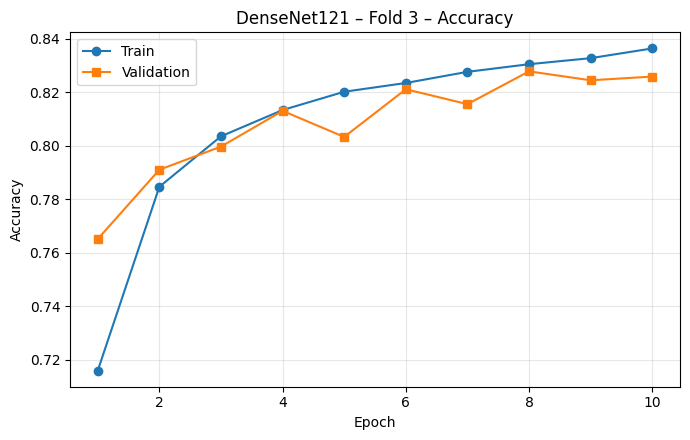

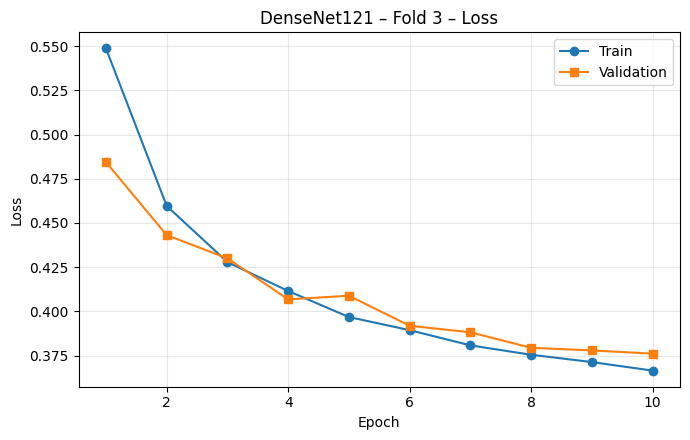

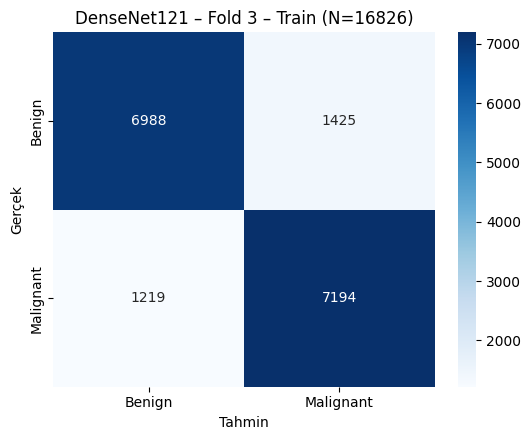

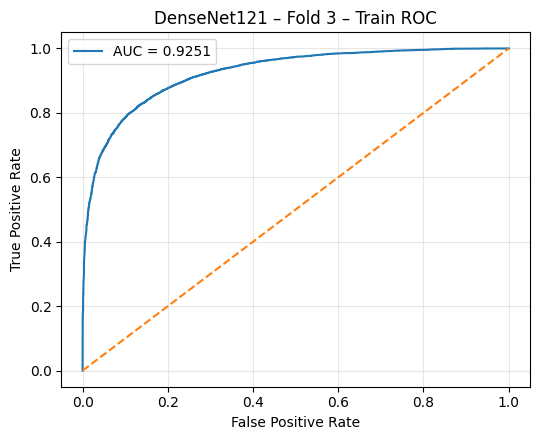

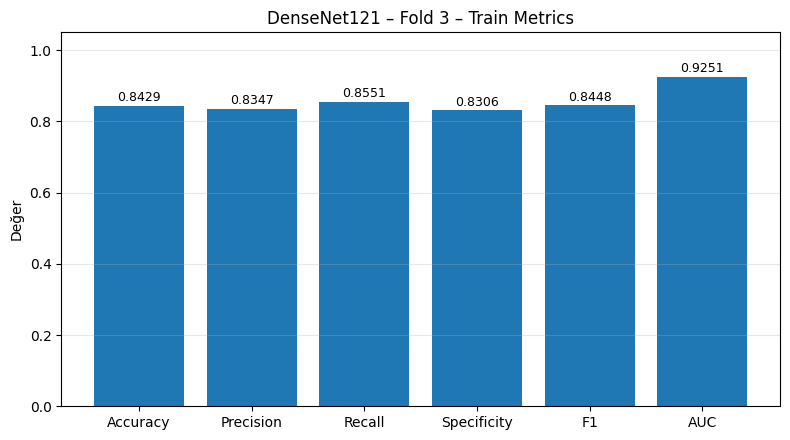

...

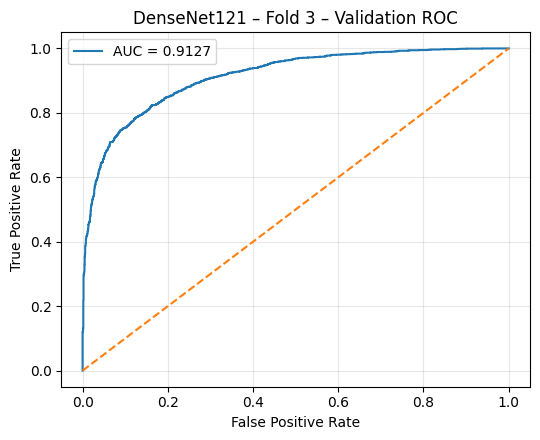

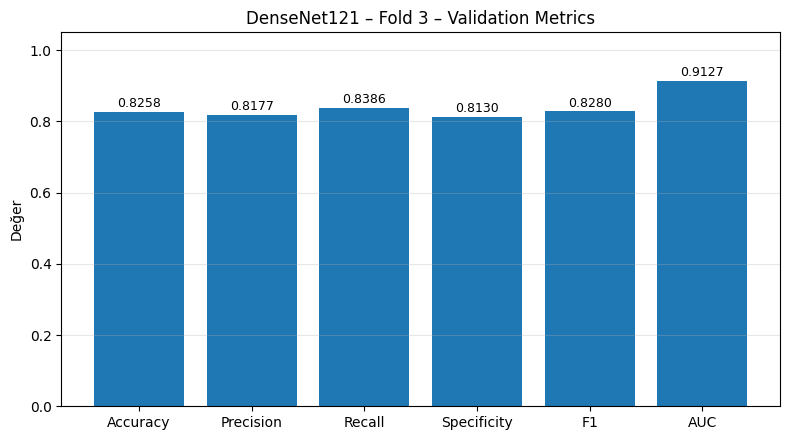

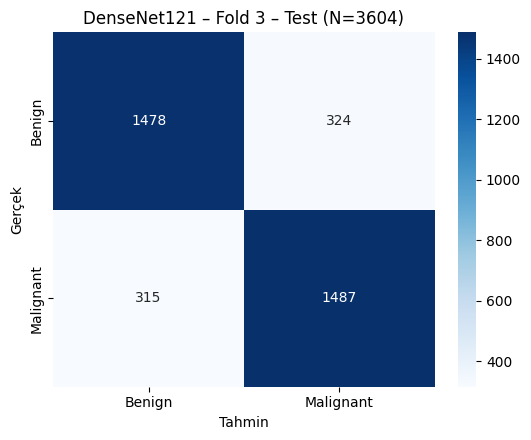

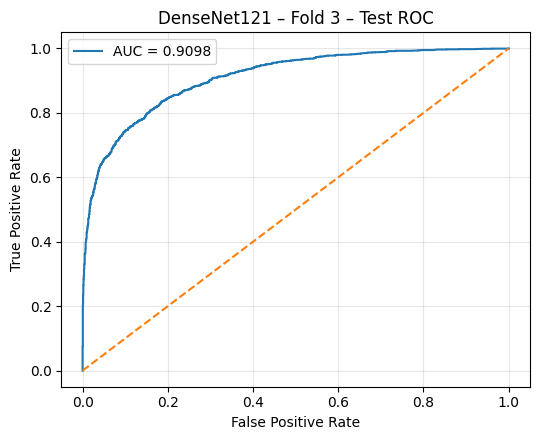

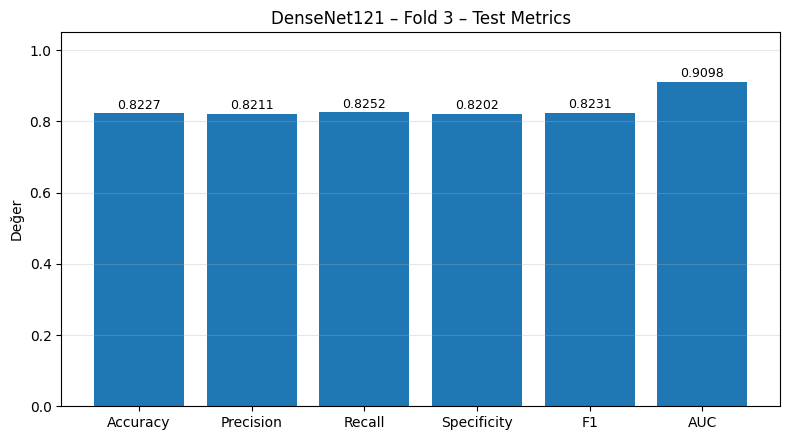

DenseNet121 – Fold 3 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6988.0,1425.0,1219.0,7194.0,0.842862,0.834668,0.855105,0.830619,0.844763,0.925082,0.353920
Validation,3594.0,1461.0,336.0,290.0,1507.0,0.825821,0.817689,0.838620,0.813022,0.828022,0.912652,0.376099
Test,3604.0,1478.0,324.0,315.0,1487.0,0.822697,0.821093,0.825194,0.820200,0.823139,0.909779,0.380384


✓ DenseNet121 Fold 3: best epoch 10 | Test acc 0.8227
DenseNet121 | Fold 4 | Epoch 01/10 | Train loss 0.5470 acc 0.7204 | Val loss 0.4894 acc 0.7710
DenseNet121 | Fold 4 | Epoch 02/10 | Train loss 0.4598 acc 0.7821 | Val loss 0.4539 acc 0.7969
DenseNet121 | Fold 4 | Epoch 03/10 | Train loss 0.4277 acc 0.8042 | Val loss 0.4323 acc 0.8075
DenseNet121 | Fold 4 | Epoch 04/10 | Train loss 0.4089 acc 0.8140 | Val loss 0.4160 acc 0.8158
DenseNet121 | Fold 4 | Epoch 05/10 | Train loss 0.3955 acc 0.8197 | Val loss 0.4139 acc 0.8141
DenseNet121 | Fold 4 | Epoch 06/10 | Train loss 0.3851 acc 0.8266 | Val loss 0.4017 acc 0.8166
DenseNet121 | Fold 4 | Epoch 07/10 | Train loss 0.3788 acc 0.8287 | Val loss 0.4016 acc 0.8166
DenseNet121 | Fold 4 | Epoch 08/10 | Train loss 0.3710 acc 0.8334 | Val loss 0.3902 acc 0.8216
DenseNet121 | Fold 4 | Epoch 09/10 | Train loss 0.3656 acc 0.8380 | Val loss 0.3937 acc 0.8236
DenseNet121 | Fold 4 | Epoch 10/10 | Train loss 0.3630 acc 0.8386 | Val loss 0.3870 acc 0.8

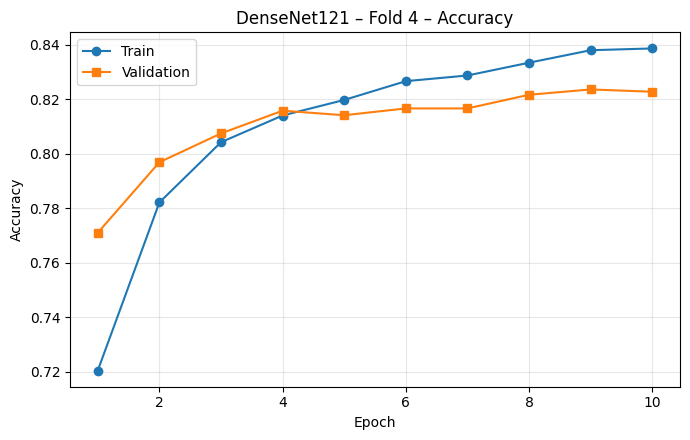

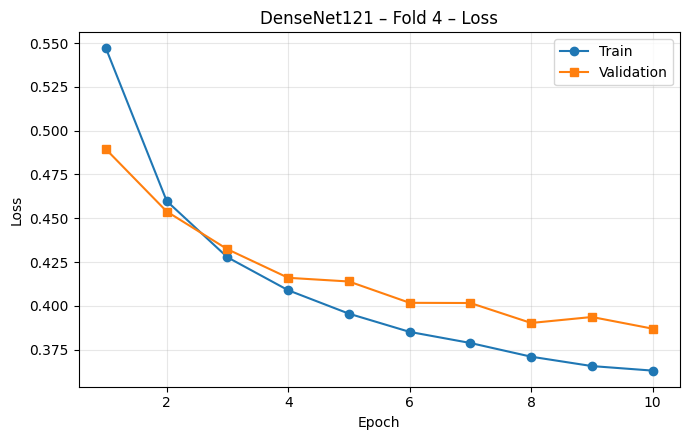

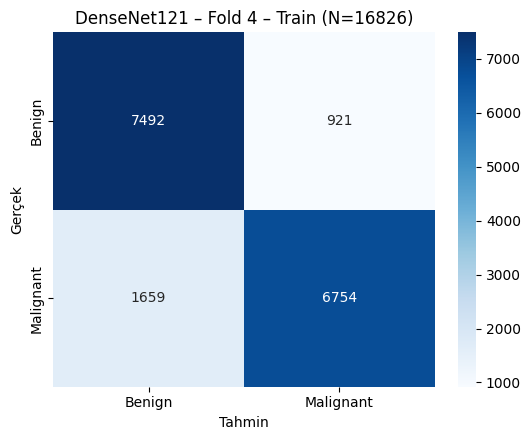

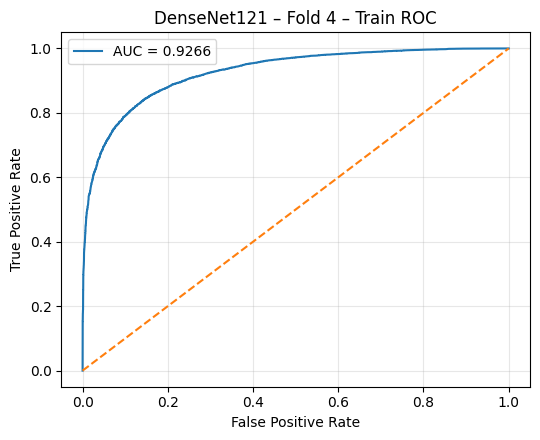

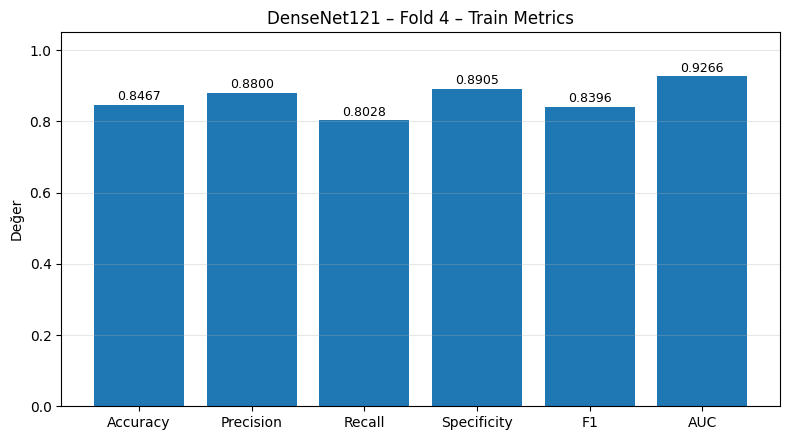

...

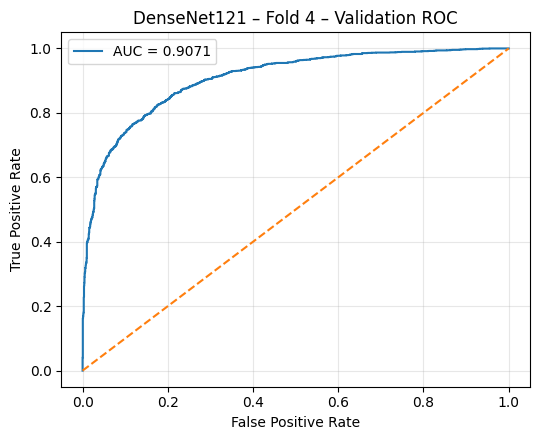

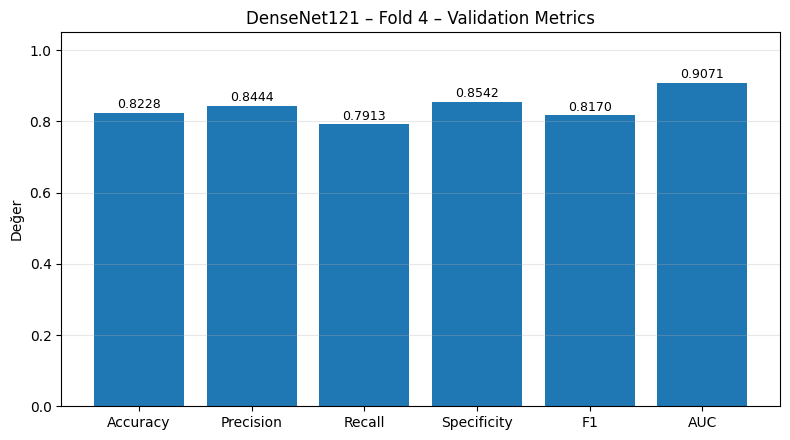

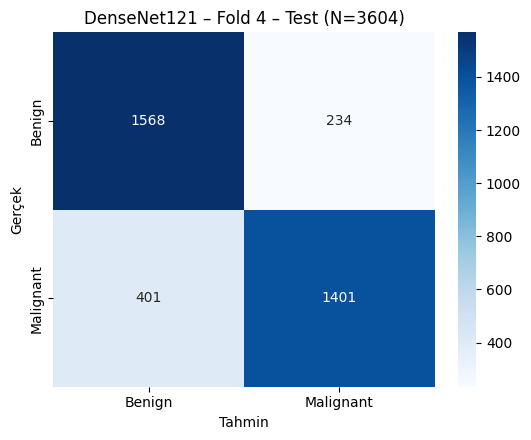

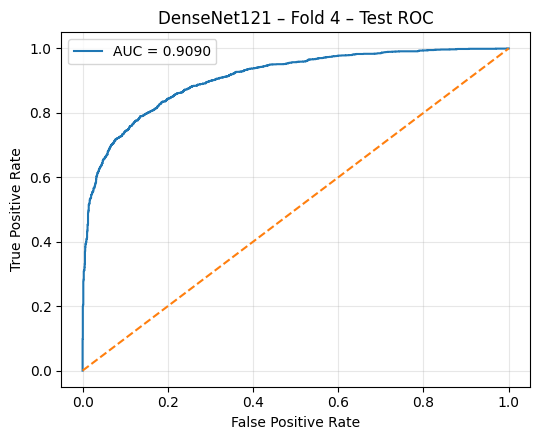

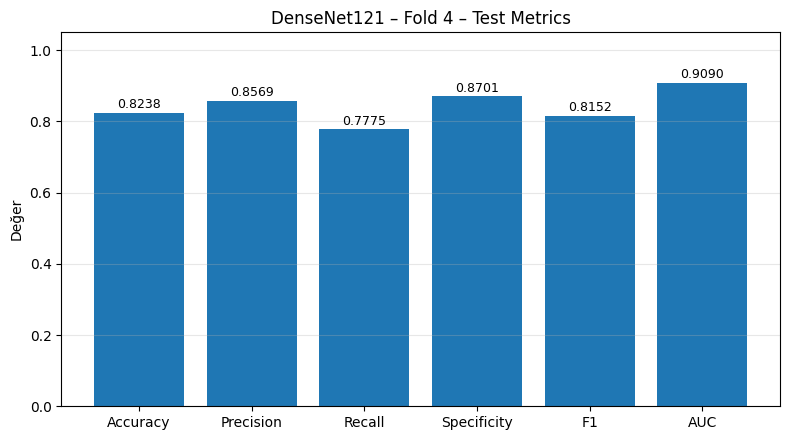

DenseNet121 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7492.0,921.0,1659.0,6754.0,0.846666,0.880000,0.802805,0.890527,0.839632,0.926576,0.349585
Validation,3594.0,1535.0,262.0,375.0,1422.0,0.822760,0.844418,0.791319,0.854201,0.817007,0.907143,0.386983
Test,3604.0,1568.0,234.0,401.0,1401.0,0.823807,0.856881,0.777469,0.870144,0.815246,0.909008,0.384159


✓ DenseNet121 Fold 4: best epoch 10 | Test acc 0.8238
DenseNet121 | Fold 5 | Epoch 01/10 | Train loss 0.5514 acc 0.7153 | Val loss 0.4632 acc 0.7938
DenseNet121 | Fold 5 | Epoch 02/10 | Train loss 0.4620 acc 0.7833 | Val loss 0.4306 acc 0.8108
DenseNet121 | Fold 5 | Epoch 03/10 | Train loss 0.4313 acc 0.8008 | Val loss 0.4108 acc 0.8180
DenseNet121 | Fold 5 | Epoch 04/10 | Train loss 0.4174 acc 0.8074 | Val loss 0.3882 acc 0.8311
DenseNet121 | Fold 5 | Epoch 05/10 | Train loss 0.4014 acc 0.8195 | Val loss 0.3781 acc 0.8406
DenseNet121 | Fold 5 | Epoch 06/10 | Train loss 0.3900 acc 0.8231 | Val loss 0.3721 acc 0.8325
DenseNet121 | Fold 5 | Epoch 07/10 | Train loss 0.3839 acc 0.8294 | Val loss 0.3864 acc 0.8236
DenseNet121 | Fold 5 | Epoch 08/10 | Train loss 0.3767 acc 0.8314 | Val loss 0.4080 acc 0.8200
DenseNet121 | Fold 5 | Epoch 09/10 | Train loss 0.3747 acc 0.8332 | Val loss 0.3643 acc 0.8478
DenseNet121 | Fold 5 | Epoch 10/10 | Train loss 0.3695 acc 0.8351 | Val loss 0.3662 acc 0.8

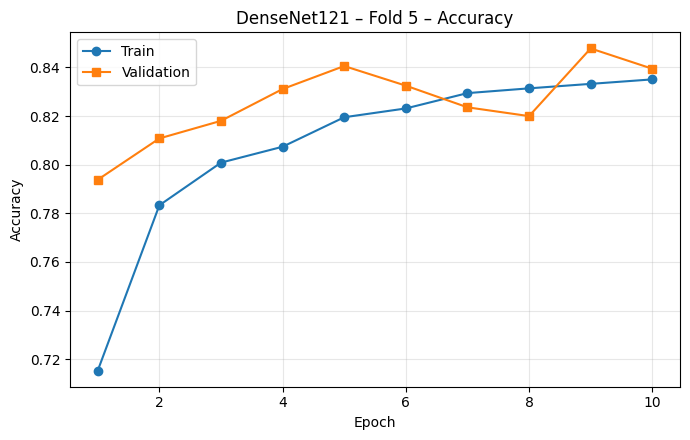

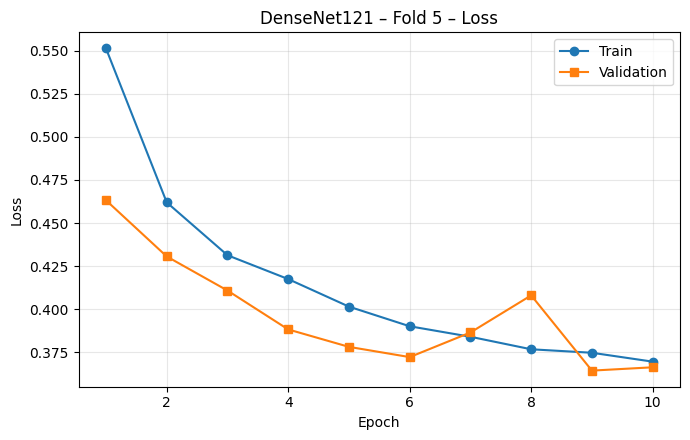

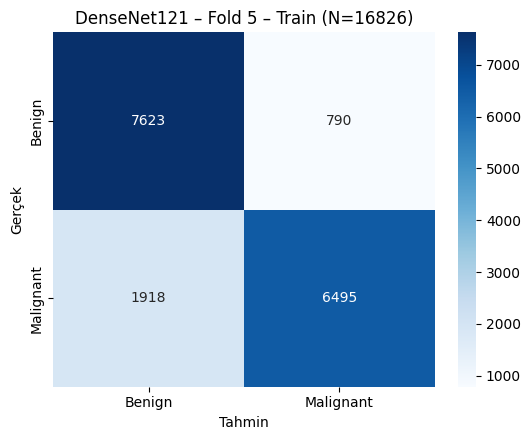

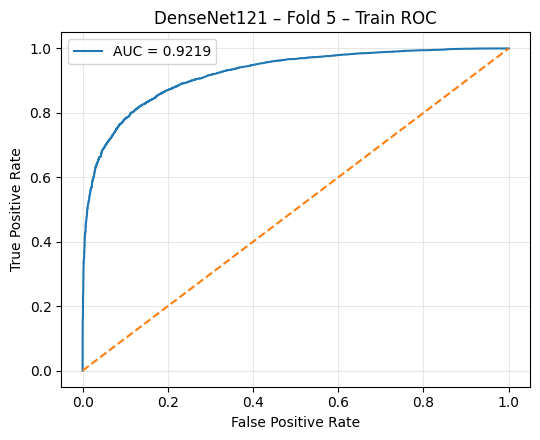

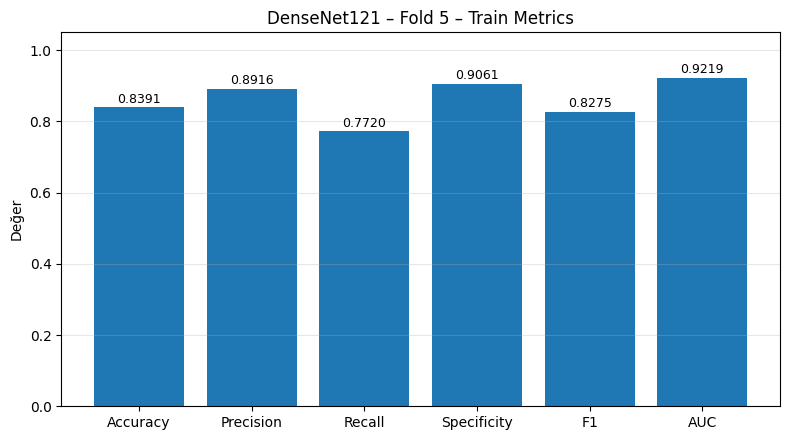

...

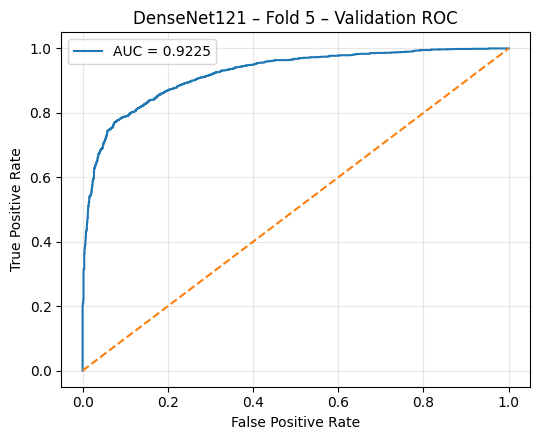

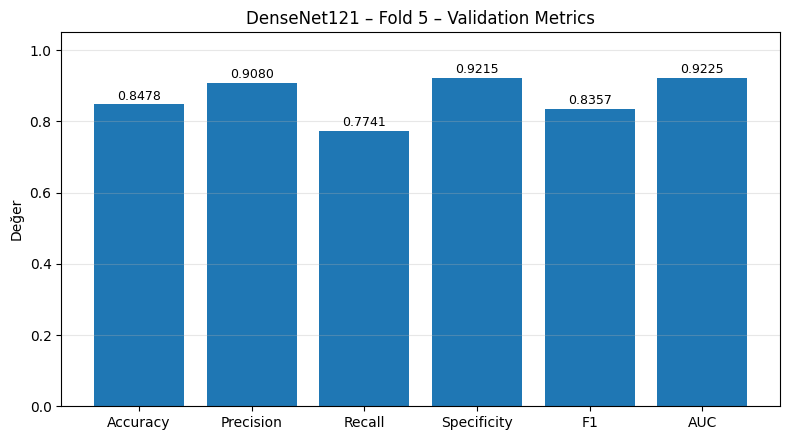

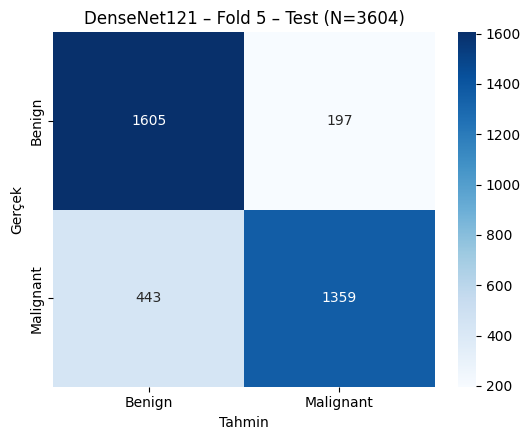

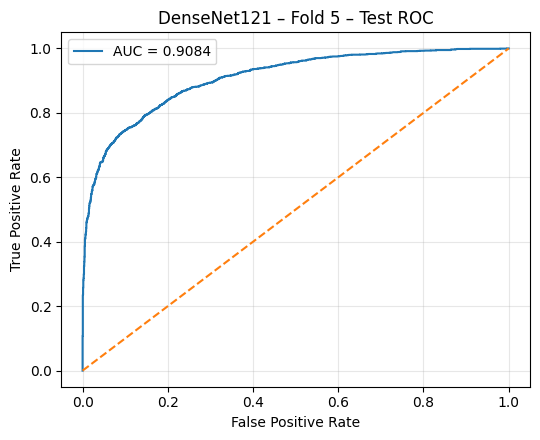

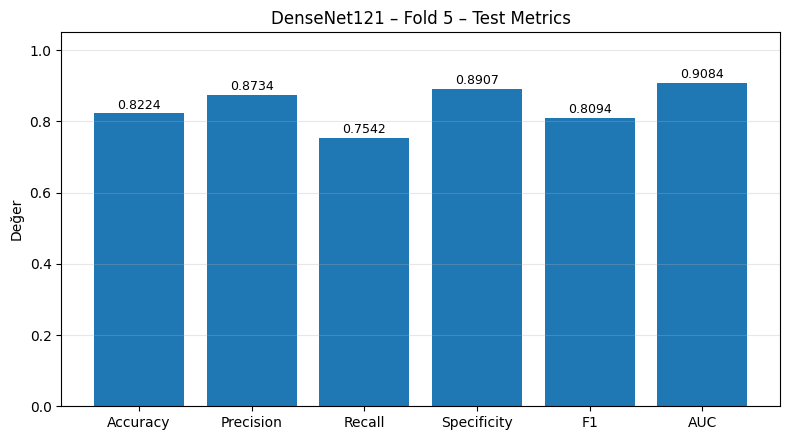

DenseNet121 – Fold 5 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7623.0,790.0,1918.0,6495.0,0.839059,0.891558,0.772019,0.906098,0.827494,0.921873,0.365159
Validation,3594.0,1656.0,141.0,406.0,1391.0,0.847802,0.907963,0.774068,0.921536,0.835686,0.922483,0.364288
Test,3604.0,1605.0,197.0,443.0,1359.0,0.822420,0.873393,0.754162,0.890677,0.809410,0.908356,0.392138


✓ DenseNet121 Fold 5: best epoch 9 | Test acc 0.8224
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 158MB/s]


EfficientNet-B0 | Fold 1 | Epoch 01/10 | Train loss 0.4879 acc 0.7645 | Val loss 0.4144 acc 0.8233
EfficientNet-B0 | Fold 1 | Epoch 02/10 | Train loss 0.3828 acc 0.8339 | Val loss 0.3626 acc 0.8422
EfficientNet-B0 | Fold 1 | Epoch 03/10 | Train loss 0.3427 acc 0.8539 | Val loss 0.3380 acc 0.8495
EfficientNet-B0 | Fold 1 | Epoch 04/10 | Train loss 0.3179 acc 0.8692 | Val loss 0.3106 acc 0.8723
EfficientNet-B0 | Fold 1 | Epoch 05/10 | Train loss 0.2977 acc 0.8786 | Val loss 0.2996 acc 0.8773
EfficientNet-B0 | Fold 1 | Epoch 06/10 | Train loss 0.2844 acc 0.8840 | Val loss 0.2870 acc 0.8823
EfficientNet-B0 | Fold 1 | Epoch 07/10 | Train loss 0.2718 acc 0.8913 | Val loss 0.2765 acc 0.8909
EfficientNet-B0 | Fold 1 | Epoch 08/10 | Train loss 0.2627 acc 0.8968 | Val loss 0.2682 acc 0.8915
EfficientNet-B0 | Fold 1 | Epoch 09/10 | Train loss 0.2558 acc 0.8995 | Val loss 0.2641 acc 0.8926
EfficientNet-B0 | Fold 1 | Epoch 10/10 | Train loss 0.2466 acc 0.9024 | Val loss 0.2600 acc 0.8943


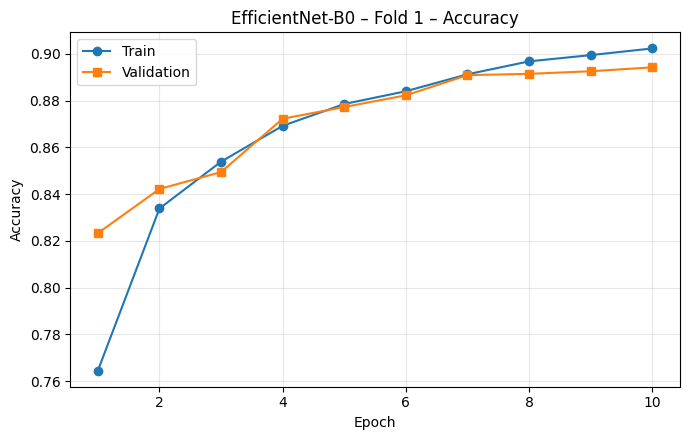

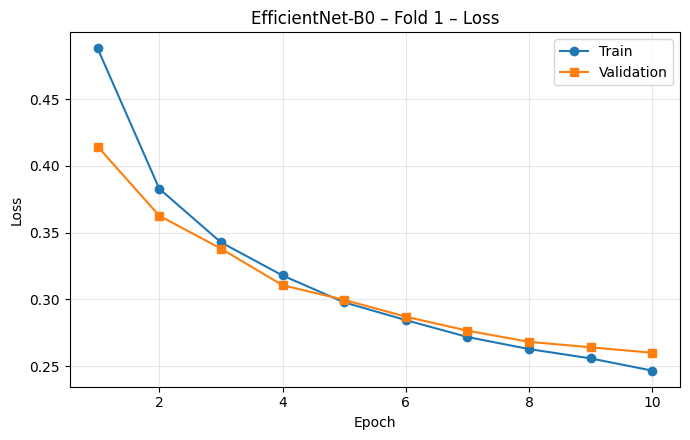

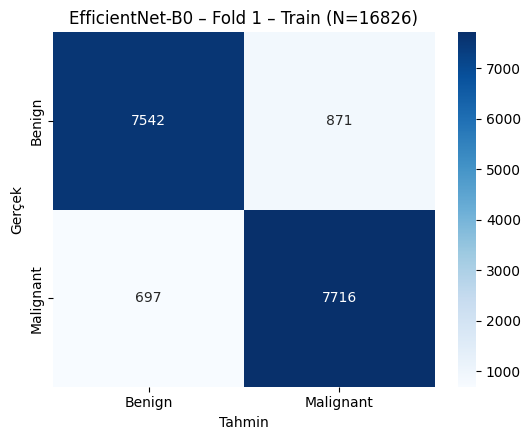

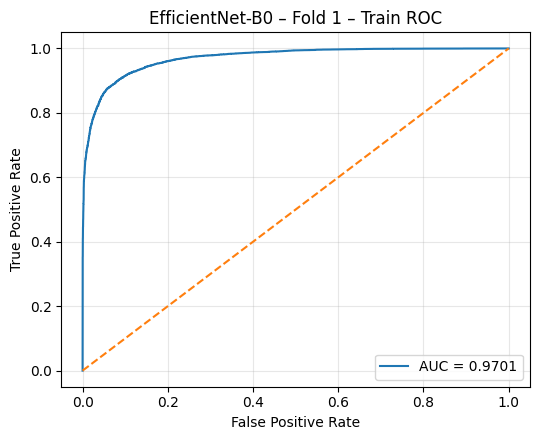

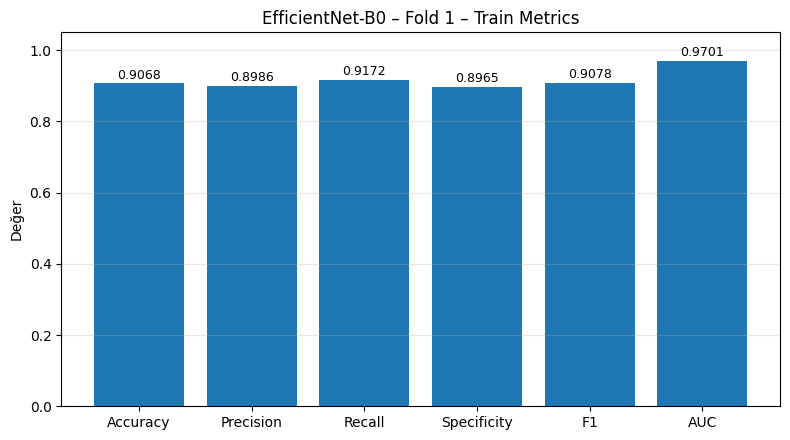

...

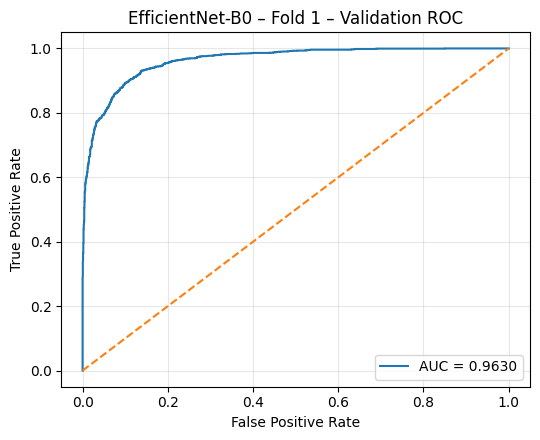

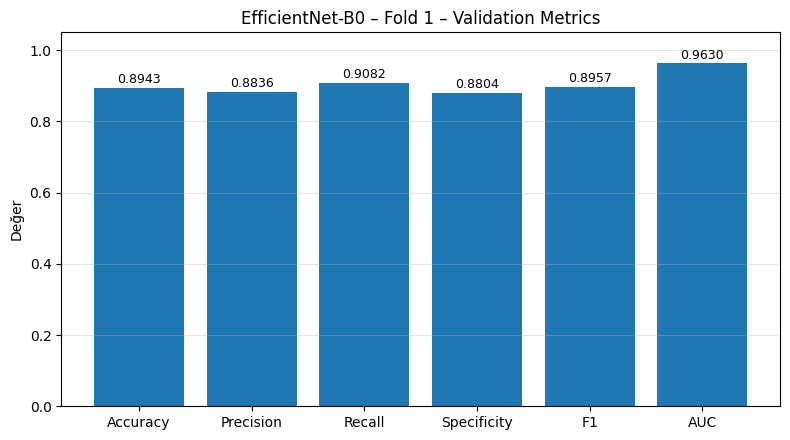

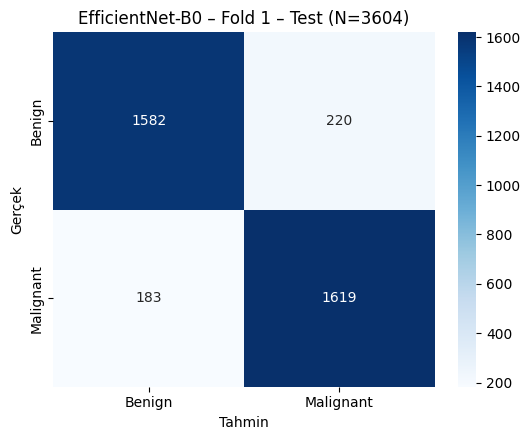

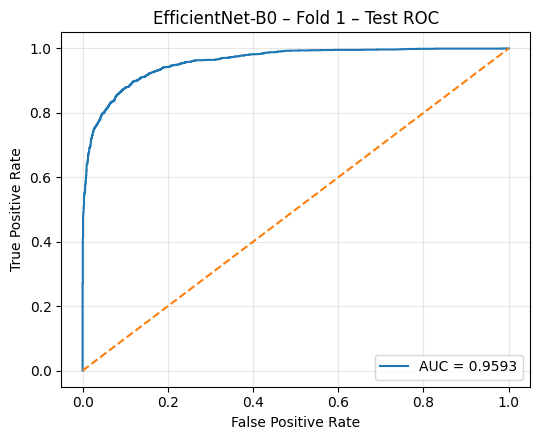

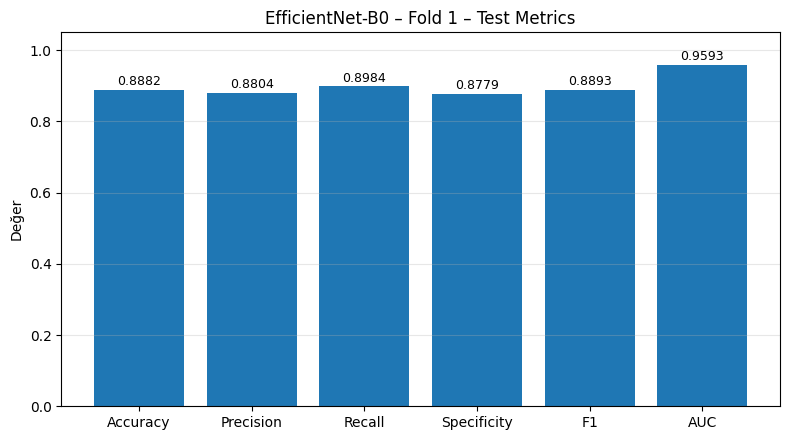

EfficientNet-B0 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7542.0,871.0,697.0,7716.0,0.906811,0.898568,0.917152,0.896470,0.907765,0.970101,0.239529
Validation,3594.0,1582.0,215.0,165.0,1632.0,0.894268,0.883595,0.908180,0.880356,0.895719,0.962953,0.259961
Test,3604.0,1582.0,220.0,183.0,1619.0,0.888180,0.880370,0.898446,0.877913,0.889316,0.959267,0.268110


✓ EfficientNet-B0 Fold 1: best epoch 10 | Test acc 0.8882
EfficientNet-B0 | Fold 2 | Epoch 01/10 | Train loss 0.4883 acc 0.7639 | Val loss 0.4135 acc 0.8194
EfficientNet-B0 | Fold 2 | Epoch 02/10 | Train loss 0.3814 acc 0.8352 | Val loss 0.3677 acc 0.8481
EfficientNet-B0 | Fold 2 | Epoch 03/10 | Train loss 0.3408 acc 0.8574 | Val loss 0.3515 acc 0.8478
EfficientNet-B0 | Fold 2 | Epoch 04/10 | Train loss 0.3154 acc 0.8691 | Val loss 0.3181 acc 0.8737
EfficientNet-B0 | Fold 2 | Epoch 05/10 | Train loss 0.2945 acc 0.8805 | Val loss 0.3063 acc 0.8726
EfficientNet-B0 | Fold 2 | Epoch 06/10 | Train loss 0.2801 acc 0.8844 | Val loss 0.2950 acc 0.8784
EfficientNet-B0 | Fold 2 | Epoch 07/10 | Train loss 0.2694 acc 0.8885 | Val loss 0.2869 acc 0.8845
EfficientNet-B0 | Fold 2 | Epoch 08/10 | Train loss 0.2591 acc 0.8978 | Val loss 0.2776 acc 0.8870
EfficientNet-B0 | Fold 2 | Epoch 09/10 | Train loss 0.2518 acc 0.9016 | Val loss 0.2705 acc 0.8893
EfficientNet-B0 | Fold 2 | Epoch 10/10 | Train loss

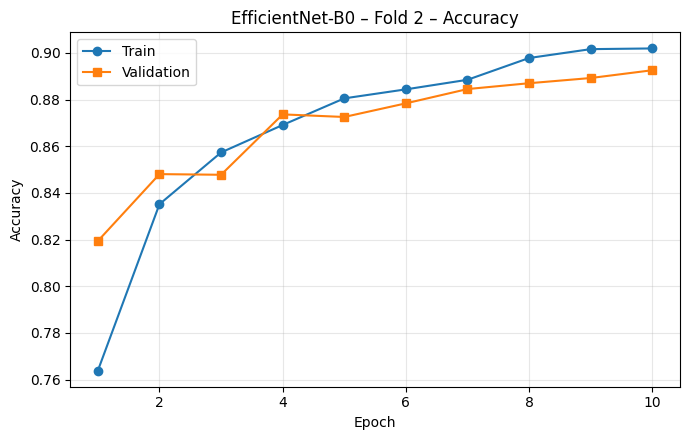

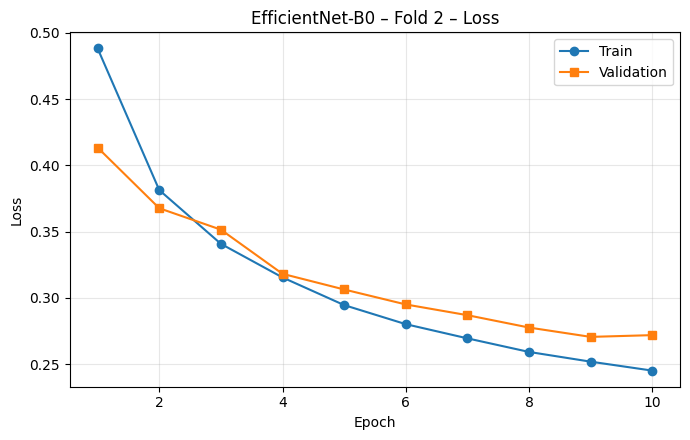

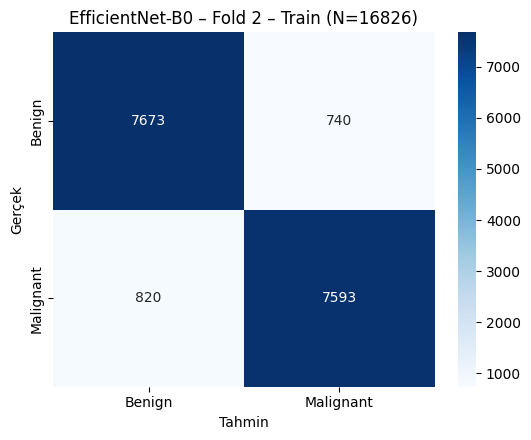

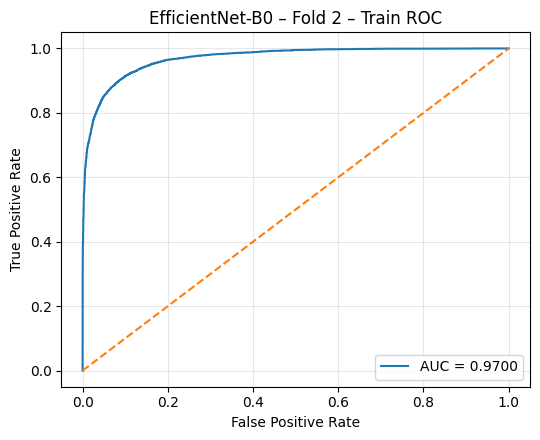

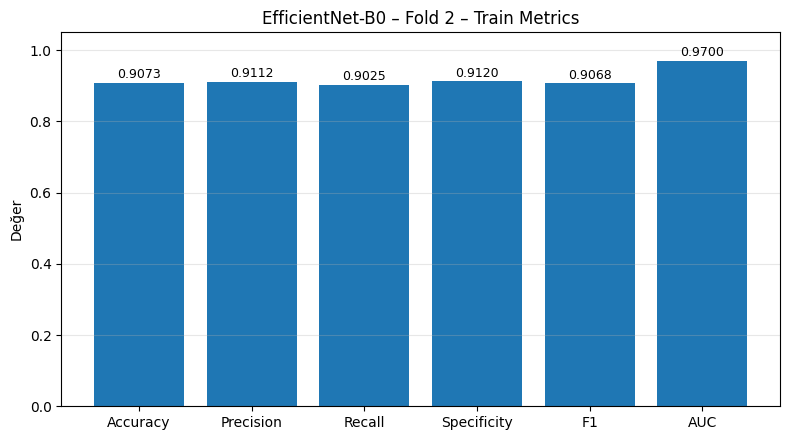

...

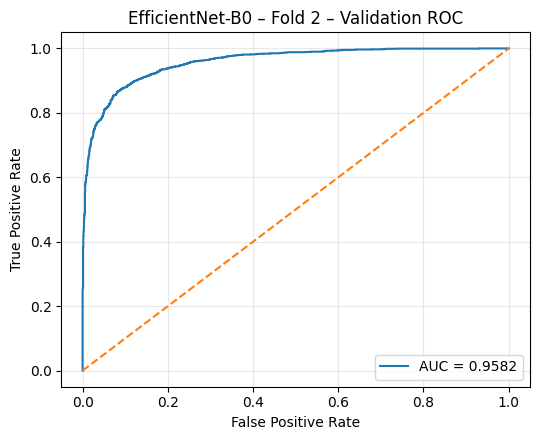

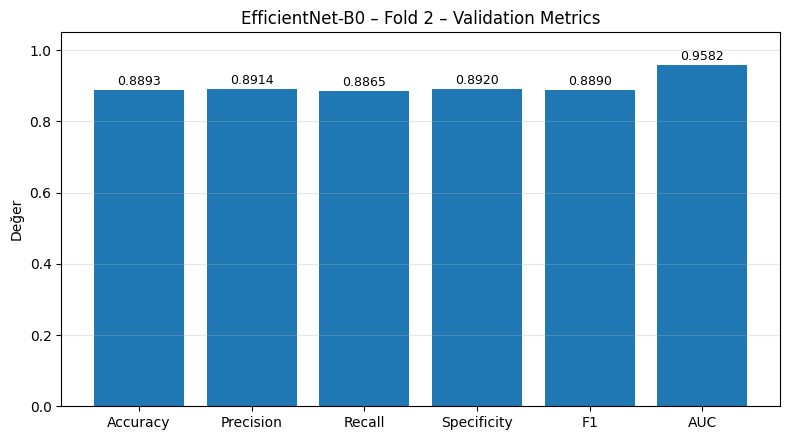

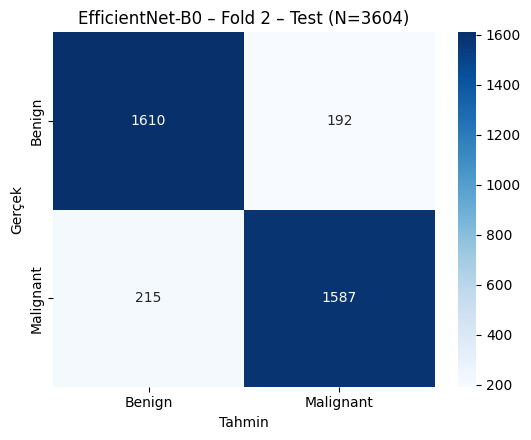

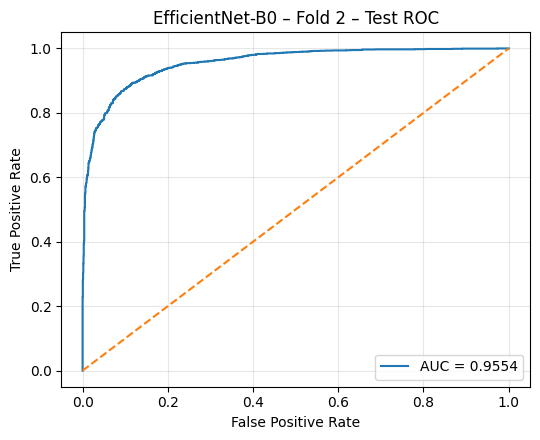

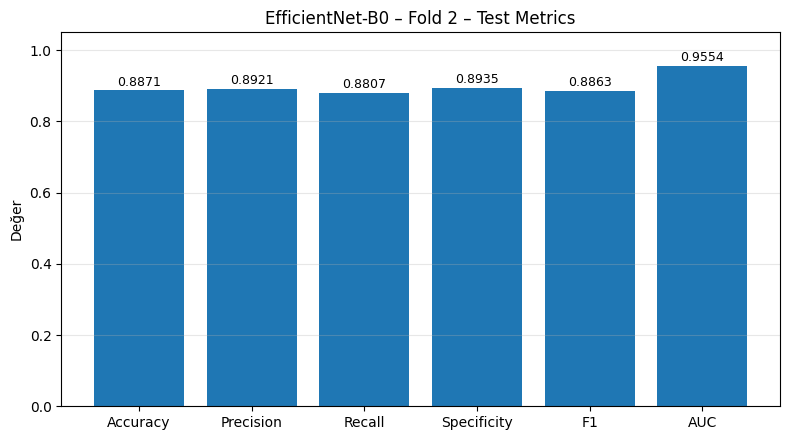

EfficientNet-B0 – Fold 2 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7673.0,740.0,820.0,7593.0,0.907286,0.911196,0.902532,0.912041,0.906843,0.969974,0.239908
Validation,3594.0,1603.0,194.0,204.0,1593.0,0.889260,0.891438,0.886477,0.892042,0.888951,0.958174,0.270502
Test,3604.0,1610.0,192.0,215.0,1587.0,0.887070,0.892074,0.880688,0.893452,0.886345,0.955405,0.277095


✓ EfficientNet-B0 Fold 2: best epoch 9 | Test acc 0.8871
EfficientNet-B0 | Fold 3 | Epoch 01/10 | Train loss 0.4877 acc 0.7648 | Val loss 0.4150 acc 0.8152
EfficientNet-B0 | Fold 3 | Epoch 02/10 | Train loss 0.3837 acc 0.8322 | Val loss 0.3574 acc 0.8381
EfficientNet-B0 | Fold 3 | Epoch 03/10 | Train loss 0.3426 acc 0.8561 | Val loss 0.3334 acc 0.8592
EfficientNet-B0 | Fold 3 | Epoch 04/10 | Train loss 0.3173 acc 0.8681 | Val loss 0.3125 acc 0.8676
EfficientNet-B0 | Fold 3 | Epoch 05/10 | Train loss 0.2977 acc 0.8788 | Val loss 0.2984 acc 0.8717
EfficientNet-B0 | Fold 3 | Epoch 06/10 | Train loss 0.2830 acc 0.8873 | Val loss 0.2866 acc 0.8781
EfficientNet-B0 | Fold 3 | Epoch 07/10 | Train loss 0.2711 acc 0.8927 | Val loss 0.2786 acc 0.8837
EfficientNet-B0 | Fold 3 | Epoch 08/10 | Train loss 0.2626 acc 0.8951 | Val loss 0.2666 acc 0.8887
EfficientNet-B0 | Fold 3 | Epoch 09/10 | Train loss 0.2540 acc 0.9001 | Val loss 0.2589 acc 0.8918
EfficientNet-B0 | Fold 3 | Epoch 10/10 | Train loss 

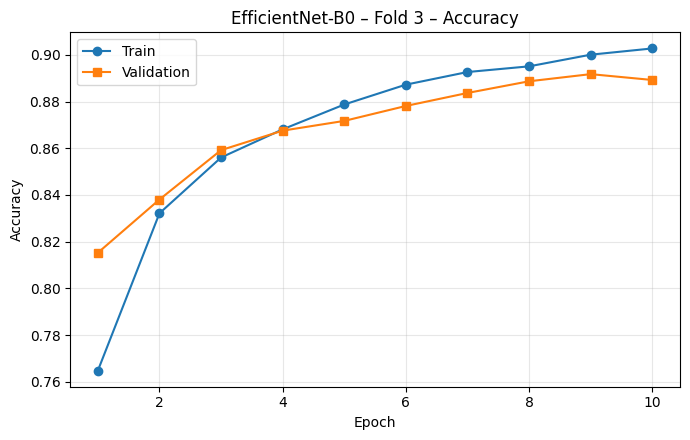

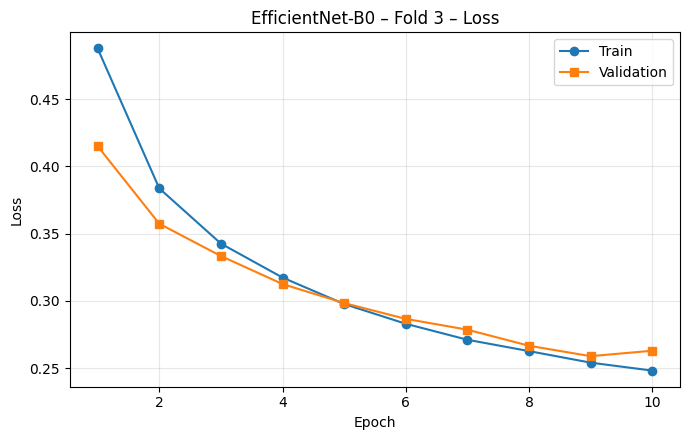

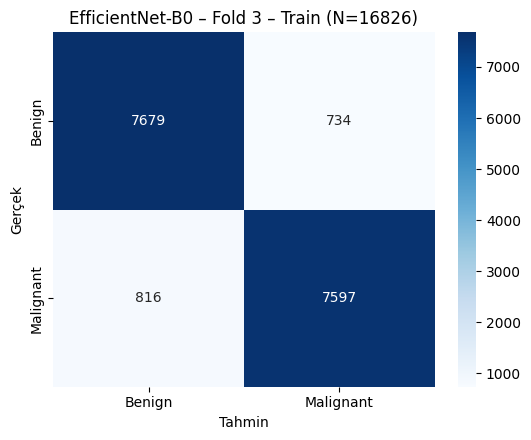

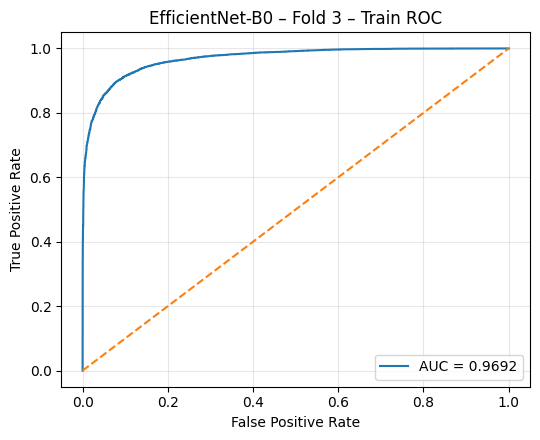

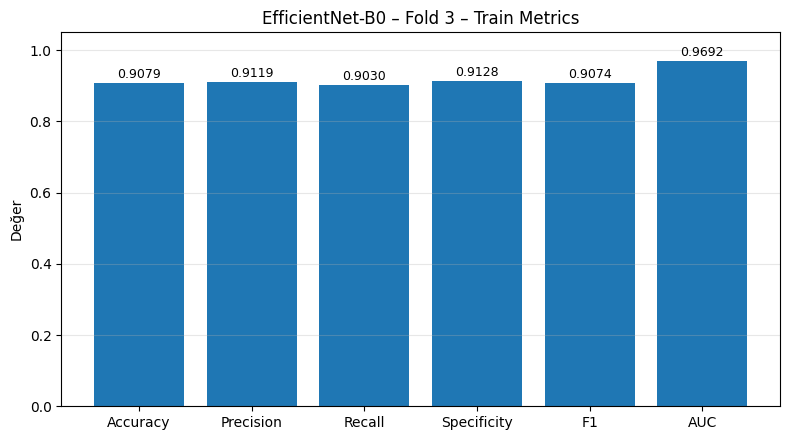

...

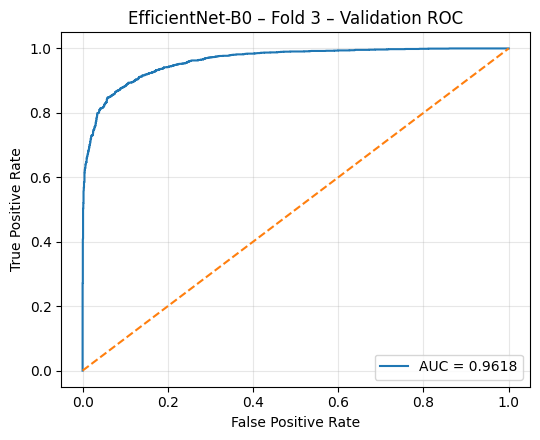

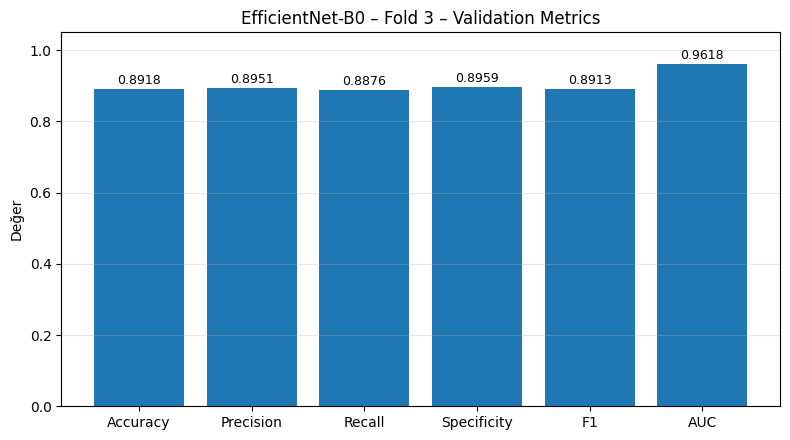

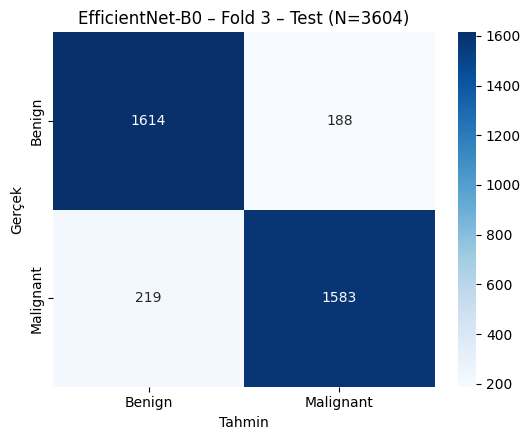

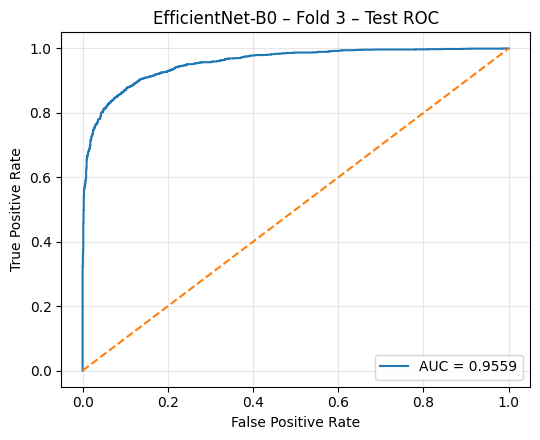

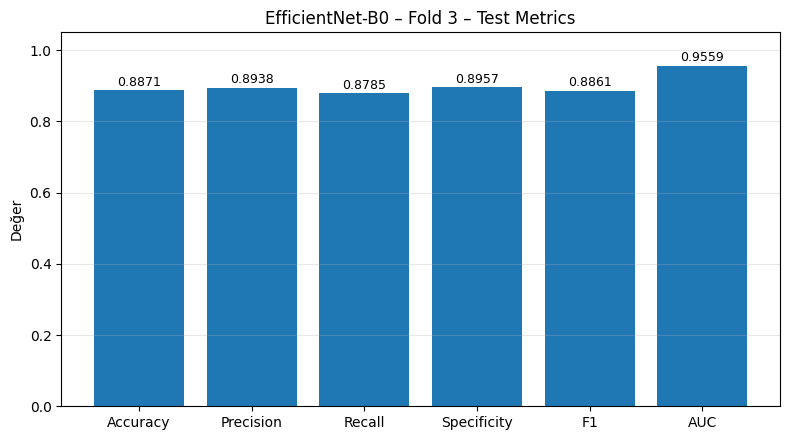

EfficientNet-B0 – Fold 3 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7679.0,734.0,816.0,7597.0,0.907881,0.911895,0.903007,0.912754,0.90743,0.969176,0.242678
Validation,3594.0,1610.0,187.0,202.0,1595.0,0.891764,0.895062,0.887590,0.895938,0.89131,0.961809,0.258872
Test,3604.0,1614.0,188.0,219.0,1583.0,0.887070,0.893845,0.878468,0.895671,0.88609,0.955931,0.275183


✓ EfficientNet-B0 Fold 3: best epoch 9 | Test acc 0.8871
EfficientNet-B0 | Fold 4 | Epoch 01/10 | Train loss 0.4867 acc 0.7660 | Val loss 0.4229 acc 0.8044
EfficientNet-B0 | Fold 4 | Epoch 02/10 | Train loss 0.3791 acc 0.8369 | Val loss 0.3738 acc 0.8364
EfficientNet-B0 | Fold 4 | Epoch 03/10 | Train loss 0.3391 acc 0.8561 | Val loss 0.3555 acc 0.8392
EfficientNet-B0 | Fold 4 | Epoch 04/10 | Train loss 0.3152 acc 0.8680 | Val loss 0.3200 acc 0.8659
EfficientNet-B0 | Fold 4 | Epoch 05/10 | Train loss 0.2949 acc 0.8794 | Val loss 0.3079 acc 0.8717
EfficientNet-B0 | Fold 4 | Epoch 06/10 | Train loss 0.2813 acc 0.8879 | Val loss 0.2984 acc 0.8726
EfficientNet-B0 | Fold 4 | Epoch 07/10 | Train loss 0.2688 acc 0.8943 | Val loss 0.2976 acc 0.8773
EfficientNet-B0 | Fold 4 | Epoch 08/10 | Train loss 0.2598 acc 0.8960 | Val loss 0.2778 acc 0.8865
EfficientNet-B0 | Fold 4 | Epoch 09/10 | Train loss 0.2533 acc 0.9005 | Val loss 0.2730 acc 0.8876
EfficientNet-B0 | Fold 4 | Epoch 10/10 | Train loss 

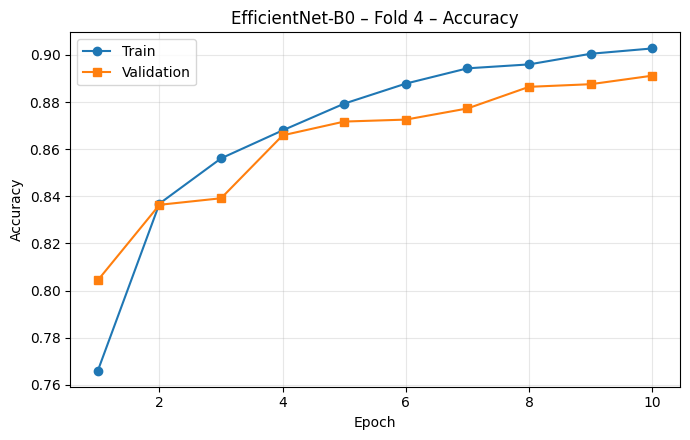

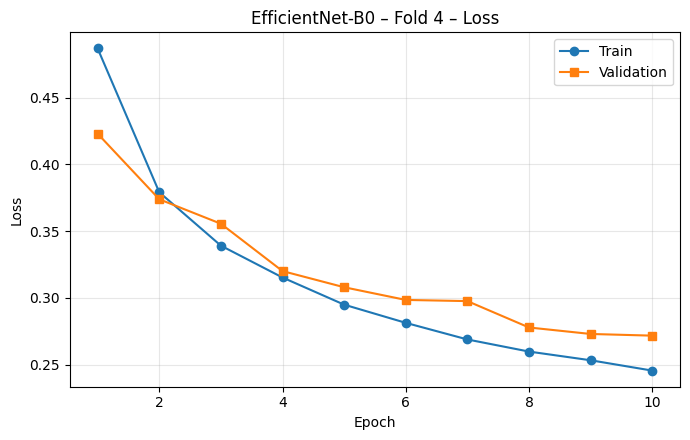

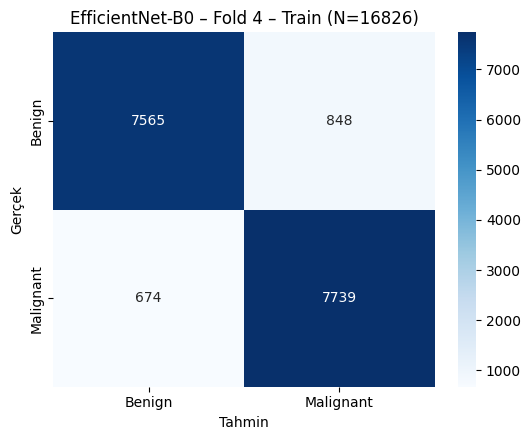

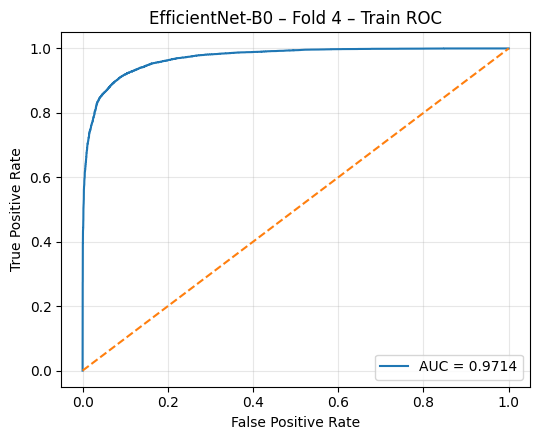

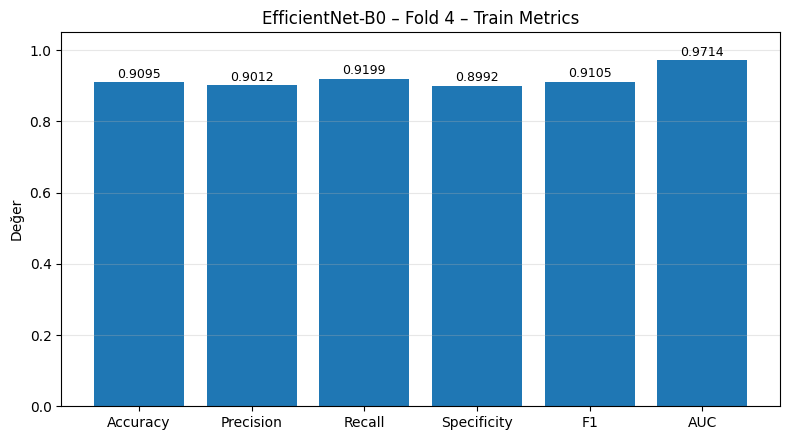

...

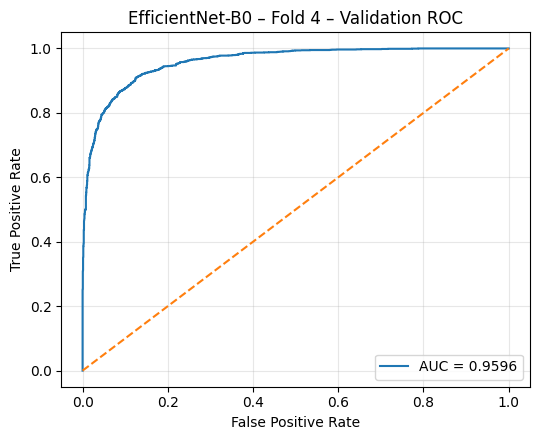

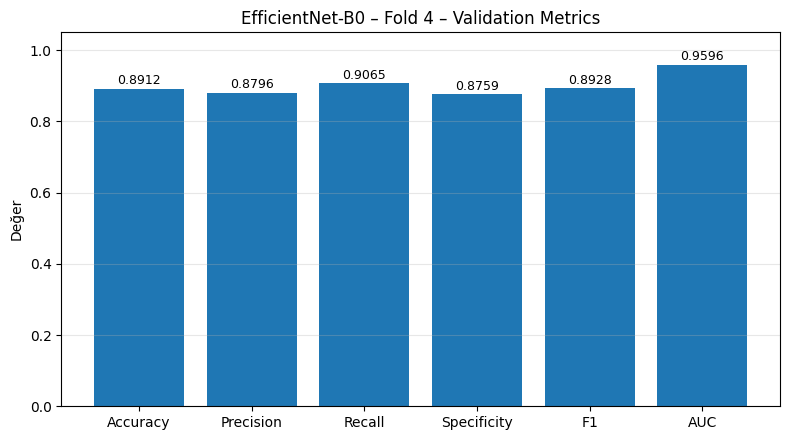

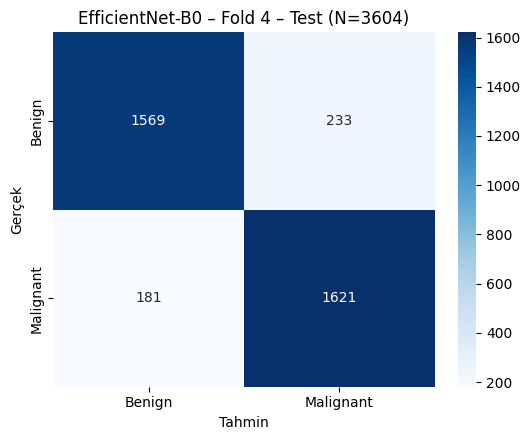

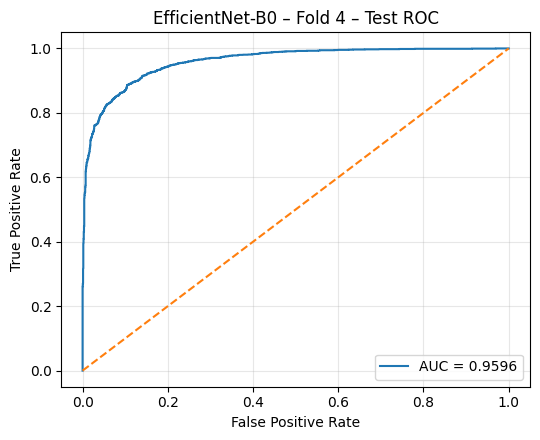

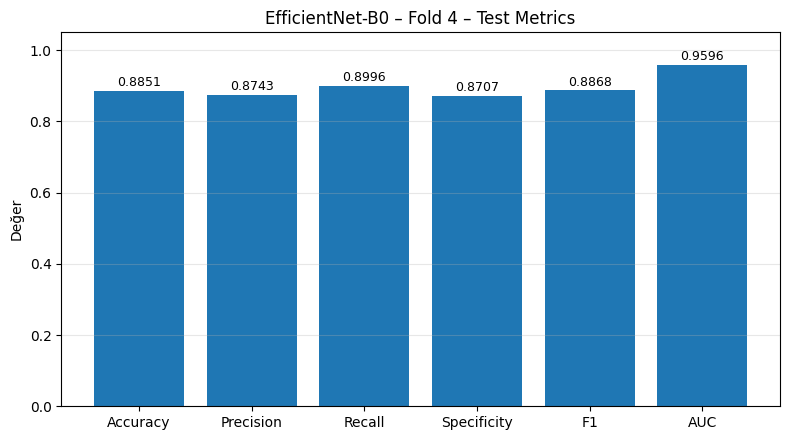

EfficientNet-B0 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7565.0,848.0,674.0,7739.0,0.909545,0.901246,0.919886,0.899204,0.910471,0.971382,0.236464
Validation,3594.0,1574.0,223.0,168.0,1629.0,0.891208,0.879590,0.906511,0.875904,0.892847,0.959605,0.271701
Test,3604.0,1569.0,233.0,181.0,1621.0,0.885128,0.874326,0.899556,0.870699,0.886761,0.959618,0.268545


✓ EfficientNet-B0 Fold 4: best epoch 10 | Test acc 0.8851
EfficientNet-B0 | Fold 5 | Epoch 01/10 | Train loss 0.4875 acc 0.7665 | Val loss 0.4067 acc 0.8197
EfficientNet-B0 | Fold 5 | Epoch 02/10 | Train loss 0.3809 acc 0.8365 | Val loss 0.3507 acc 0.8556
EfficientNet-B0 | Fold 5 | Epoch 03/10 | Train loss 0.3406 acc 0.8579 | Val loss 0.3266 acc 0.8614
EfficientNet-B0 | Fold 5 | Epoch 04/10 | Train loss 0.3160 acc 0.8701 | Val loss 0.3114 acc 0.8703
EfficientNet-B0 | Fold 5 | Epoch 05/10 | Train loss 0.2952 acc 0.8801 | Val loss 0.2963 acc 0.8745
EfficientNet-B0 | Fold 5 | Epoch 06/10 | Train loss 0.2803 acc 0.8883 | Val loss 0.2855 acc 0.8787
EfficientNet-B0 | Fold 5 | Epoch 07/10 | Train loss 0.2701 acc 0.8914 | Val loss 0.2804 acc 0.8815
EfficientNet-B0 | Fold 5 | Epoch 08/10 | Train loss 0.2610 acc 0.8961 | Val loss 0.2713 acc 0.8837
EfficientNet-B0 | Fold 5 | Epoch 09/10 | Train loss 0.2520 acc 0.9010 | Val loss 0.2703 acc 0.8887
EfficientNet-B0 | Fold 5 | Epoch 10/10 | Train loss

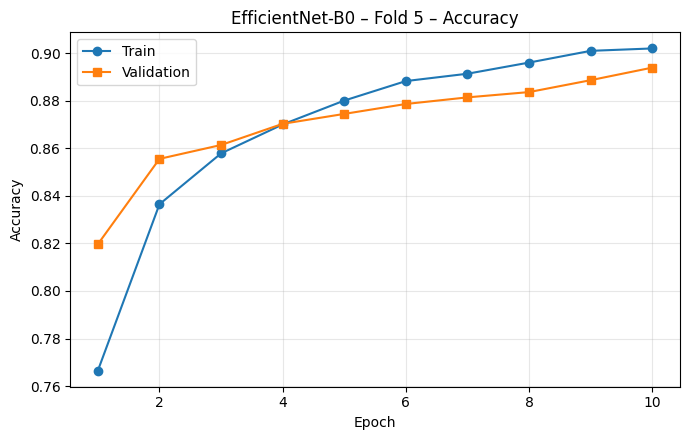

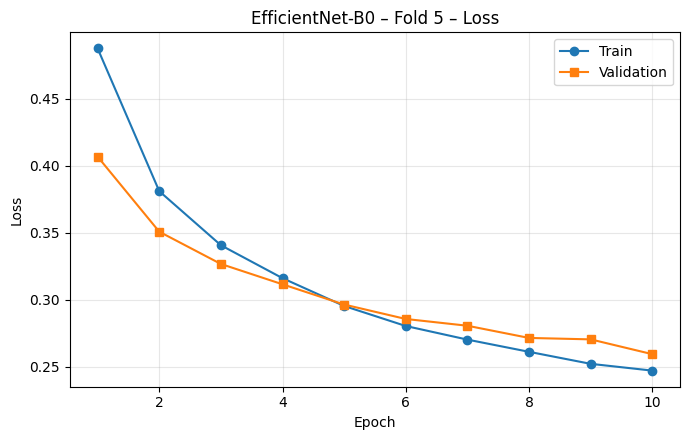

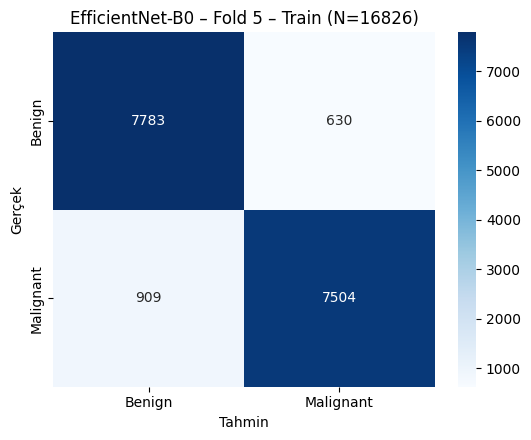

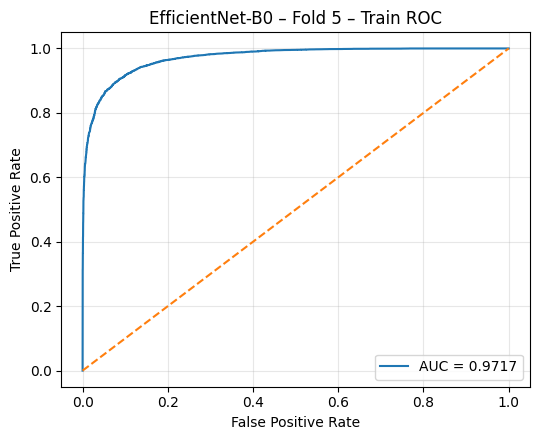

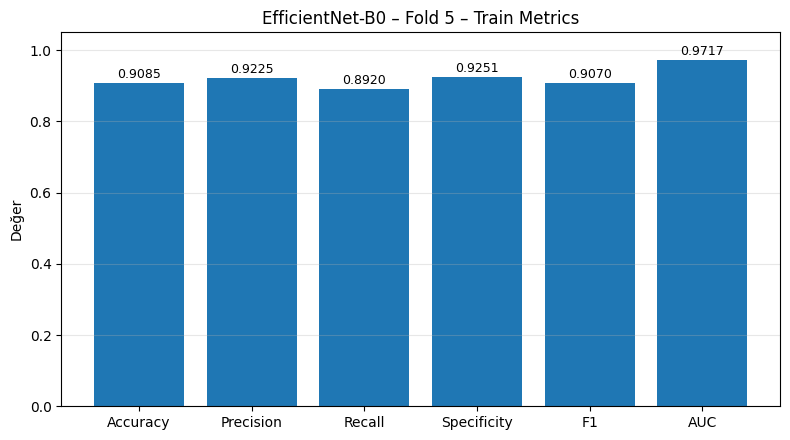

...

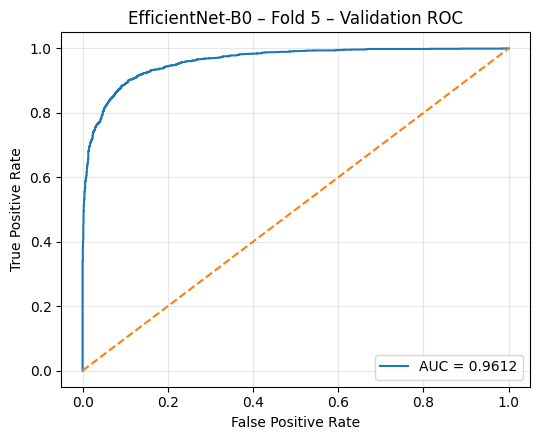

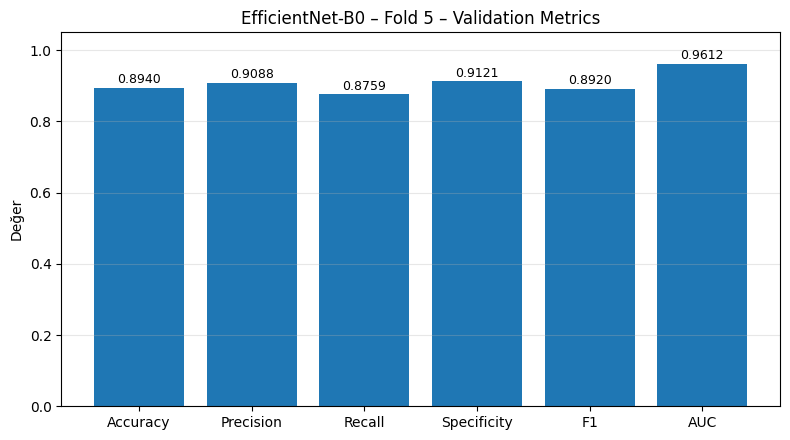

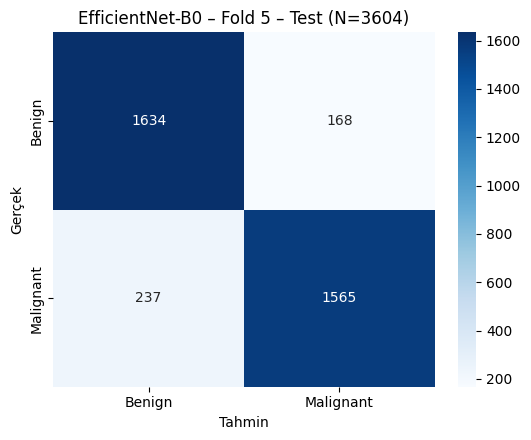

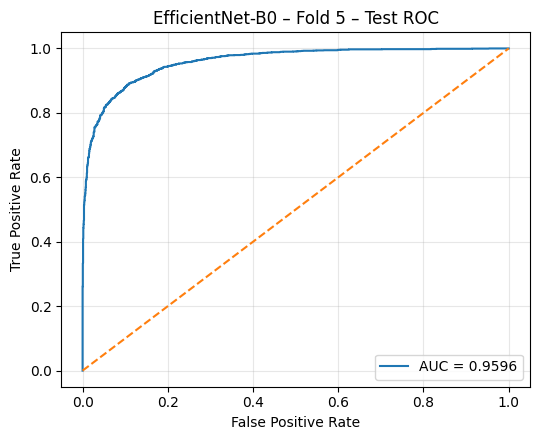

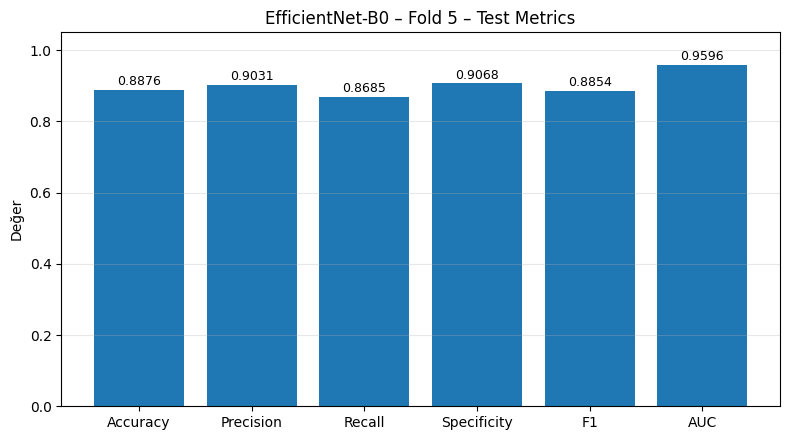

EfficientNet-B0 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7783.0,630.0,909.0,7504.0,0.908534,0.922547,0.891953,0.925116,0.906992,0.971671,0.233455
Validation,3594.0,1639.0,158.0,223.0,1574.0,0.893990,0.908776,0.875904,0.912076,0.892037,0.961199,0.259221
Test,3604.0,1634.0,168.0,237.0,1565.0,0.887625,0.903058,0.868479,0.906770,0.885431,0.959561,0.264903


✓ EfficientNet-B0 Fold 5: best epoch 10 | Test acc 0.8876
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 129MB/s]


MobileNetV2 | Fold 1 | Epoch 01/10 | Train loss 0.5106 acc 0.7431 | Val loss 0.4478 acc 0.7966
MobileNetV2 | Fold 1 | Epoch 02/10 | Train loss 0.4163 acc 0.8098 | Val loss 0.4016 acc 0.8191
MobileNetV2 | Fold 1 | Epoch 03/10 | Train loss 0.3787 acc 0.8306 | Val loss 0.3718 acc 0.8350
MobileNetV2 | Fold 1 | Epoch 04/10 | Train loss 0.3569 acc 0.8457 | Val loss 0.3480 acc 0.8478
MobileNetV2 | Fold 1 | Epoch 05/10 | Train loss 0.3393 acc 0.8528 | Val loss 0.3401 acc 0.8548
MobileNetV2 | Fold 1 | Epoch 06/10 | Train loss 0.3250 acc 0.8616 | Val loss 0.3246 acc 0.8548
MobileNetV2 | Fold 1 | Epoch 07/10 | Train loss 0.3189 acc 0.8625 | Val loss 0.3249 acc 0.8550
MobileNetV2 | Fold 1 | Epoch 08/10 | Train loss 0.3043 acc 0.8725 | Val loss 0.3135 acc 0.8614
MobileNetV2 | Fold 1 | Epoch 09/10 | Train loss 0.2967 acc 0.8732 | Val loss 0.3023 acc 0.8687
MobileNetV2 | Fold 1 | Epoch 10/10 | Train loss 0.2934 acc 0.8757 | Val loss 0.3006 acc 0.8706


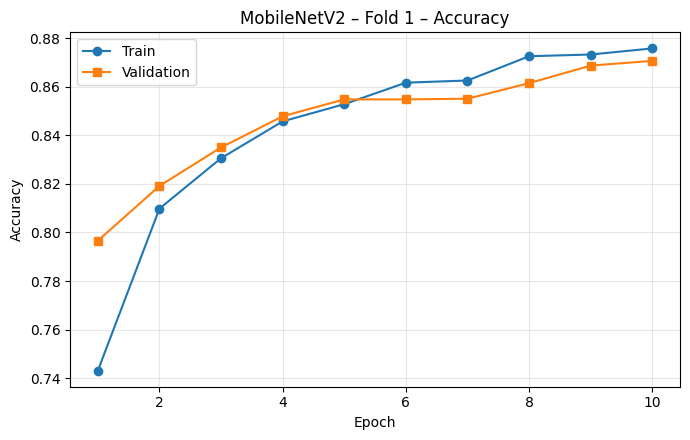

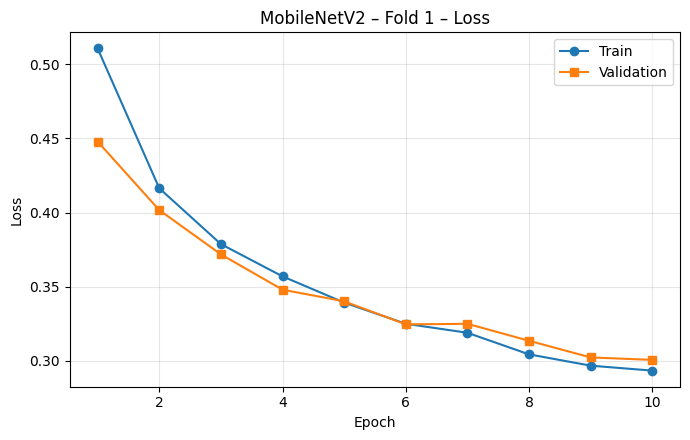

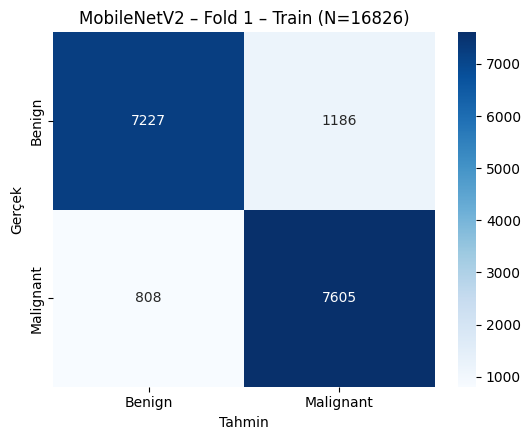

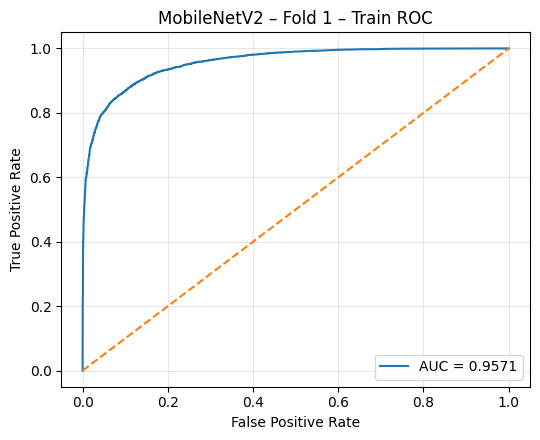

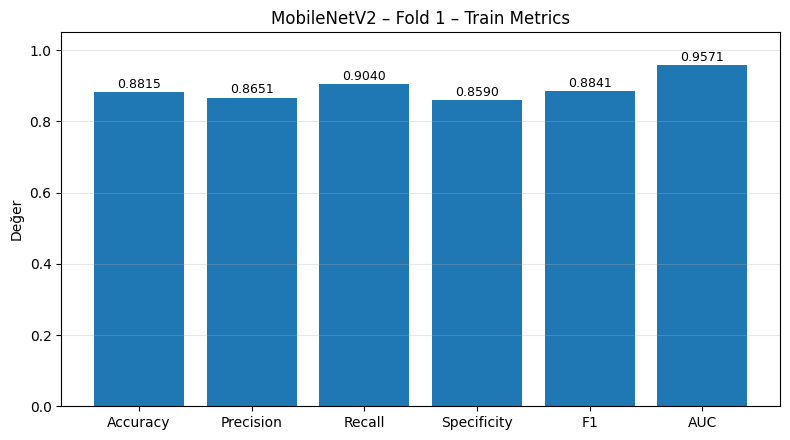

...

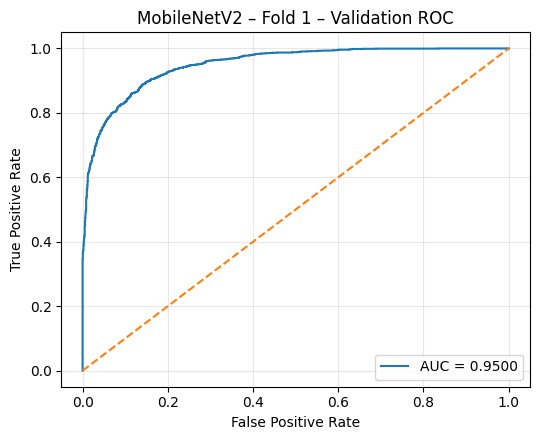

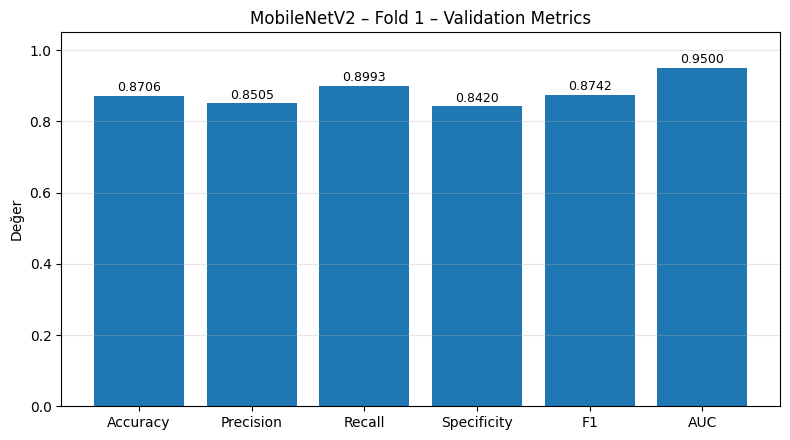

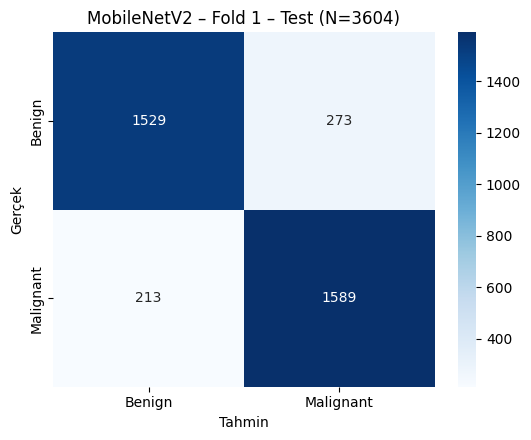

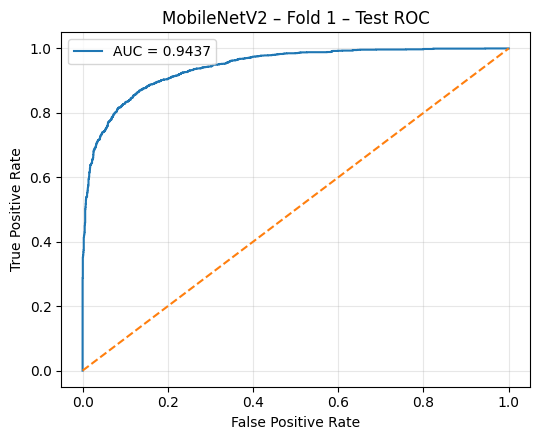

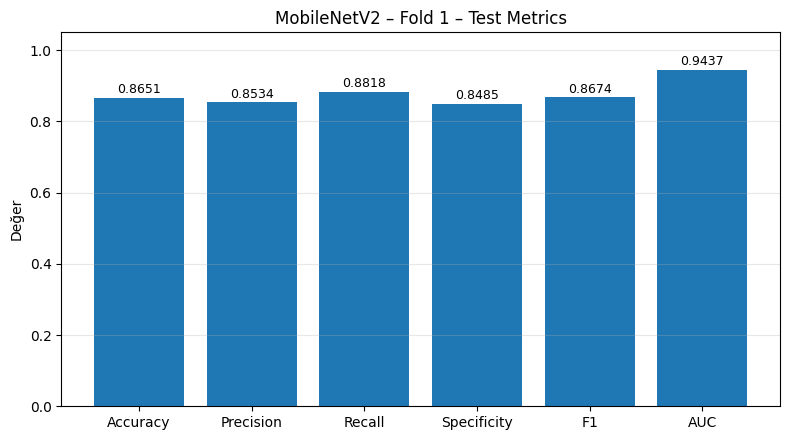

MobileNetV2 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7227.0,1186.0,808.0,7605.0,0.881493,0.865089,0.903958,0.859028,0.884097,0.957125,0.283029
Validation,3594.0,1513.0,284.0,181.0,1616.0,0.870618,0.850526,0.899277,0.841959,0.874222,0.949959,0.300622
Test,3604.0,1529.0,273.0,213.0,1589.0,0.865150,0.853383,0.881798,0.848502,0.867358,0.943656,0.309964


✓ MobileNetV2 Fold 1: best epoch 10 | Test acc 0.8651
MobileNetV2 | Fold 2 | Epoch 01/10 | Train loss 0.5081 acc 0.7457 | Val loss 0.4351 acc 0.8066
MobileNetV2 | Fold 2 | Epoch 02/10 | Train loss 0.4130 acc 0.8140 | Val loss 0.3917 acc 0.8275
MobileNetV2 | Fold 2 | Epoch 03/10 | Train loss 0.3765 acc 0.8325 | Val loss 0.3767 acc 0.8319
MobileNetV2 | Fold 2 | Epoch 04/10 | Train loss 0.3537 acc 0.8474 | Val loss 0.3858 acc 0.8216
MobileNetV2 | Fold 2 | Epoch 05/10 | Train loss 0.3383 acc 0.8550 | Val loss 0.3601 acc 0.8372
MobileNetV2 | Fold 2 | Epoch 06/10 | Train loss 0.3248 acc 0.8591 | Val loss 0.3527 acc 0.8439
MobileNetV2 | Fold 2 | Epoch 07/10 | Train loss 0.3136 acc 0.8659 | Val loss 0.3267 acc 0.8584
MobileNetV2 | Fold 2 | Epoch 08/10 | Train loss 0.3013 acc 0.8736 | Val loss 0.3154 acc 0.8623
MobileNetV2 | Fold 2 | Epoch 09/10 | Train loss 0.2950 acc 0.8760 | Val loss 0.3118 acc 0.8656
MobileNetV2 | Fold 2 | Epoch 10/10 | Train loss 0.2876 acc 0.8794 | Val loss 0.3040 acc 0.8

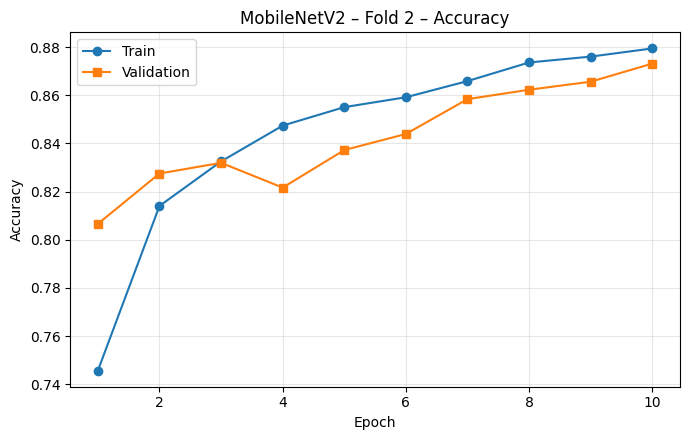

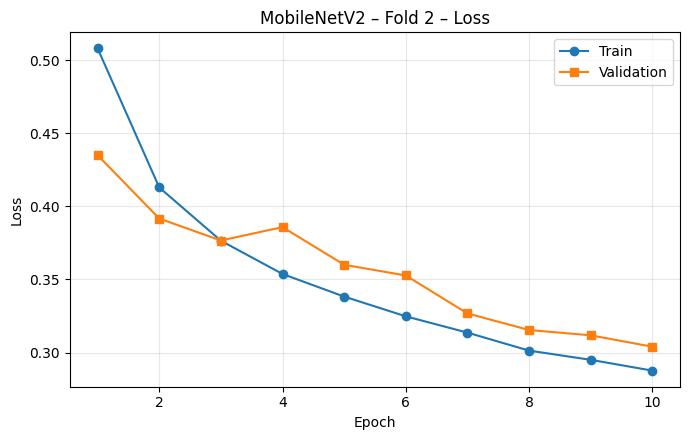

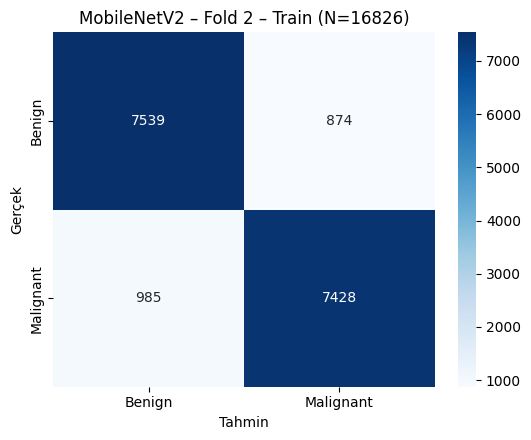

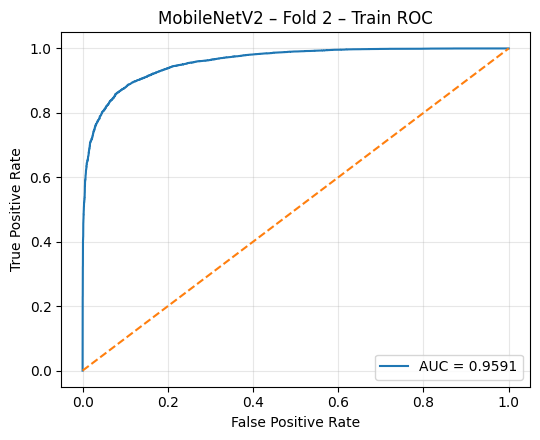

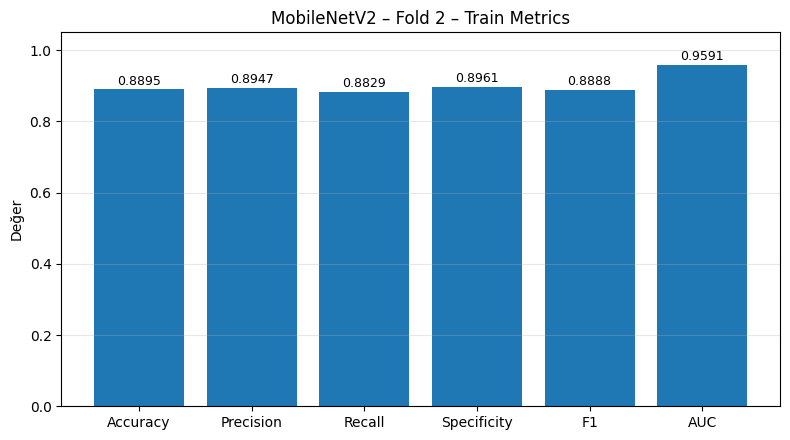

...

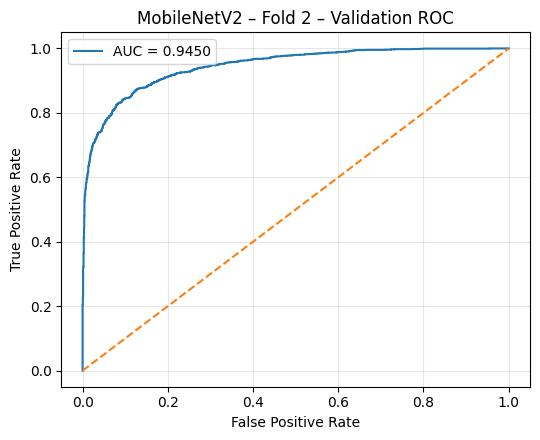

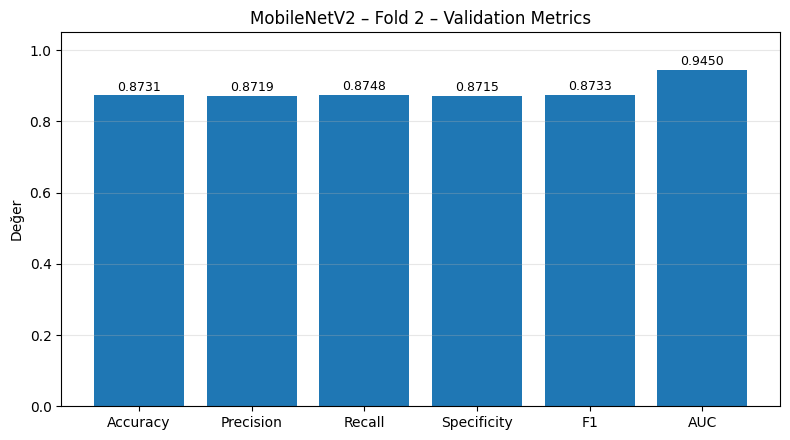

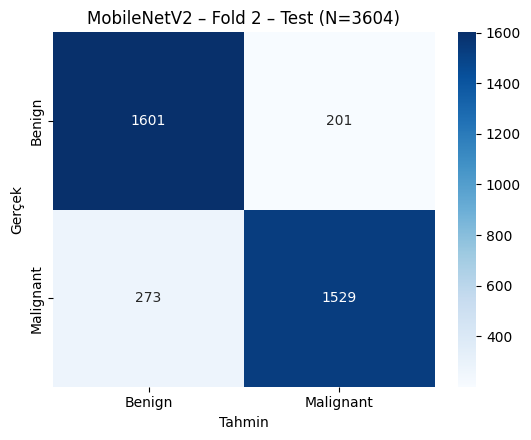

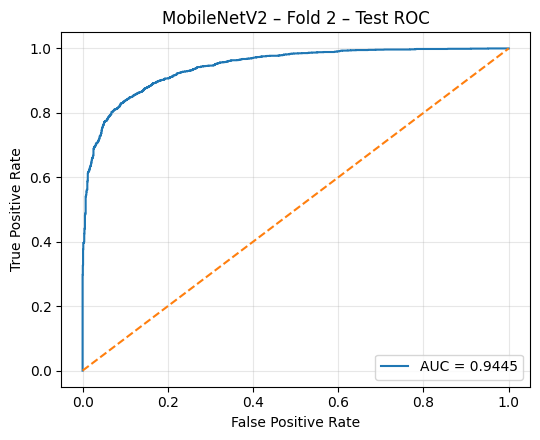

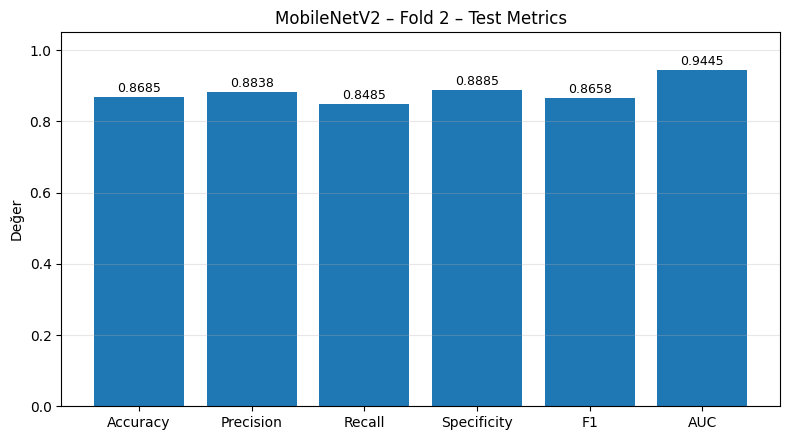

MobileNetV2 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7539.0,874.0,985.0,7428.0,0.889516,0.894724,0.882919,0.896113,0.888783,0.959130,0.273516
Validation,3594.0,1566.0,231.0,225.0,1572.0,0.873122,0.871880,0.874791,0.871452,0.873333,0.944958,0.303986
Test,3604.0,1601.0,201.0,273.0,1529.0,0.868479,0.883815,0.848502,0.888457,0.865798,0.944516,0.305756


✓ MobileNetV2 Fold 2: best epoch 10 | Test acc 0.8685
MobileNetV2 | Fold 3 | Epoch 01/10 | Train loss 0.5083 acc 0.7500 | Val loss 0.4503 acc 0.7844
MobileNetV2 | Fold 3 | Epoch 02/10 | Train loss 0.4128 acc 0.8126 | Val loss 0.4005 acc 0.8233
MobileNetV2 | Fold 3 | Epoch 03/10 | Train loss 0.3783 acc 0.8323 | Val loss 0.4045 acc 0.8114
MobileNetV2 | Fold 3 | Epoch 04/10 | Train loss 0.3549 acc 0.8449 | Val loss 0.3545 acc 0.8408
MobileNetV2 | Fold 3 | Epoch 05/10 | Train loss 0.3378 acc 0.8554 | Val loss 0.3410 acc 0.8478
MobileNetV2 | Fold 3 | Epoch 06/10 | Train loss 0.3236 acc 0.8611 | Val loss 0.3331 acc 0.8525
MobileNetV2 | Fold 3 | Epoch 07/10 | Train loss 0.3138 acc 0.8663 | Val loss 0.3392 acc 0.8453
MobileNetV2 | Fold 3 | Epoch 08/10 | Train loss 0.3028 acc 0.8712 | Val loss 0.3149 acc 0.8600
MobileNetV2 | Fold 3 | Epoch 09/10 | Train loss 0.2959 acc 0.8745 | Val loss 0.3149 acc 0.8617
MobileNetV2 | Fold 3 | Epoch 10/10 | Train loss 0.2894 acc 0.8769 | Val loss 0.3048 acc 0.8

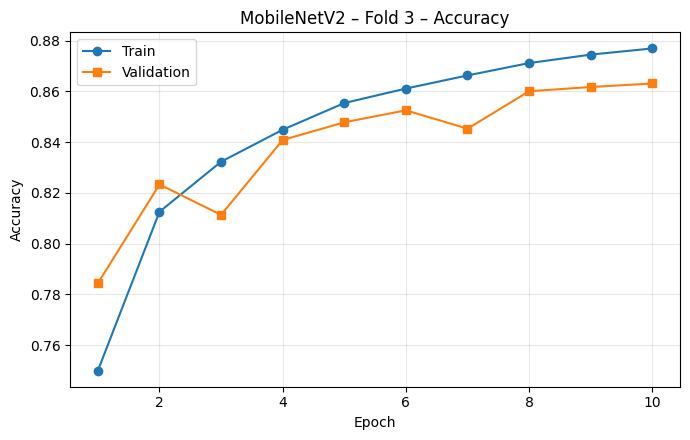

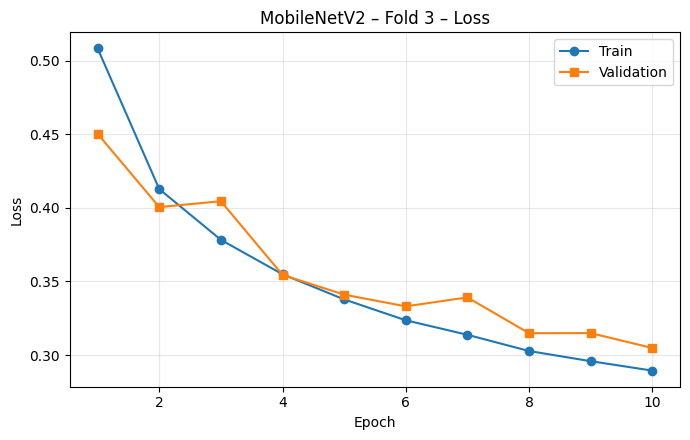

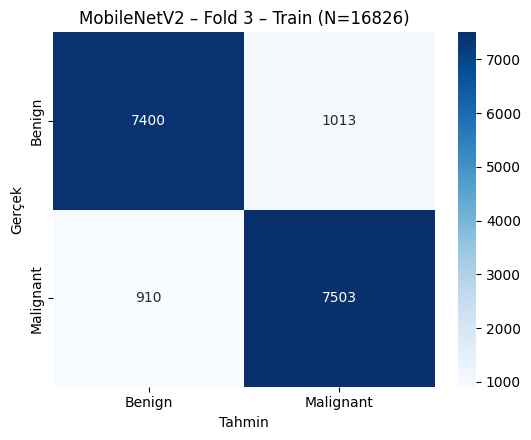

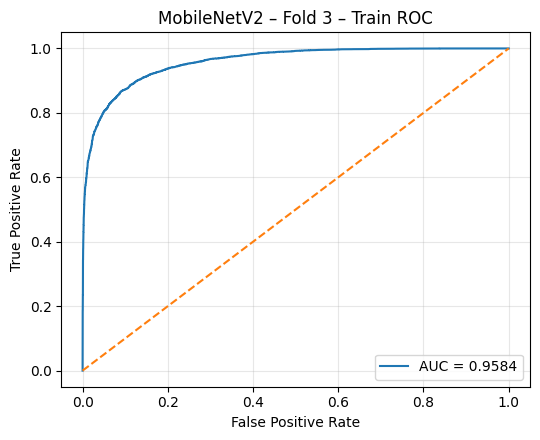

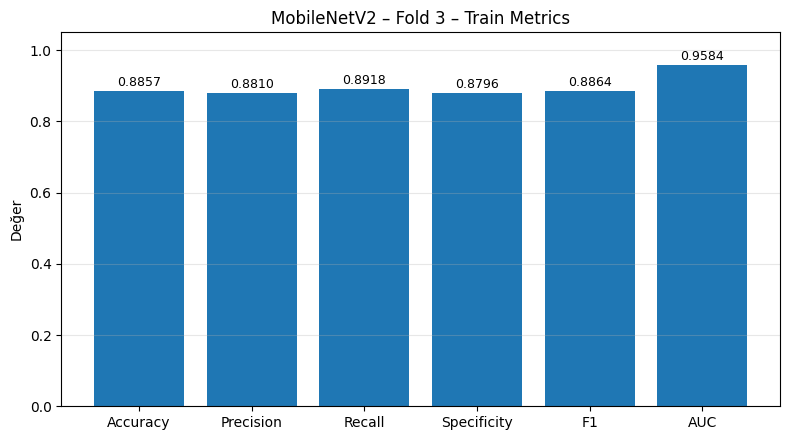

...

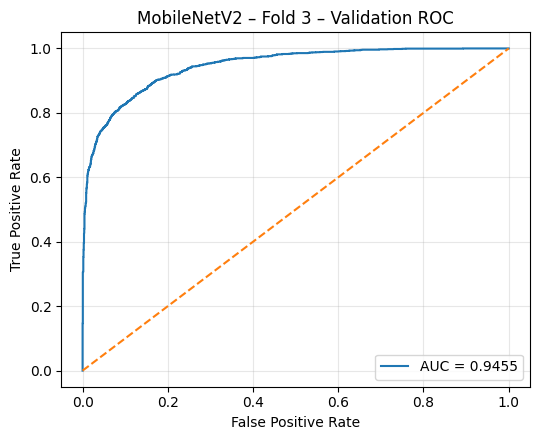

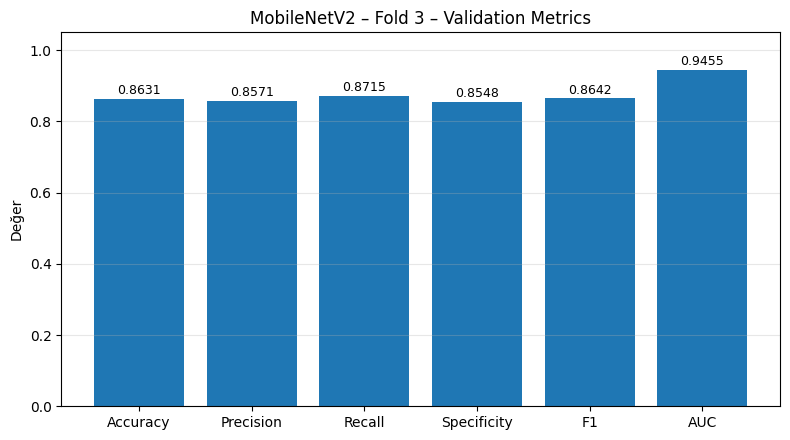

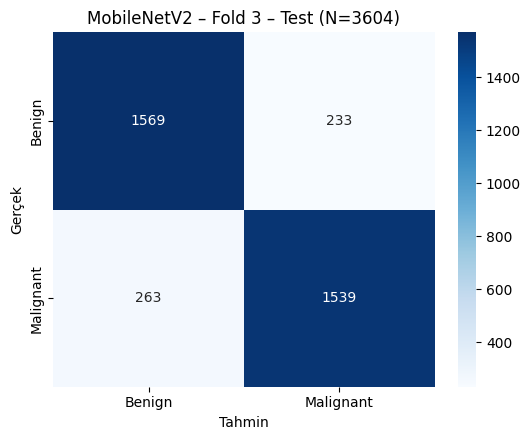

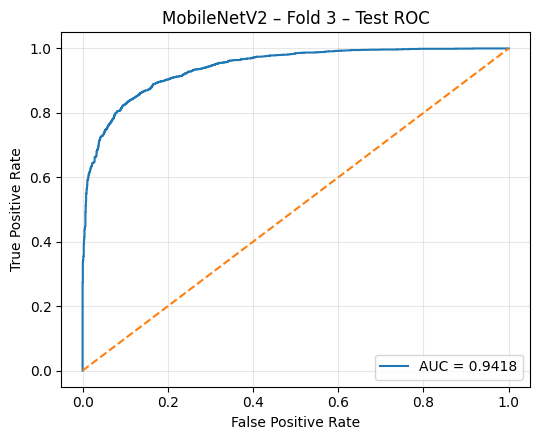

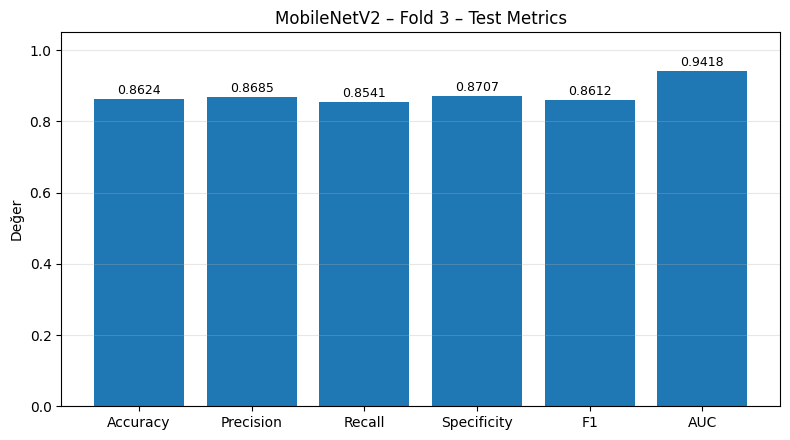

MobileNetV2 – Fold 3 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7400.0,1013.0,910.0,7503.0,0.885713,0.881047,0.891834,0.879591,0.886408,0.958355,0.276000
Validation,3594.0,1536.0,261.0,231.0,1566.0,0.863105,0.857143,0.871452,0.854758,0.864238,0.945481,0.304821
Test,3604.0,1569.0,233.0,263.0,1539.0,0.862375,0.868510,0.854051,0.870699,0.861220,0.941838,0.310954


✓ MobileNetV2 Fold 3: best epoch 10 | Test acc 0.8624
MobileNetV2 | Fold 4 | Epoch 01/10 | Train loss 0.5083 acc 0.7522 | Val loss 0.4426 acc 0.7997
MobileNetV2 | Fold 4 | Epoch 02/10 | Train loss 0.4117 acc 0.8115 | Val loss 0.4346 acc 0.7949
MobileNetV2 | Fold 4 | Epoch 03/10 | Train loss 0.3741 acc 0.8313 | Val loss 0.3870 acc 0.8205
MobileNetV2 | Fold 4 | Epoch 04/10 | Train loss 0.3501 acc 0.8453 | Val loss 0.3629 acc 0.8420
MobileNetV2 | Fold 4 | Epoch 05/10 | Train loss 0.3353 acc 0.8553 | Val loss 0.3687 acc 0.8372
MobileNetV2 | Fold 4 | Epoch 06/10 | Train loss 0.3221 acc 0.8622 | Val loss 0.3648 acc 0.8356
MobileNetV2 | Fold 4 | Epoch 07/10 | Train loss 0.3118 acc 0.8675 | Val loss 0.3580 acc 0.8358
MobileNetV2 | Fold 4 | Epoch 08/10 | Train loss 0.3002 acc 0.8715 | Val loss 0.3252 acc 0.8603
MobileNetV2 | Fold 4 | Epoch 09/10 | Train loss 0.2926 acc 0.8767 | Val loss 0.3200 acc 0.8648
MobileNetV2 | Fold 4 | Epoch 10/10 | Train loss 0.2904 acc 0.8775 | Val loss 0.3114 acc 0.8

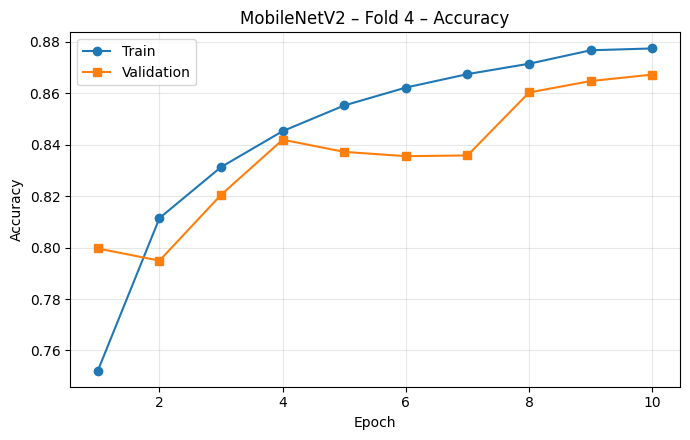

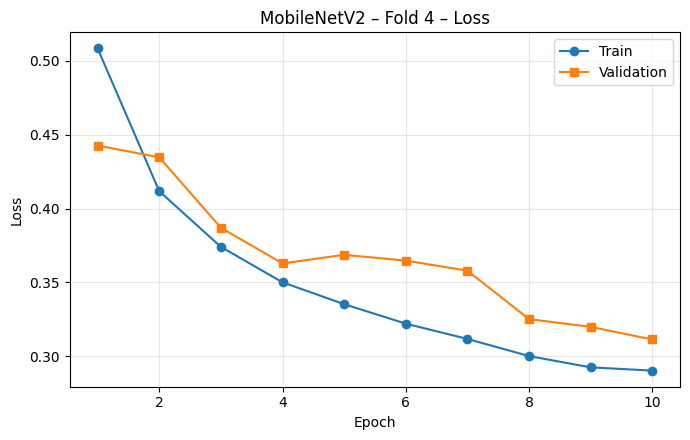

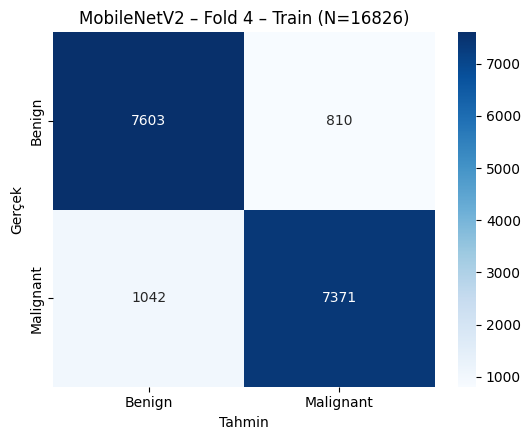

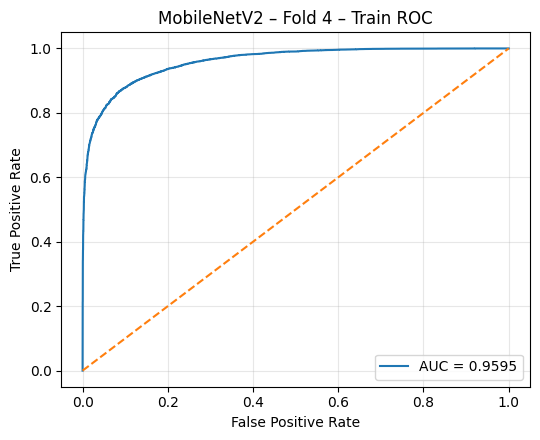

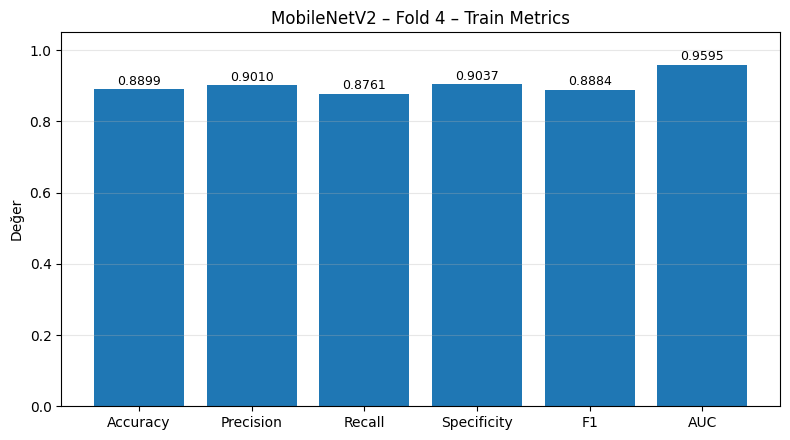

...

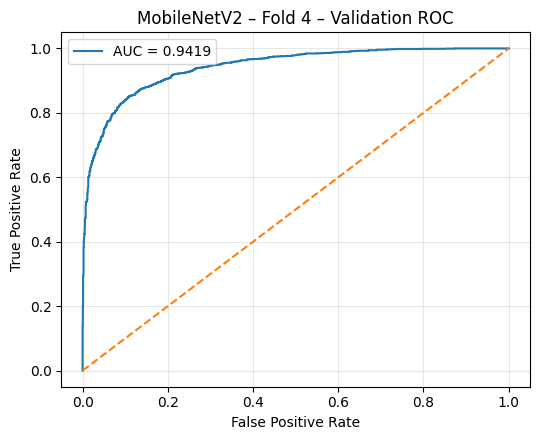

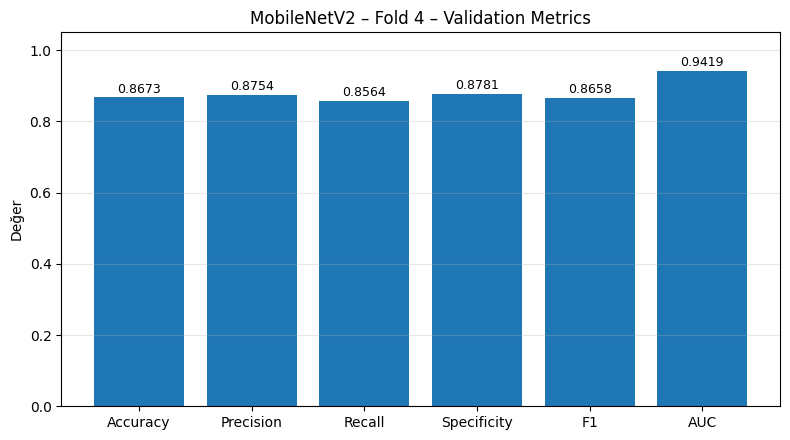

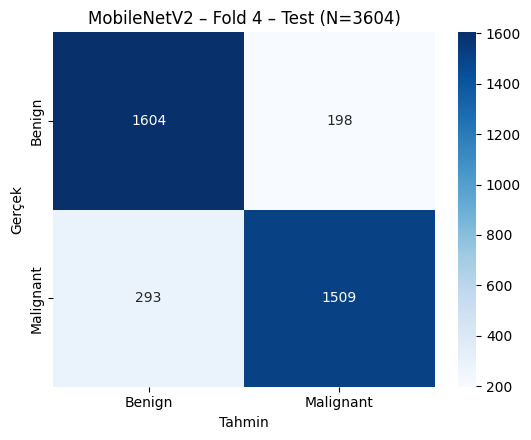

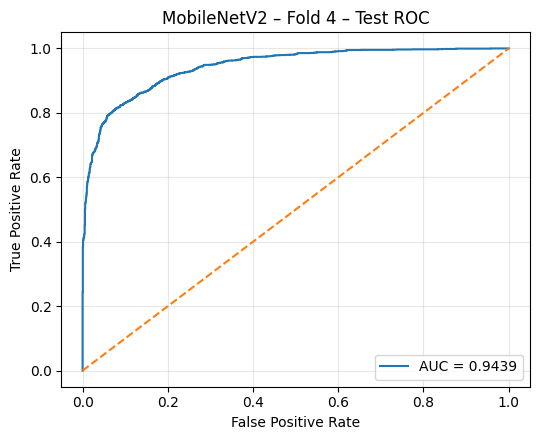

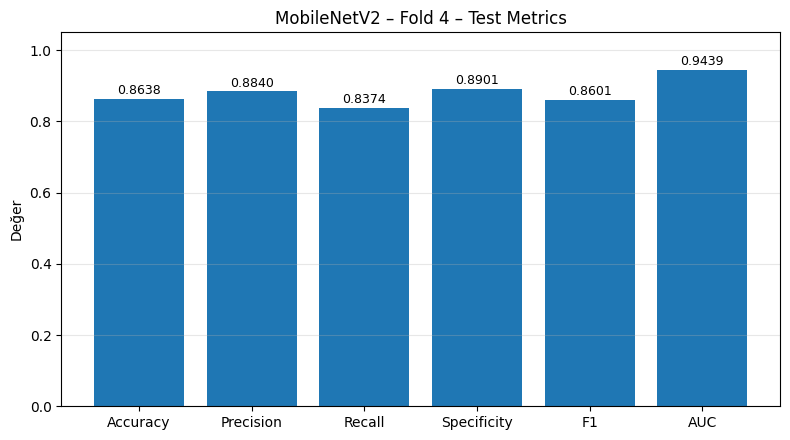

MobileNetV2 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7603.0,810.0,1042.0,7371.0,0.889932,0.900990,0.876144,0.903720,0.888393,0.959531,0.270701
Validation,3594.0,1578.0,219.0,258.0,1539.0,0.867279,0.875427,0.856427,0.878130,0.865823,0.941897,0.311426
Test,3604.0,1604.0,198.0,293.0,1509.0,0.863762,0.884007,0.837403,0.890122,0.860074,0.943929,0.306047


✓ MobileNetV2 Fold 4: best epoch 10 | Test acc 0.8638
MobileNetV2 | Fold 5 | Epoch 01/10 | Train loss 0.5071 acc 0.7494 | Val loss 0.4228 acc 0.8114
MobileNetV2 | Fold 5 | Epoch 02/10 | Train loss 0.4138 acc 0.8152 | Val loss 0.3801 acc 0.8325
MobileNetV2 | Fold 5 | Epoch 03/10 | Train loss 0.3793 acc 0.8321 | Val loss 0.3582 acc 0.8456
MobileNetV2 | Fold 5 | Epoch 04/10 | Train loss 0.3583 acc 0.8449 | Val loss 0.3389 acc 0.8517
MobileNetV2 | Fold 5 | Epoch 05/10 | Train loss 0.3400 acc 0.8559 | Val loss 0.3291 acc 0.8525
MobileNetV2 | Fold 5 | Epoch 06/10 | Train loss 0.3255 acc 0.8606 | Val loss 0.3192 acc 0.8609
MobileNetV2 | Fold 5 | Epoch 07/10 | Train loss 0.3156 acc 0.8656 | Val loss 0.3177 acc 0.8603
MobileNetV2 | Fold 5 | Epoch 08/10 | Train loss 0.3046 acc 0.8717 | Val loss 0.3019 acc 0.8709
MobileNetV2 | Fold 5 | Epoch 09/10 | Train loss 0.2976 acc 0.8732 | Val loss 0.3261 acc 0.8506
MobileNetV2 | Fold 5 | Epoch 10/10 | Train loss 0.2906 acc 0.8790 | Val loss 0.3059 acc 0.8

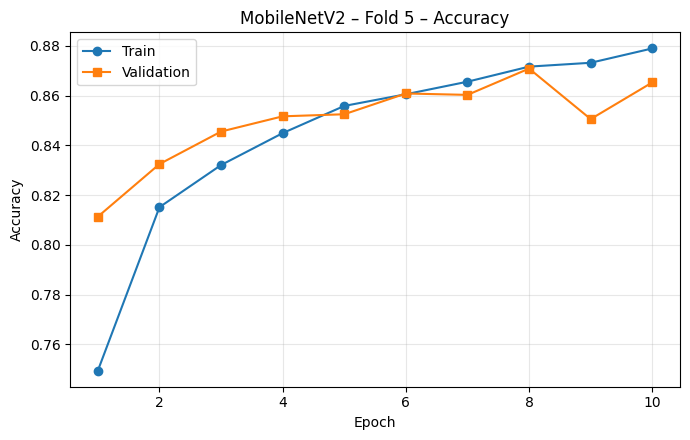

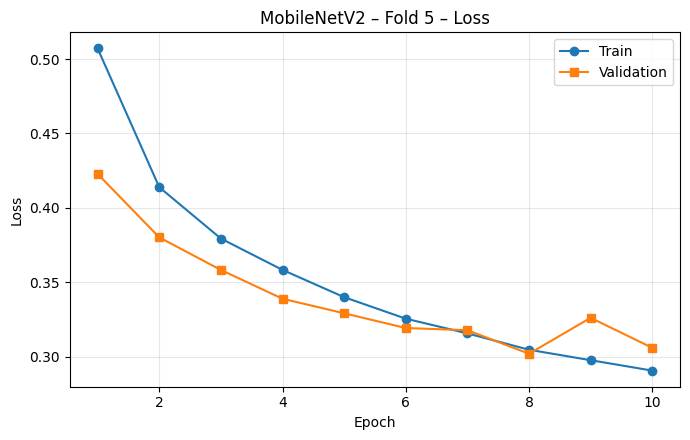

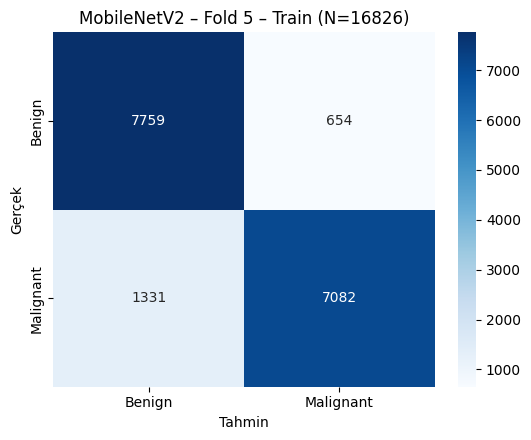

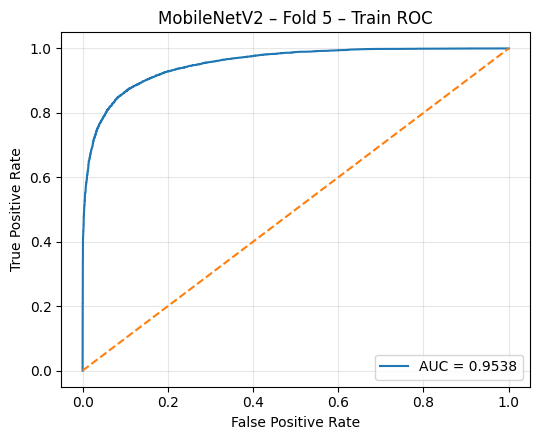

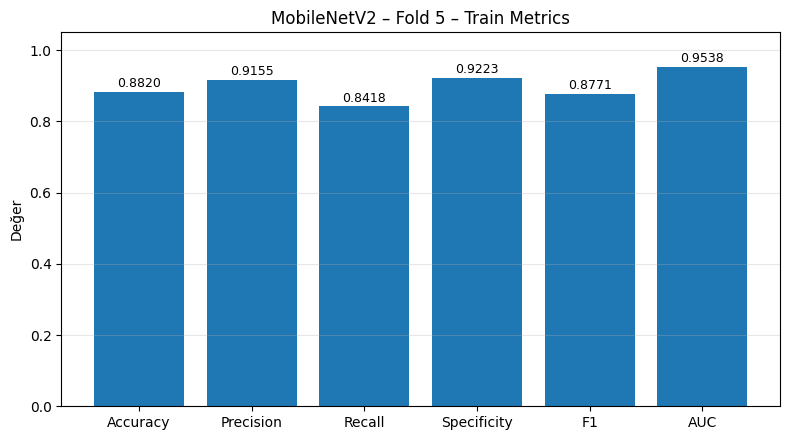

...

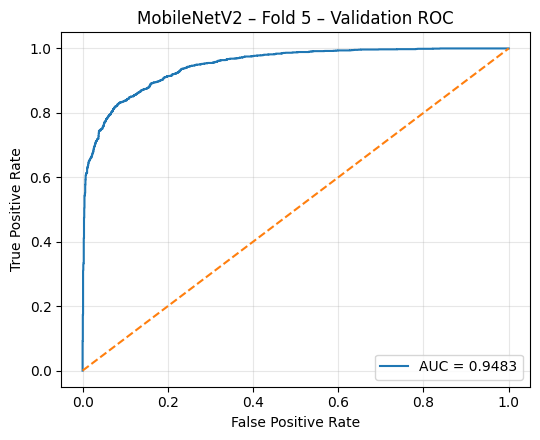

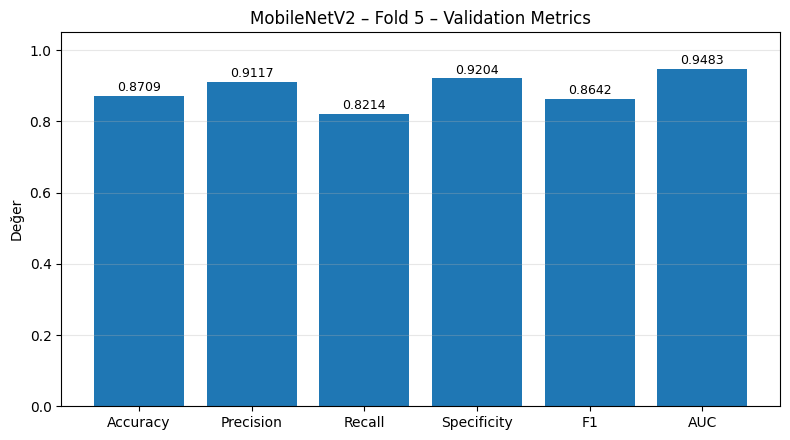

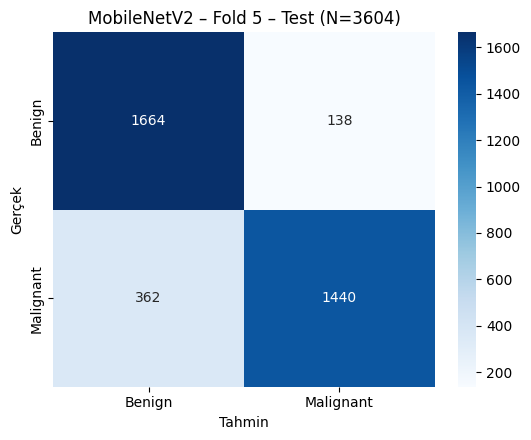

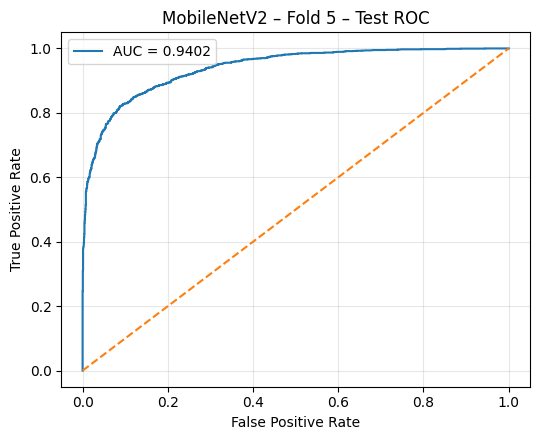

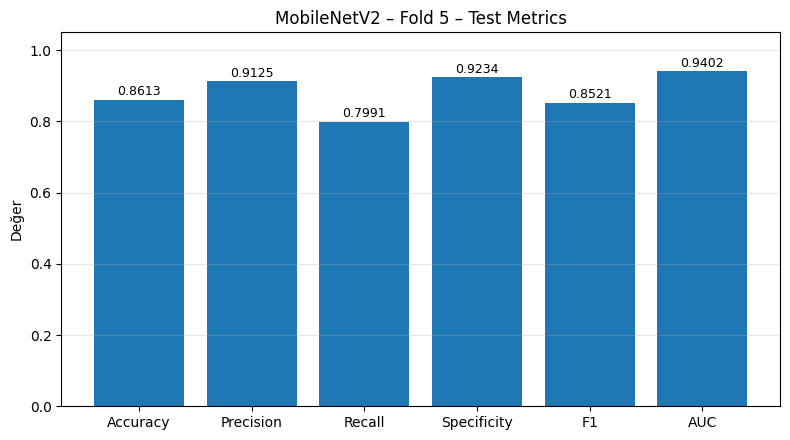

MobileNetV2 – Fold 5 sonuçları (best epoch = 8):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7759.0,654.0,1331.0,7082.0,0.882028,0.915460,0.841792,0.922263,0.877082,0.953790,0.291429
Validation,3594.0,1654.0,143.0,321.0,1476.0,0.870896,0.911674,0.821369,0.920423,0.864169,0.948259,0.301935
Test,3604.0,1664.0,138.0,362.0,1440.0,0.861265,0.912548,0.799112,0.923418,0.852071,0.940164,0.322366


✓ MobileNetV2 Fold 5: best epoch 8 | Test acc 0.8613
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 242MB/s] 


InceptionV3 | Fold 1 | Epoch 01/10 | Train loss 0.5997 acc 0.6731 | Val loss 0.4916 acc 0.7610
InceptionV3 | Fold 1 | Epoch 02/10 | Train loss 0.5586 acc 0.7147 | Val loss 0.5021 acc 0.7532
InceptionV3 | Fold 1 | Epoch 03/10 | Train loss 0.5570 acc 0.7198 | Val loss 0.4611 acc 0.7782
InceptionV3 | Fold 1 | Epoch 04/10 | Train loss 0.5579 acc 0.7219 | Val loss 0.4637 acc 0.7905
InceptionV3 | Fold 1 | Epoch 05/10 | Train loss 0.5554 acc 0.7233 | Val loss 0.4577 acc 0.7755
InceptionV3 | Fold 1 | Epoch 06/10 | Train loss 0.5547 acc 0.7242 | Val loss 0.4508 acc 0.7941
InceptionV3 | Fold 1 | Epoch 07/10 | Train loss 0.5586 acc 0.7239 | Val loss 0.4455 acc 0.8008
InceptionV3 | Fold 1 | Epoch 08/10 | Train loss 0.5647 acc 0.7223 | Val loss 0.4495 acc 0.7947
InceptionV3 | Fold 1 | Epoch 09/10 | Train loss 0.5551 acc 0.7267 | Val loss 0.4377 acc 0.7963
InceptionV3 | Fold 1 | Epoch 10/10 | Train loss 0.5640 acc 0.7182 | Val loss 0.4624 acc 0.7782


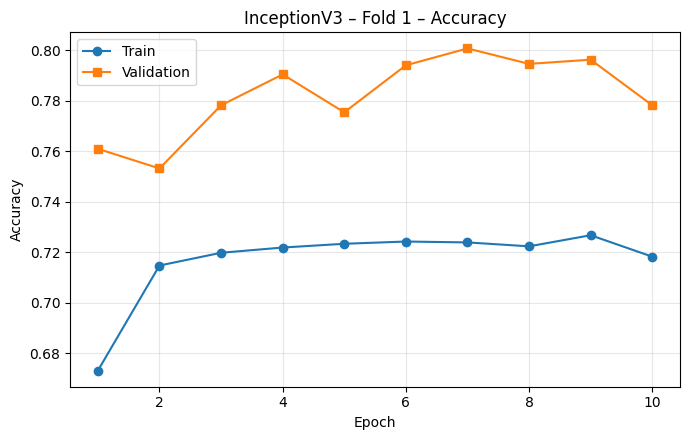

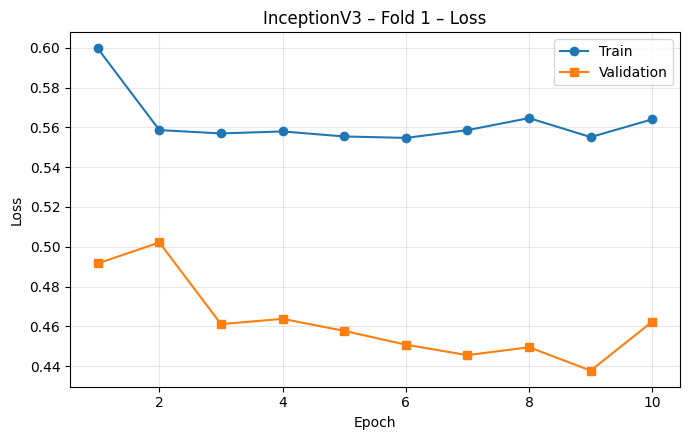

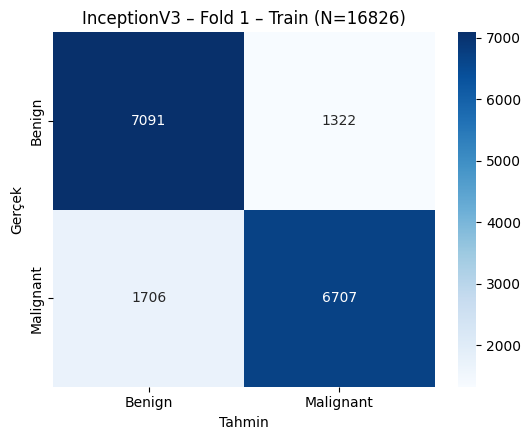

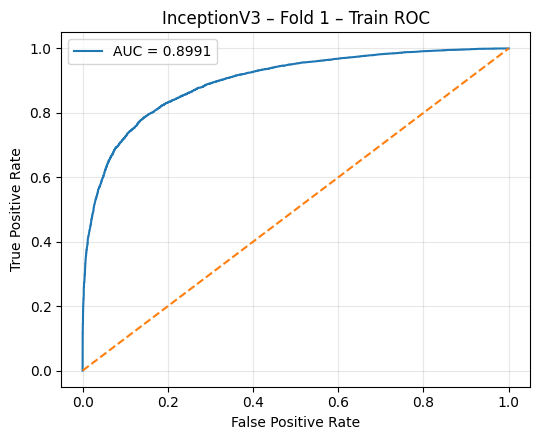

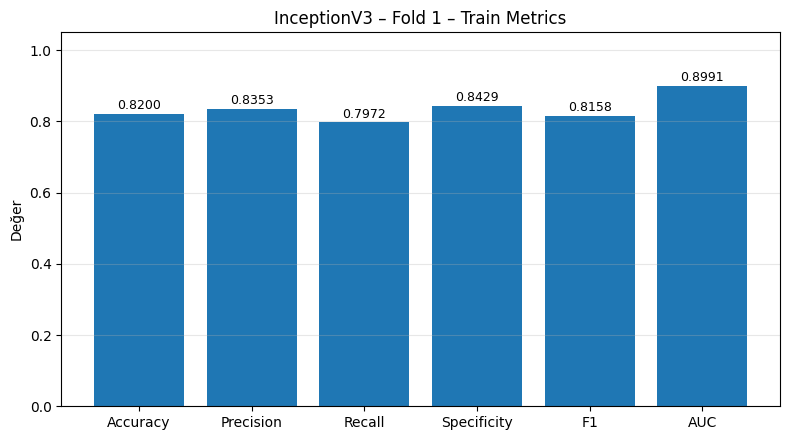

...

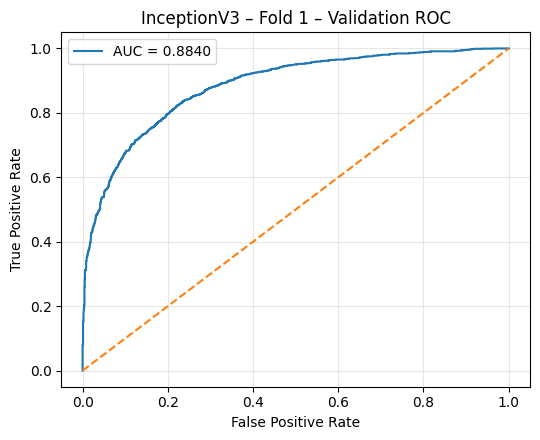

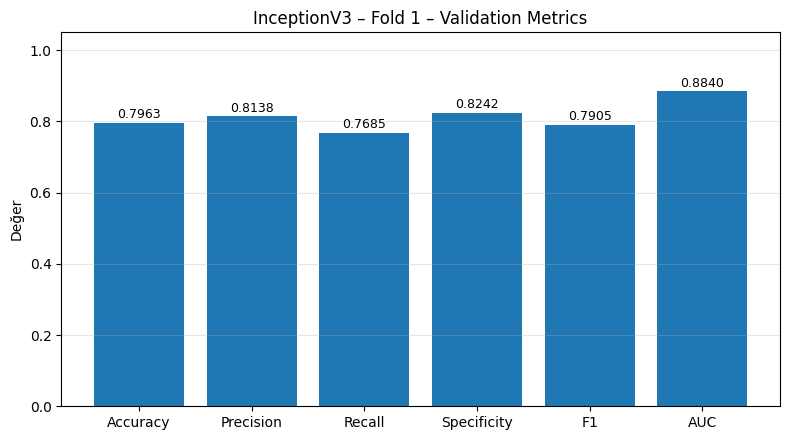

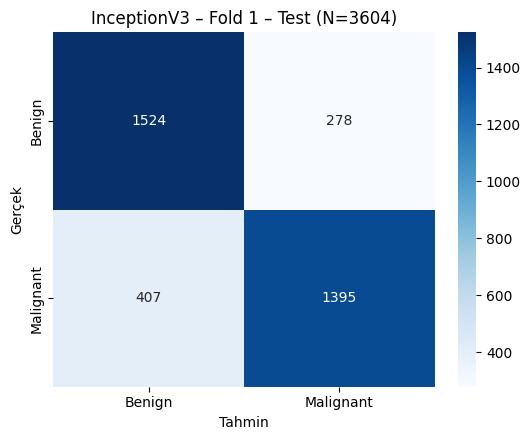

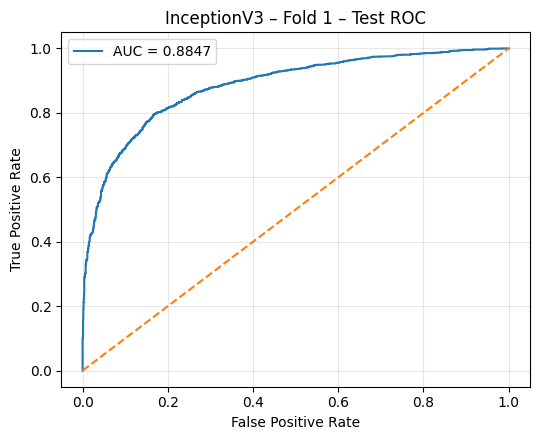

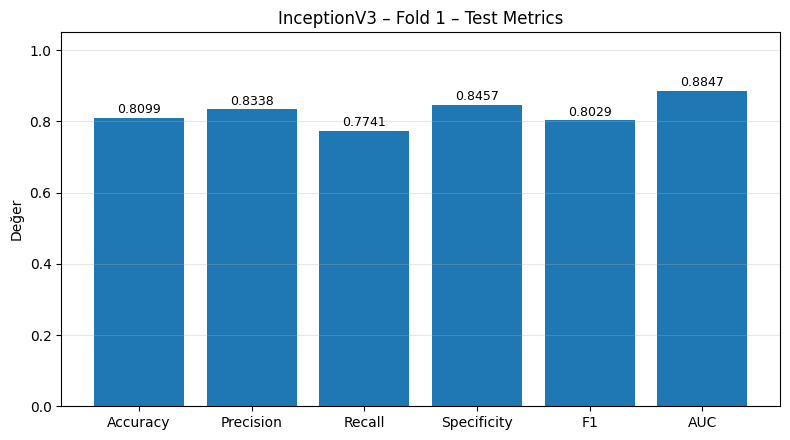

InceptionV3 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7091.0,1322.0,1706.0,6707.0,0.820040,0.835347,0.797219,0.842862,0.815837,0.899074,0.417835
Validation,3594.0,1481.0,316.0,416.0,1381.0,0.796327,0.813789,0.768503,0.824151,0.790498,0.884010,0.437728
Test,3604.0,1524.0,278.0,407.0,1395.0,0.809933,0.833831,0.774140,0.845727,0.802878,0.884748,0.437025


✓ InceptionV3 Fold 1: best epoch 9 | Test acc 0.8099
InceptionV3 | Fold 2 | Epoch 01/10 | Train loss 0.5988 acc 0.6768 | Val loss 0.5069 acc 0.7485
InceptionV3 | Fold 2 | Epoch 02/10 | Train loss 0.5610 acc 0.7139 | Val loss 0.4667 acc 0.7877
InceptionV3 | Fold 2 | Epoch 03/10 | Train loss 0.5526 acc 0.7210 | Val loss 0.4664 acc 0.7794
InceptionV3 | Fold 2 | Epoch 04/10 | Train loss 0.5607 acc 0.7222 | Val loss 0.4644 acc 0.7832
InceptionV3 | Fold 2 | Epoch 05/10 | Train loss 0.5623 acc 0.7217 | Val loss 0.4881 acc 0.7590
InceptionV3 | Fold 2 | Epoch 06/10 | Train loss 0.5606 acc 0.7259 | Val loss 0.4736 acc 0.7713
InceptionV3 | Fold 2 | Epoch 07/10 | Train loss 0.5609 acc 0.7254 | Val loss 0.4539 acc 0.7877
InceptionV3 | Fold 2 | Epoch 08/10 | Train loss 0.5501 acc 0.7307 | Val loss 0.4627 acc 0.7805
InceptionV3 | Fold 2 | Epoch 09/10 | Train loss 0.5536 acc 0.7296 | Val loss 0.4470 acc 0.7947
InceptionV3 | Fold 2 | Epoch 10/10 | Train loss 0.5607 acc 0.7239 | Val loss 0.4793 acc 0.76

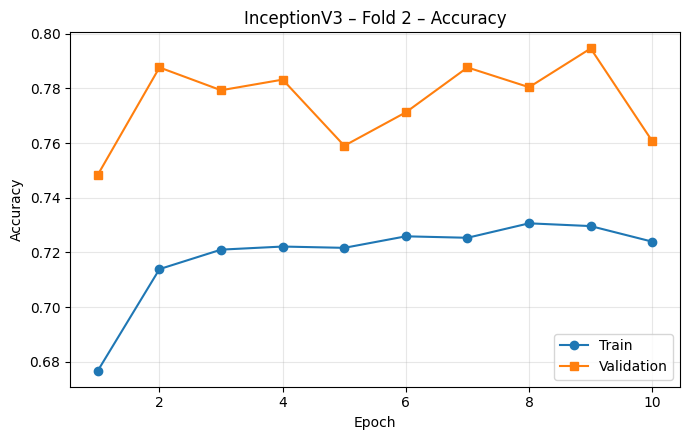

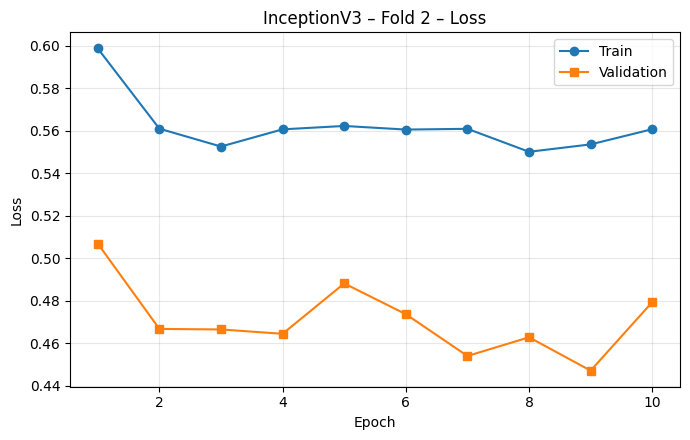

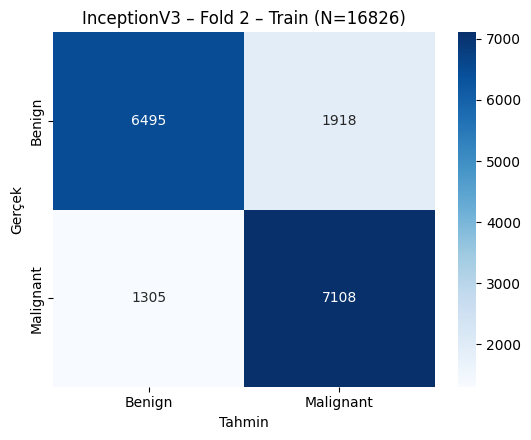

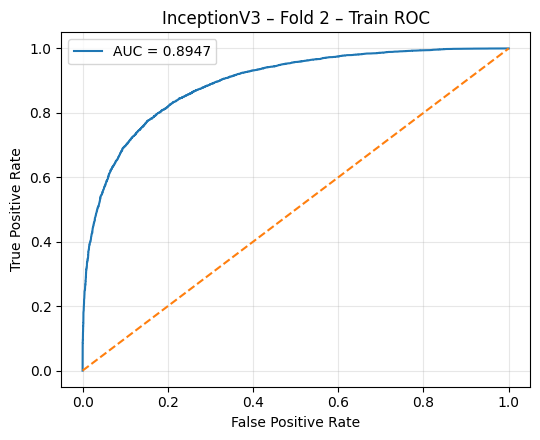

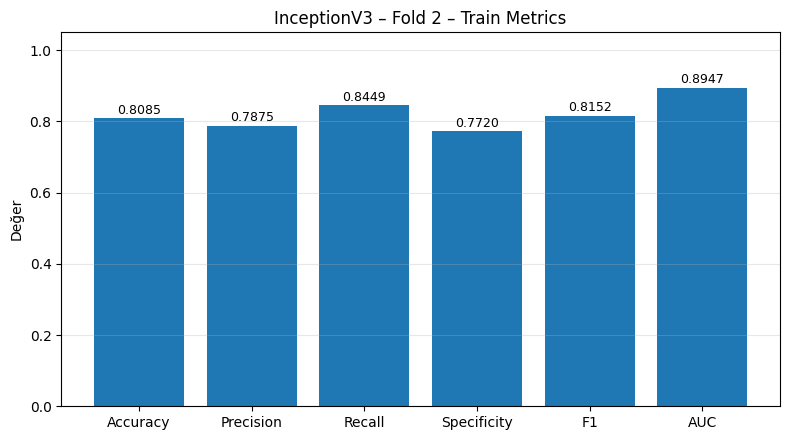

...

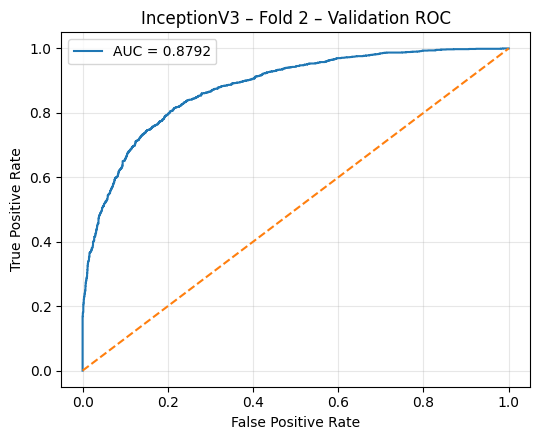

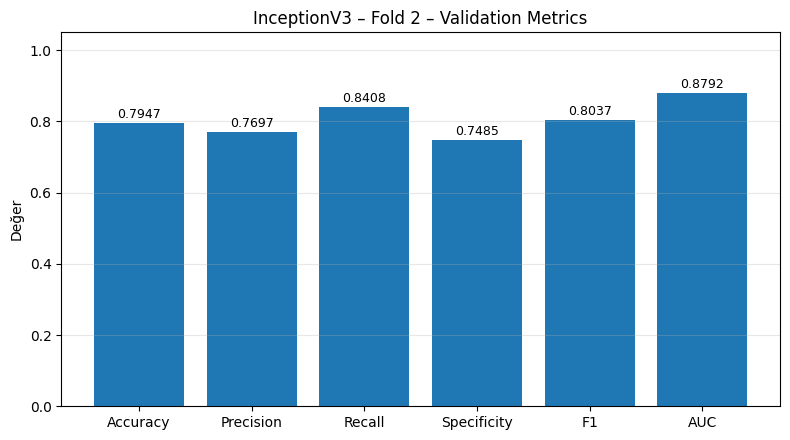

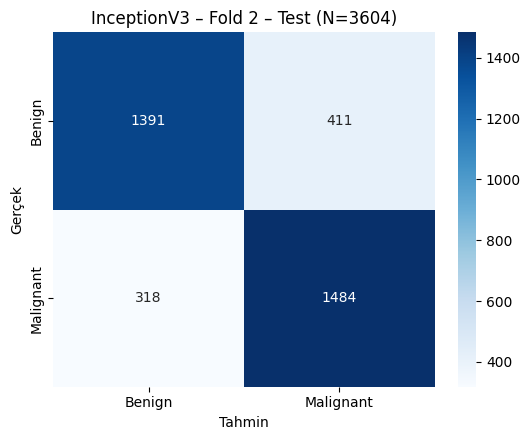

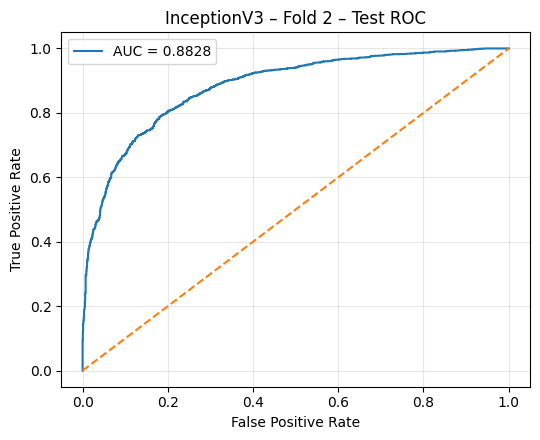

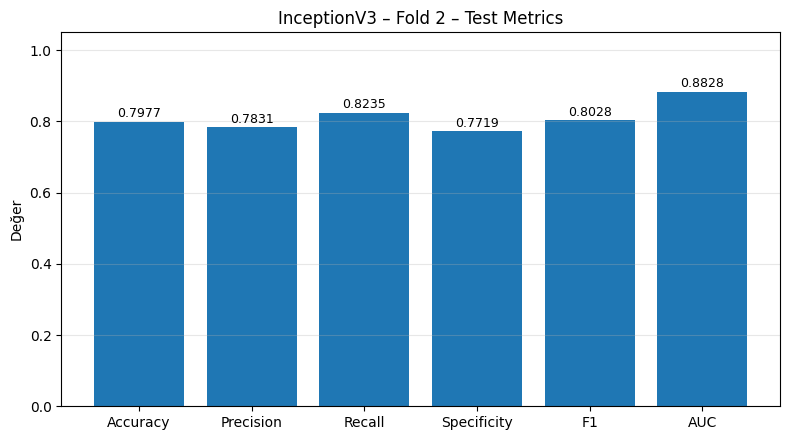

InceptionV3 – Fold 2 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6495.0,1918.0,1305.0,7108.0,0.808451,0.787503,0.844883,0.772019,0.815184,0.894715,0.426006
Validation,3594.0,1345.0,452.0,286.0,1511.0,0.794658,0.769740,0.840846,0.748470,0.803723,0.879198,0.447034
Test,3604.0,1391.0,411.0,318.0,1484.0,0.797725,0.783113,0.823529,0.771920,0.802813,0.882780,0.441566


✓ InceptionV3 Fold 2: best epoch 9 | Test acc 0.7977
InceptionV3 | Fold 3 | Epoch 01/10 | Train loss 0.5983 acc 0.6823 | Val loss 0.4975 acc 0.7551
InceptionV3 | Fold 3 | Epoch 02/10 | Train loss 0.5605 acc 0.7161 | Val loss 0.4535 acc 0.7888
InceptionV3 | Fold 3 | Epoch 03/10 | Train loss 0.5587 acc 0.7192 | Val loss 0.4594 acc 0.7841
InceptionV3 | Fold 3 | Epoch 04/10 | Train loss 0.5654 acc 0.7213 | Val loss 0.4412 acc 0.8013
InceptionV3 | Fold 3 | Epoch 05/10 | Train loss 0.5642 acc 0.7204 | Val loss 0.4944 acc 0.7451
InceptionV3 | Fold 3 | Epoch 06/10 | Train loss 0.5600 acc 0.7195 | Val loss 0.4470 acc 0.7885
InceptionV3 | Fold 3 | Epoch 07/10 | Train loss 0.5599 acc 0.7240 | Val loss 0.4394 acc 0.8058
InceptionV3 | Fold 3 | Epoch 08/10 | Train loss 0.5629 acc 0.7175 | Val loss 0.4772 acc 0.7763
InceptionV3 | Fold 3 | Epoch 09/10 | Train loss 0.5642 acc 0.7245 | Val loss 0.4420 acc 0.8005
InceptionV3 | Fold 3 | Epoch 10/10 | Train loss 0.5656 acc 0.7201 | Val loss 0.5202 acc 0.73

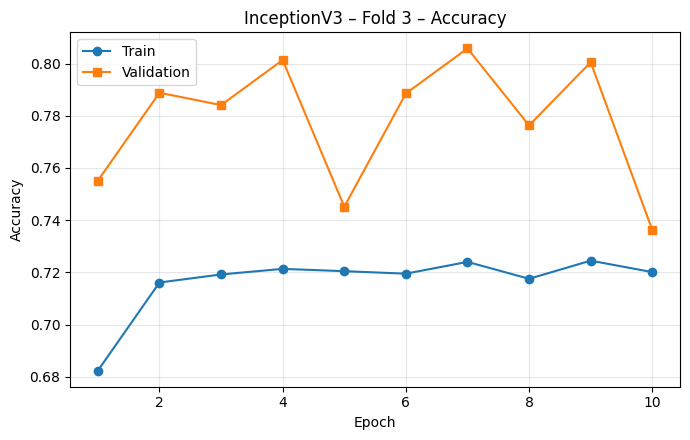

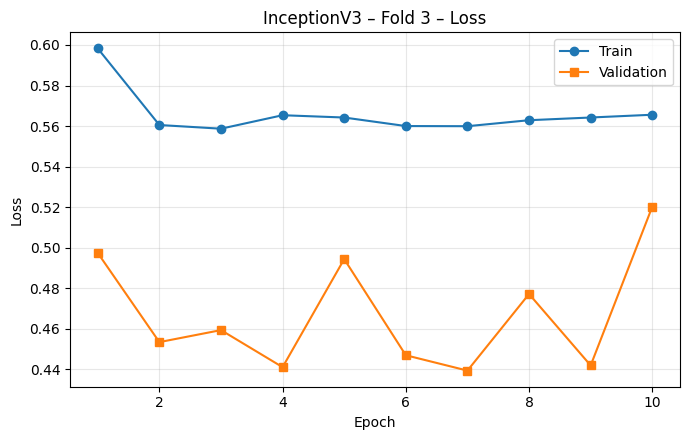

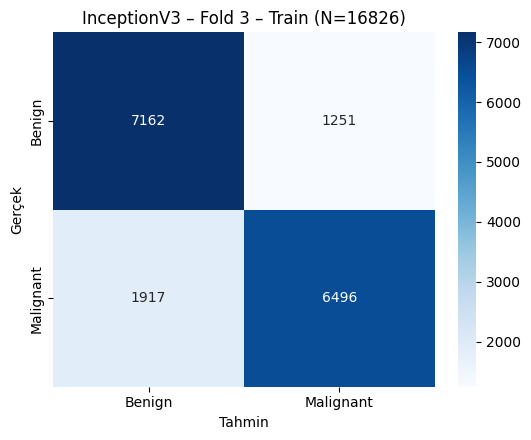

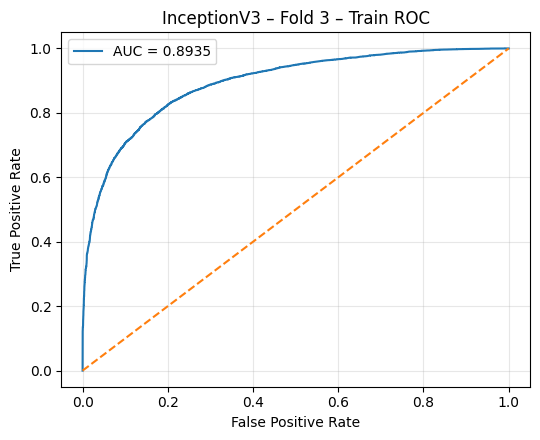

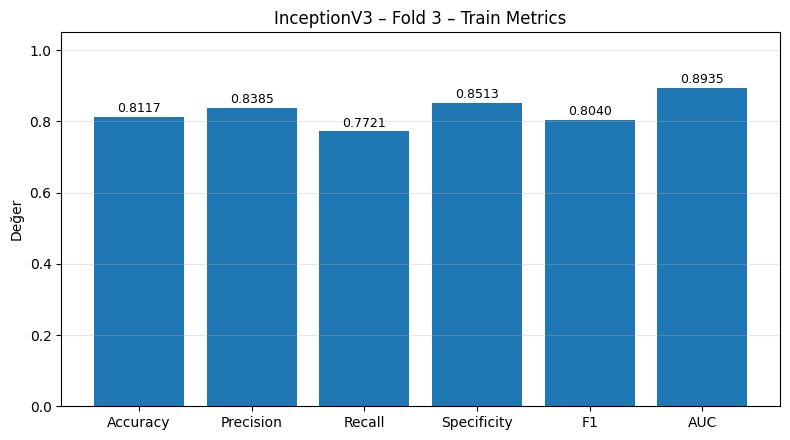

...

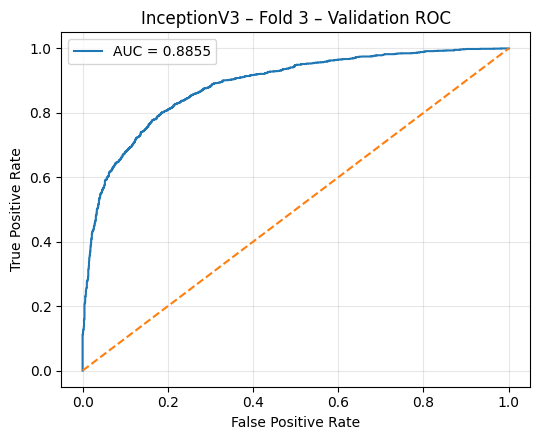

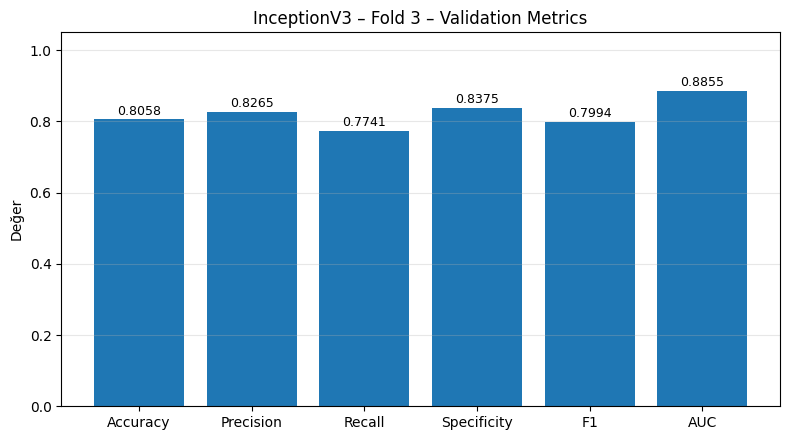

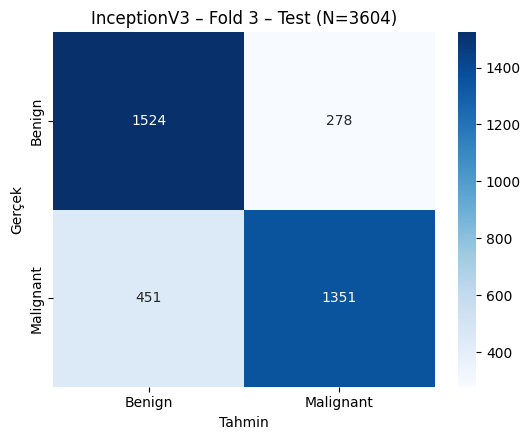

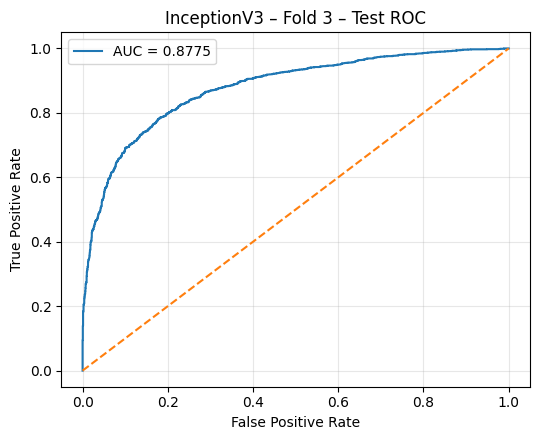

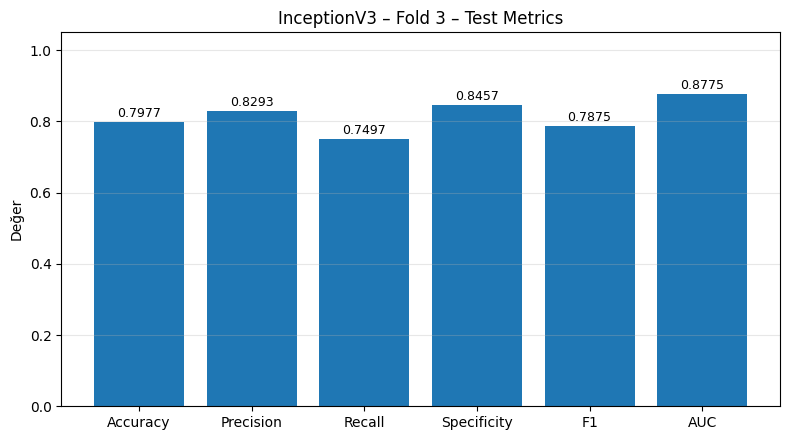

InceptionV3 – Fold 3 sonuçları (best epoch = 7):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7162.0,1251.0,1917.0,6496.0,0.811720,0.838518,0.772138,0.851302,0.803960,0.893472,0.427167
Validation,3594.0,1505.0,292.0,406.0,1391.0,0.805787,0.826500,0.774068,0.837507,0.799425,0.885500,0.439448
Test,3604.0,1524.0,278.0,451.0,1351.0,0.797725,0.829343,0.749723,0.845727,0.787526,0.877525,0.448710


✓ InceptionV3 Fold 3: best epoch 7 | Test acc 0.7977
InceptionV3 | Fold 4 | Epoch 01/10 | Train loss 0.6011 acc 0.6754 | Val loss 0.4987 acc 0.7507
InceptionV3 | Fold 4 | Epoch 02/10 | Train loss 0.5614 acc 0.7143 | Val loss 0.4712 acc 0.7794
InceptionV3 | Fold 4 | Epoch 03/10 | Train loss 0.5475 acc 0.7264 | Val loss 0.4612 acc 0.7877
InceptionV3 | Fold 4 | Epoch 04/10 | Train loss 0.5629 acc 0.7235 | Val loss 0.4714 acc 0.7746
InceptionV3 | Fold 4 | Epoch 05/10 | Train loss 0.5551 acc 0.7288 | Val loss 0.5644 acc 0.6856
InceptionV3 | Fold 4 | Epoch 06/10 | Train loss 0.5564 acc 0.7263 | Val loss 0.4551 acc 0.7844
InceptionV3 | Fold 4 | Epoch 07/10 | Train loss 0.5648 acc 0.7236 | Val loss 0.4551 acc 0.7835
InceptionV3 | Fold 4 | Epoch 08/10 | Train loss 0.5506 acc 0.7235 | Val loss 0.4959 acc 0.7423
InceptionV3 | Fold 4 | Epoch 09/10 | Train loss 0.5559 acc 0.7284 | Val loss 0.4492 acc 0.7877
InceptionV3 | Fold 4 | Epoch 10/10 | Train loss 0.5601 acc 0.7247 | Val loss 0.5166 acc 0.74

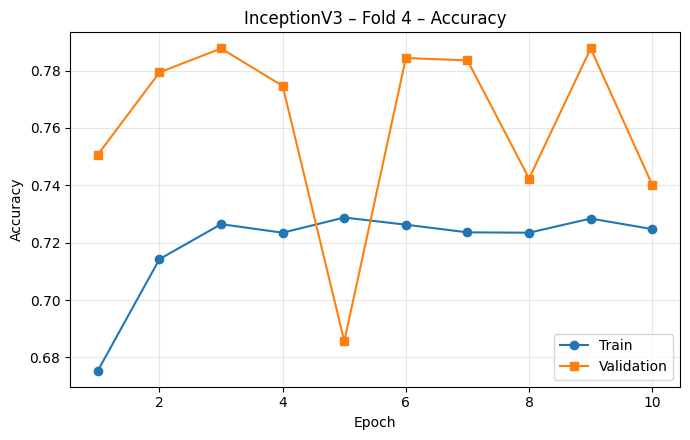

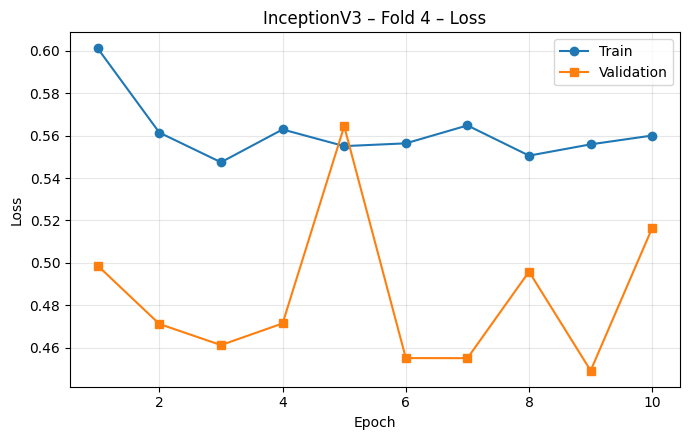

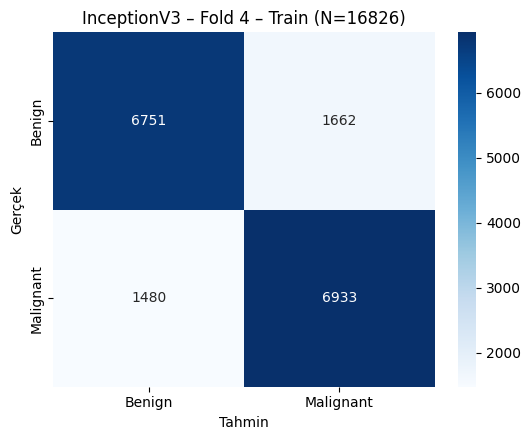

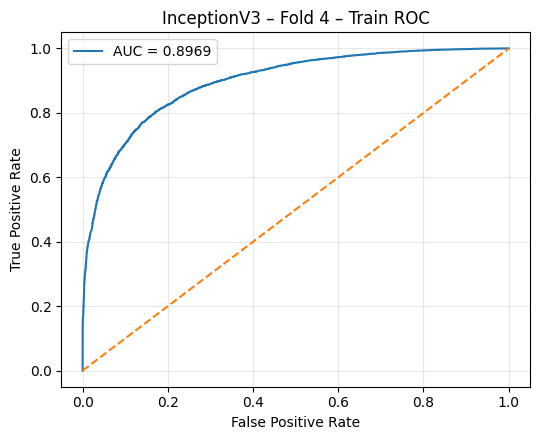

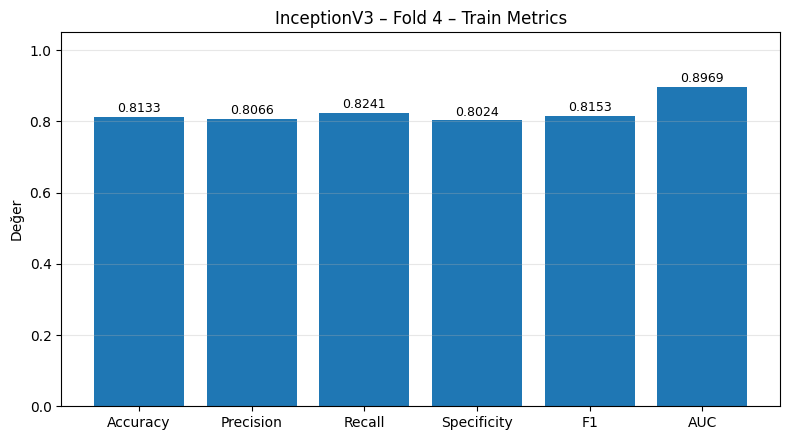

...

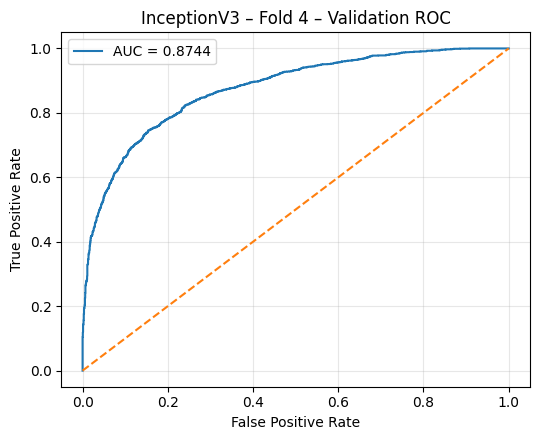

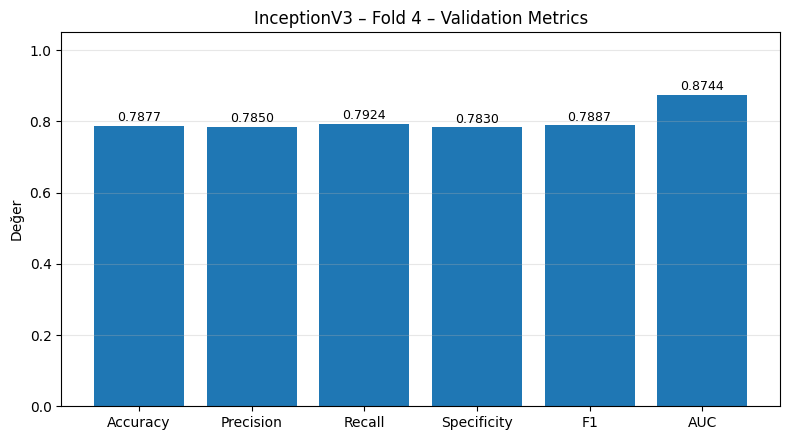

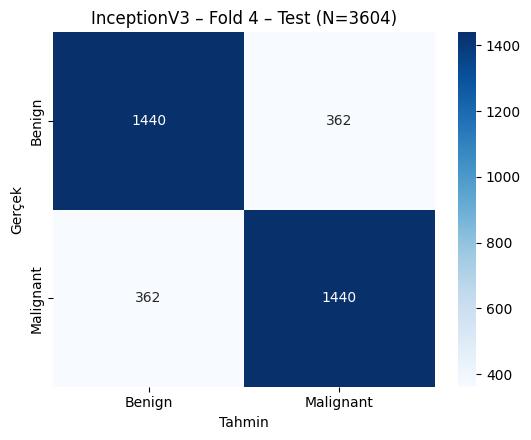

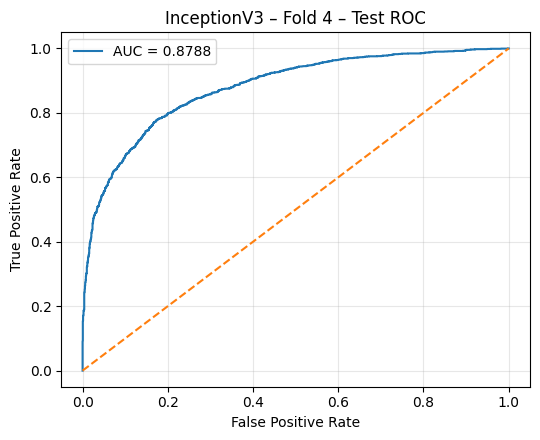

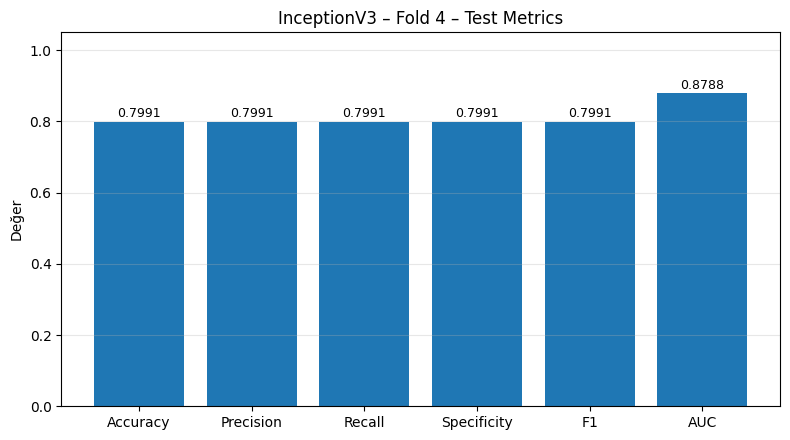

InceptionV3 – Fold 4 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6751.0,1662.0,1480.0,6933.0,0.813265,0.806632,0.824082,0.802449,0.815263,0.896909,0.421199
Validation,3594.0,1407.0,390.0,373.0,1424.0,0.787702,0.785006,0.792432,0.782972,0.788701,0.874437,0.449187
Test,3604.0,1440.0,362.0,362.0,1440.0,0.799112,0.799112,0.799112,0.799112,0.799112,0.878797,0.444341


✓ InceptionV3 Fold 4: best epoch 9 | Test acc 0.7991
InceptionV3 | Fold 5 | Epoch 01/10 | Train loss 0.5997 acc 0.6747 | Val loss 0.4892 acc 0.7668
InceptionV3 | Fold 5 | Epoch 02/10 | Train loss 0.5632 acc 0.7110 | Val loss 0.4591 acc 0.7746
InceptionV3 | Fold 5 | Epoch 03/10 | Train loss 0.5530 acc 0.7254 | Val loss 0.4540 acc 0.7813
InceptionV3 | Fold 5 | Epoch 04/10 | Train loss 0.5626 acc 0.7216 | Val loss 0.4649 acc 0.7702
InceptionV3 | Fold 5 | Epoch 05/10 | Train loss 0.5603 acc 0.7223 | Val loss 0.4605 acc 0.7794
InceptionV3 | Fold 5 | Epoch 06/10 | Train loss 0.5629 acc 0.7222 | Val loss 0.4384 acc 0.8002
InceptionV3 | Fold 5 | Epoch 07/10 | Train loss 0.5726 acc 0.7195 | Val loss 0.4399 acc 0.7938
InceptionV3 | Fold 5 | Epoch 08/10 | Train loss 0.5561 acc 0.7262 | Val loss 0.4450 acc 0.7949
InceptionV3 | Fold 5 | Epoch 09/10 | Train loss 0.5578 acc 0.7254 | Val loss 0.4309 acc 0.8038
InceptionV3 | Fold 5 | Epoch 10/10 | Train loss 0.5636 acc 0.7222 | Val loss 0.4506 acc 0.78

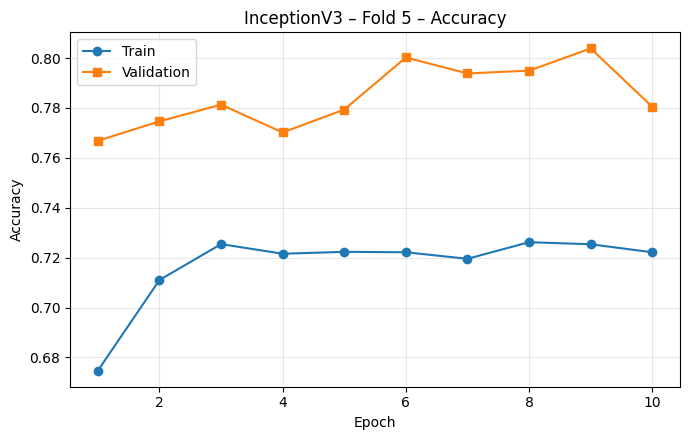

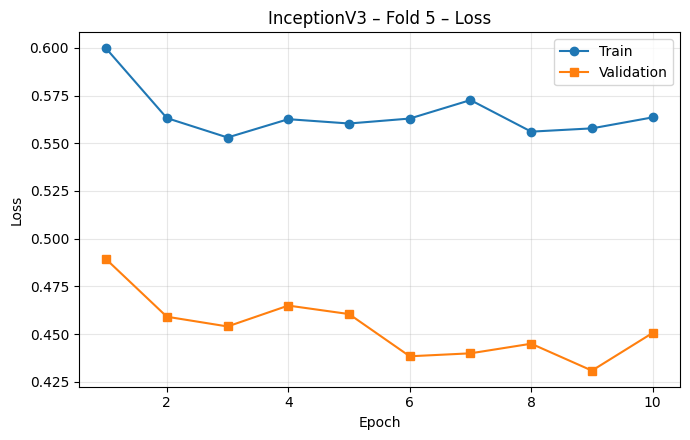

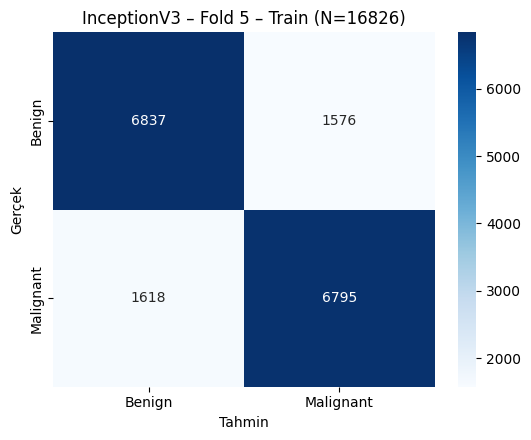

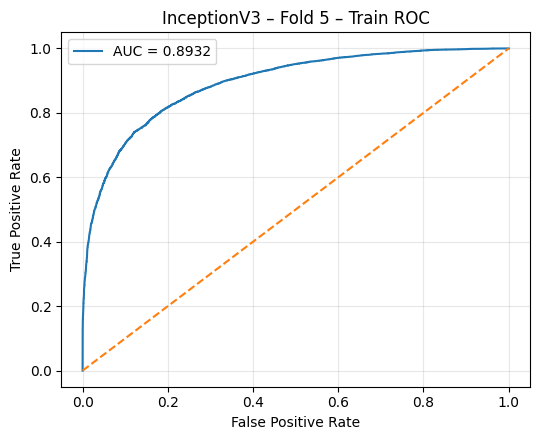

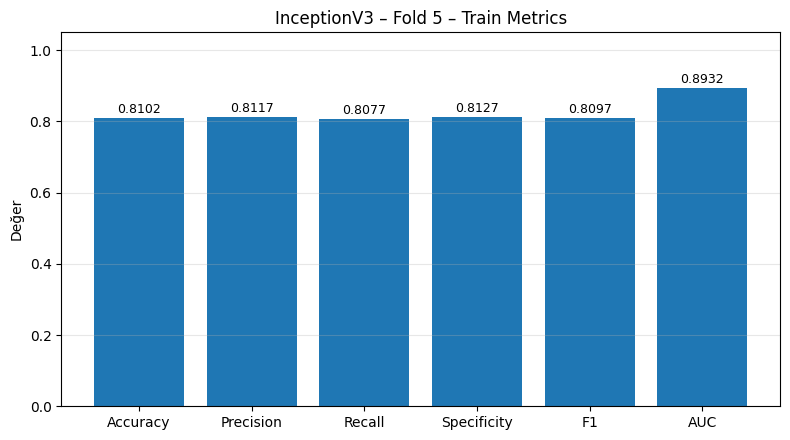

...

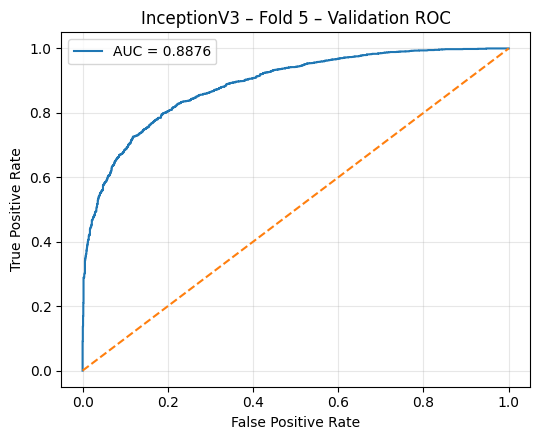

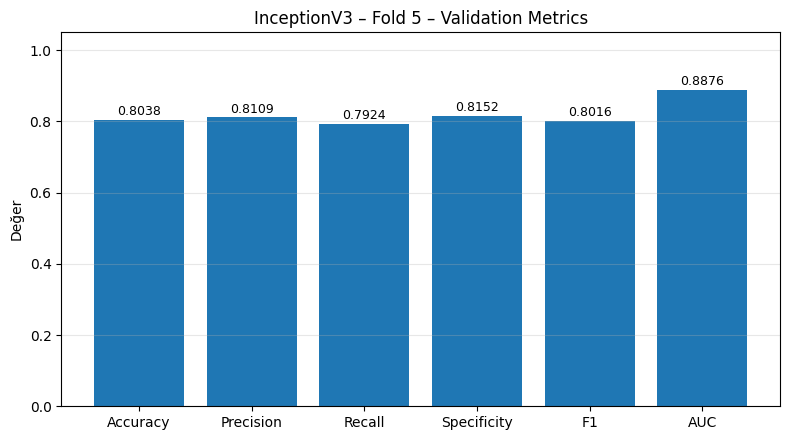

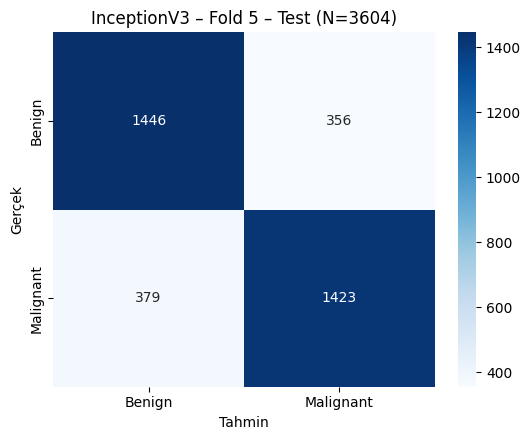

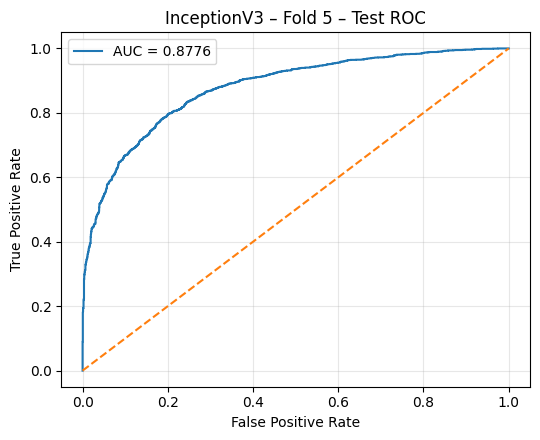

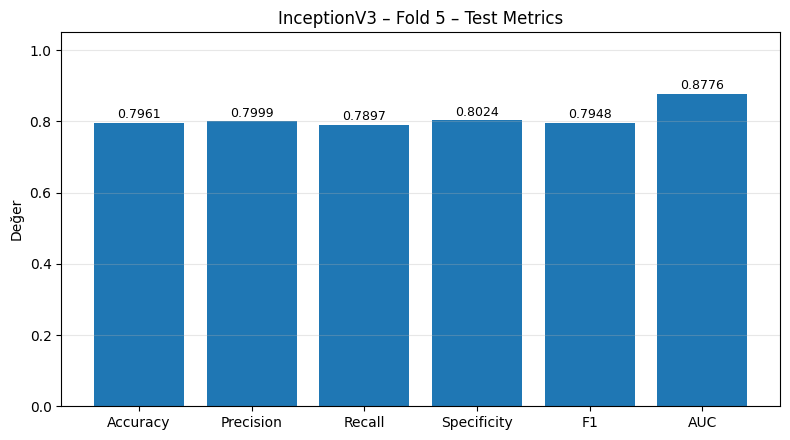

InceptionV3 – Fold 5 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6837.0,1576.0,1618.0,6795.0,0.810175,0.811731,0.807679,0.812671,0.809700,0.893217,0.425976
Validation,3594.0,1465.0,332.0,373.0,1424.0,0.803840,0.810934,0.792432,0.815248,0.801576,0.887603,0.430865
Test,3604.0,1446.0,356.0,379.0,1423.0,0.796060,0.799888,0.789678,0.802442,0.794750,0.877586,0.445363


✓ InceptionV3 Fold 5: best epoch 9 | Test acc 0.7961


,Group,Model,Split,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC
2,baseline_cnn,ResNet34,Test,81.62 ± 0.21,83.13 ± 2.29,79.52 ± 3.37,83.72 ± 3.38,81.21 ± 0.67,89.69 ± 0.06
5,baseline_cnn,DenseNet121,Test,82.39 ± 0.14,84.12 ± 2.29,80.03 ± 3.29,84.75 ± 3.14,81.95 ± 0.69,90.87 ± 0.07
8,baseline_cnn,EfficientNet-B0,Test,88.70 ± 0.12,88.87 ± 1.14,88.51 ± 1.35,88.89 ± 1.45,88.68 ± 0.15,95.80 ± 0.21
11,baseline_cnn,MobileNetV2,Test,86.42 ± 0.28,88.05 ± 2.20,84.42 ± 3.00,88.42 ± 2.76,86.13 ± 0.60,94.28 ± 0.18
14,baseline_cnn,InceptionV3,Test,80.01 ± 0.56,80.91 ± 2.17,78.72 ± 2.76,81.30 ± 3.21,79.74 ± 0.65,88.03 ± 0.33


In [4]:
# ======================= 4. ÇALIŞTIR =======================
KIND, FAM = GROUP.split("_")
models_to_run = MODELS or (CNN_MODELS if FAM == "cnn" else VIT_MODELS)
assert all(FAMILY[m] == FAM for m in models_to_run), "Seçilen modeller gruba uymuyor"
if RERUN:
    assert MODELS, "RERUN=True için yeniden eğitilecek modelleri MODELS listesinde ver"
    for m in MODELS:
        d = OUTPUT_ROOT / CV_MODE / GROUP / m
        if d.exists():
            shutil.rmtree(d); print(f"Eski sonuçlar silindi, yeniden eğitilecek: {d}")

(OUTPUT_ROOT / CV_MODE / GROUP).mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / CV_MODE / GROUP / "config.json").write_text(json.dumps({
    "GROUP": GROUP, "COMMON": COMMON, "RECIPE": RECIPES[KIND], "FT_SCOPE": FT_SCOPE[(KIND, FAM)],
    "AUGMENT": AUGMENT if RECIPES[KIND]["augment"] else None, "CV_MODE": CV_MODE, "N_FOLDS": N_FOLDS, "FOLD_SEED": FOLD_SEED, "TRAIN_SEED": TRAIN_SEED,
    "fold_counts": fold_table.to_dict("records"), "VIT_LAST_BLOCKS": VIT_LAST_BLOCKS,
    "torch": torch.__version__, "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "kaggle_split_counts": {s: len(d) for s, d in DS.items()}}, indent=2, default=str))

results = []
for name in models_to_run:
    for fold in range(1, N_FOLDS + 1):
        results.append(run_one(name, fold, KIND))

per_run, summary, article = results_to_frames(results)
with pd.ExcelWriter(OUTPUT_ROOT / CV_MODE / GROUP / f"{GROUP}_results.xlsx") as xw:
    per_run.to_excel(xw, sheet_name="Fold bazlı", index=False)
    summary.to_excel(xw, sheet_name="Ortalama-Std", index=False)
    article.to_excel(xw, sheet_name="Makale tablosu", index=False)
display(article[article.Split == "Test"])
